In [15]:
!curl -fL https://files.wundernn.io/wnn_connectome_starterpack.tar.gz | tar -xz

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.pr

In [2]:
!curl -fL https://files.wundernn.io/wnn_connectome_starterpack.tar.gz | tar -xz wnn_connectome_starterpack/datasets/valid.parquet

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.pr

In [16]:

from pathlib import Path
import pyarrow.parquet as pq

root = Path("/content/wnn_connectome_starterpack/datasets")

print("=== ПРОВЕРКА ДАННЫХ ALFA CONNECTOME ===\n")

for filename in ["train.parquet", "valid.parquet"]:
    path = root / filename
    print(f"Файл: {filename}")

    if not path.is_file():
        print("❌ Файл не найден\n")
        continue

    print(f"Размер: {path.stat().st_size / 1024**3:.3f} ГБ")

    try:
        pf = pq.ParquetFile(path)

        print(f"Последовательностей: {pf.num_row_groups}")
        print(f"Строк: {pf.metadata.num_rows:,}")
        print(f"Столбцов: {len(pf.schema_arrow.names)}")

        # Проверяем чтение начала и конца файла
        for idx in [0, pf.num_row_groups - 1]:
            table = pf.read_row_group(
                idx, columns=["step_in_seq", "t0", "t1"]
            )
            assert table.num_rows == 20_000
            print(f"✓ Последовательность {idx} читается")

        print("✅ Первичная проверка пройдена\n")

    except Exception as e:
        print(f"❌ Ошибка: {type(e).__name__}: {e}\n")


=== ПРОВЕРКА ДАННЫХ ALFA CONNECTOME ===

Файл: train.parquet
Размер: 27.232 ГБ
Последовательностей: 10607
Строк: 212,140,000
Столбцов: 117
✓ Последовательность 0 читается
✓ Последовательность 10606 читается
✅ Первичная проверка пройдена

Файл: valid.parquet
Размер: 4.364 ГБ
❌ Ошибка: ArrowInvalid: Parquet magic bytes not found in footer. Either the file is corrupted or this is not a parquet file.



## НАЧАЛО----------------------

In [17]:

import pyarrow.parquet as pq

train_path = "/content/wnn_connectome_starterpack/datasets/train.parquet"
pf = pq.ParquetFile(train_path)

print("=== СТРУКТУРА TRAIN.PARQUET ===")

print("\nВсе столбцы:")
print(pf.schema_arrow.names)

print("\nКоличество последовательностей:", pf.num_row_groups)
print("Количество строк:", pf.metadata.num_rows)

print("\n=== ПЕРВЫЕ 5 СТРОК ===")

sample = pf.read_row_group(0).to_pandas()
display(sample.head(5))

print("\n=== ПРОПУСКИ В ПЕРВОЙ ПОСЛЕДОВАТЕЛЬНОСТИ ===")
print(sample.isna().sum().sort_values(ascending=False).head(15))


=== СТРУКТУРА TRAIN.PARQUET ===

Все столбцы:
['seq_ix', 'step_in_seq', 'need_prediction', 'i0_p0', 'i0_p1', 'i0_p2', 'i0_p3', 'i0_p4', 'i0_p5', 'i0_p6', 'i0_p7', 'i0_p8', 'i0_p9', 'i0_p10', 'i0_p11', 'i0_p12', 'i0_p13', 'i0_p14', 'i0_p15', 'i0_p16', 'i0_p17', 'i0_p18', 'i0_p19', 'i0_p20', 'i0_p21', 'i0_v0', 'i0_v1', 'i0_v2', 'i0_v3', 'i0_v4', 'i0_v5', 'i0_v6', 'i0_v7', 'i0_v8', 'i0_v9', 'i0_v10', 'i0_v11', 'i0_v12', 'i0_v13', 'i0_v14', 'i0_v15', 'i0_v16', 'i0_v17', 'i0_v18', 'i0_v19', 'i0_v20', 'i0_v21', 'i0_dp0', 'i0_dp1', 'i0_dp2', 'i0_dp3', 'i0_dv0', 'i0_dv1', 'i0_dv2', 'i0_dv3', 'i1_p0', 'i1_p1', 'i1_p2', 'i1_p3', 'i1_p4', 'i1_p5', 'i1_p6', 'i1_p7', 'i1_p8', 'i1_p9', 'i1_p10', 'i1_p11', 'i1_p12', 'i1_p13', 'i1_p14', 'i1_p15', 'i1_p16', 'i1_p17', 'i1_p18', 'i1_p19', 'i1_p20', 'i1_p21', 'i1_v0', 'i1_v1', 'i1_v2', 'i1_v3', 'i1_v4', 'i1_v5', 'i1_v6', 'i1_v7', 'i1_v8', 'i1_v9', 'i1_v10', 'i1_v11', 'i1_v12', 'i1_v13', 'i1_v14', 'i1_v15', 'i1_v16', 'i1_v17', 'i1_v18', 'i1_v19', 'i1_v20',

,seq_ix,step_in_seq,need_prediction,i0_p0,i0_p1,i0_p2,i0_p3,i0_p4,i0_p5,i0_p6,...,a0,a1,a2,a3,a4,a5,a6,a7,t0,t1
0,43601,0,False,-1.476388,0.175072,0.399079,-1.475372,-0.13971,0.872424,-0.300691,...,-0.273794,0.340235,-1.535839,-1.408943,0.276890,0.749410,1.156311,0.698526,1.003465,-0.878032
1,43601,1,False,-1.476388,0.175072,0.399079,-1.475372,-0.13971,0.872424,-0.300691,...,-0.152641,0.450260,-1.510688,-1.411975,0.792433,0.749504,1.156352,-5.199337,1.003465,-0.878032
2,43601,2,False,-1.476388,0.175072,0.399079,-1.475372,-0.13971,0.872424,-0.300691,...,-0.340227,-0.624428,-1.546302,-1.417763,0.126775,0.749531,1.156362,0.389414,1.003465,-0.878032
3,43601,3,False,-1.476388,0.175072,0.399079,-1.475372,-0.13971,0.872424,-0.300691,...,-0.420239,-0.262633,-1.589254,-1.423840,0.023200,0.749548,1.156370,0.698526,1.003465,-0.878032
4,43601,4,False,-1.476388,0.175072,0.399079,-1.475372,-0.13971,0.872424,-0.300691,...,-0.084216,0.912597,-1.490083,-1.423417,1.246191,0.749719,1.156443,-5.199337,1.003465,-0.878032



=== ПРОПУСКИ В ПЕРВОЙ ПОСЛЕДОВАТЕЛЬНОСТИ ===
seq_ix             0
step_in_seq        0
need_prediction    0
i0_p0              0
i0_p1              0
i0_p2              0
i0_p3              0
i0_p4              0
i0_p5              0
i0_p6              0
i0_p7              0
i0_p8              0
i0_p9              0
i0_p10             0
i0_p11             0
dtype: int64


=== АНАЛИЗ ПЕРВОЙ ПОСЛЕДОВАТЕЛЬНОСТИ ===
ID: 43601
Длина: 20000
Шагов с need_prediction: 19901
Всего пропусков: 0

t0:
  Среднее: 0.1075
  Стандартное отклонение: 0.7381
  Минимум: -2.3832
  Максимум: 3.0104
  Уникальных значений: 44
  Доля изменений: 11.03%

t1:
  Среднее: -0.1293
  Стандартное отклонение: 0.7157
  Минимум: -2.1324
  Максимум: 2.3832
  Уникальных значений: 36
  Доля изменений: 11.32%


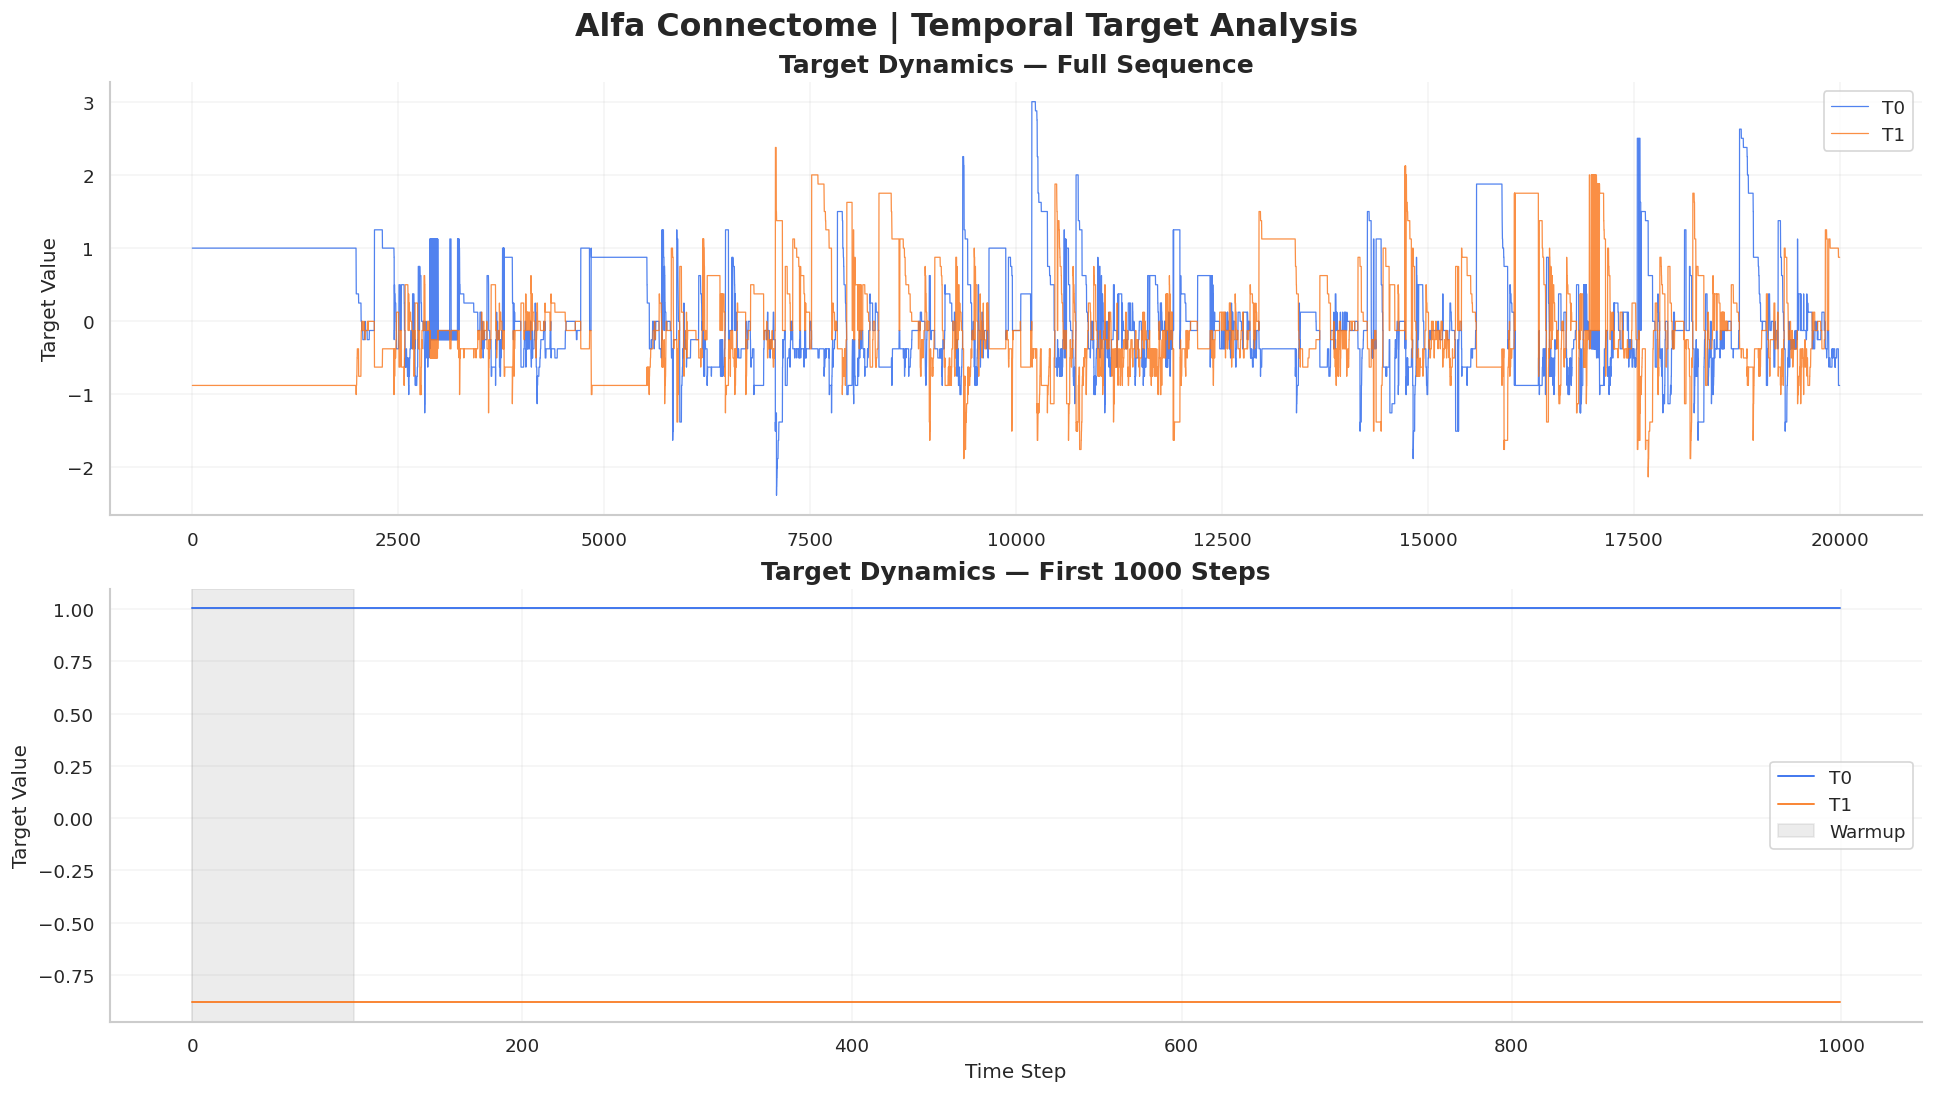

In [18]:

import numpy as np
import matplotlib.pyplot as plt

# Используем sample из предыдущей ячейки
df_seq = sample.copy()

print("=== АНАЛИЗ ПЕРВОЙ ПОСЛЕДОВАТЕЛЬНОСТИ ===")
print("ID:", df_seq["seq_ix"].iloc[0])
print("Длина:", len(df_seq))
print("Шагов с need_prediction:",
      int(df_seq["need_prediction"].sum()))
print("Всего пропусков:", int(df_seq.isna().sum().sum()))

for target in ["t0", "t1"]:
    y = df_seq[target]
    print(f"\n{target}:")
    print(f"  Среднее: {y.mean():.4f}")
    print(f"  Стандартное отклонение: {y.std():.4f}")
    print(f"  Минимум: {y.min():.4f}")
    print(f"  Максимум: {y.max():.4f}")
    print(f"  Уникальных значений: {y.nunique()}")
    print(f"  Доля изменений: {(y.diff().iloc[1:] != 0).mean():.2%}")

fig, axes = plt.subplots(
    2, 1, figsize=(16, 9), constrained_layout=True
)

colors = {"t0": "#2563EB", "t1": "#F97316"}

# Полная последовательность
for target in ["t0", "t1"]:
    axes[0].plot(
        df_seq["step_in_seq"],
        df_seq[target],
        label=target.upper(),
        color=colors[target],
        linewidth=0.75,
        alpha=0.8
    )

axes[0].set_title("Target Dynamics — Full Sequence")
axes[0].set_ylabel("Target Value")
axes[0].legend()
axes[0].grid(alpha=0.2)

# Увеличенный участок
zoom = df_seq[df_seq["step_in_seq"] < 1000]

for target in ["t0", "t1"]:
    axes[1].plot(
        zoom["step_in_seq"],
        zoom[target],
        label=target.upper(),
        color=colors[target],
        linewidth=1.2,
        alpha=0.85
    )

axes[1].axvspan(
    0, 98, color="gray", alpha=0.15,
    label="Warmup"
)

axes[1].set_title("Target Dynamics — First 1000 Steps")
axes[1].set_xlabel("Time Step")
axes[1].set_ylabel("Target Value")
axes[1].legend()
axes[1].grid(alpha=0.2)

fig.suptitle(
    "Alfa Connectome | Temporal Target Analysis",
    fontsize=19,
    fontweight="bold"
)

plt.show()



# Alfa Connectome — Exploratory Data Analysis

## 1. Структура датасета

Исследование проводится на `train.parquet`.

**Характеристики данных:**
- 10 607 независимых последовательностей.
- 20 000 временных шагов на последовательность.
- 212 140 000 наблюдений.
- 112 входных признаков, 2 целевые переменные (`t0`, `t1`) и 3 служебных поля.
- Первые 99 шагов каждой последовательности используются для разогрева модели.

Входные признаки объединены в три группы:
- `i0_*` — признаки первого инструмента (52).
- `i1_*` — признаки второго инструмента (52).
- `a0`–`a7` — дополнительные признаки (8).

**Ограничение:** `train.parquet` не содержит `is_scored`. Поэтому анализ распределения оцениваемых строк потребует дополнительных данных.

---

## 2. Временная структура целевых переменных

### 2.1. Первичный анализ последовательности №43601

Исследована одна последовательность длиной 20 000 шагов.

| Характеристика | t0 | t1 |
|---|---:|---:|
| Среднее | 0.1075 | -0.1293 |
| Стандартное отклонение | 0.7381 | 0.7157 |
| Минимум | -2.3832 | -2.1324 |
| Максимум | 3.0104 | 2.3832 |
| Уникальных значений | 44 | 36 |
| Доля переходов с изменением | 11.03% | 11.32% |

Пропусков в данной последовательности не обнаружено.

### Наблюдения

1. Целевые переменные имеют ступенчатую временную структуру: периоды постоянных значений чередуются со скачкообразными изменениями.
2. Примерно в 89% переходов между соседними шагами значения целей не изменяются.
3. На первых 1000 шагах обе цели остаются постоянными.
4. Встречаются значения за пределами [-2, 2], поэтому при исследовании официальной метрики необходимо учитывать предусмотренное правилами ограничение значений.

### Интерпретация

В исследованной последовательности целевые переменные обладают выраженной временной устойчивостью.

Это может указывать на наличие различных режимов динамики: длительных стабильных участков и коротких периодов интенсивных изменений.

Однако анализ одной последовательности недостаточен для вывода о свойствах всего датасета.

### Рекомендации

**Стоит проверить:**
- Распределение частоты изменений целей между последовательностями.
- Длительность участков постоянных значений.
- Наличие разных временных режимов.
- Связь изменений целей с наблюдаемыми входными признаками.

**Не стоит:**
- Делать выводы обо всём датасете по одной последовательности.
- Использовать предыдущие истинные значения `t0`, `t1` в модели: они недоступны во время тестового инференса.
- Делать вывод о необходимости увеличения памяти GRU только по длительности постоянных участков.

### Статус выводов

**Предварительные.** Требуется проверка на репрезентативной выборке последовательностей.


=== АНАЛИЗ 60 ПОСЛЕДОВАТЕЛЬНОСТЕЙ ===


,sequence,t0_change_rate,t0_first_change,t0_unique,t1_change_rate,t1_first_change,t1_unique
count,60.000,60.000,60.00,60.000,60.000,60.000,60.000
mean,5555.667,0.085,136.20,20.650,0.089,125.817,20.417
std,2918.533,0.058,363.86,16.132,0.058,360.323,15.651
min,464.000,0.021,1.00,7.000,0.017,1.000,7.000
25%,3547.750,0.039,4.00,10.750,0.040,4.000,10.000
50%,5663.000,0.063,19.50,13.000,0.072,15.500,13.000
75%,8041.750,0.123,77.75,24.500,0.116,75.250,27.000
max,10301.000,0.228,2258.00,73.000,0.238,2262.000,70.000



T0:
Средняя доля изменений: 8.54%
Медиана первого изменения: 19.5
Без изменений первые 1000 шагов: 3.33%

T1:
Средняя доля изменений: 8.86%
Медиана первого изменения: 15.5
Без изменений первые 1000 шагов: 3.33%


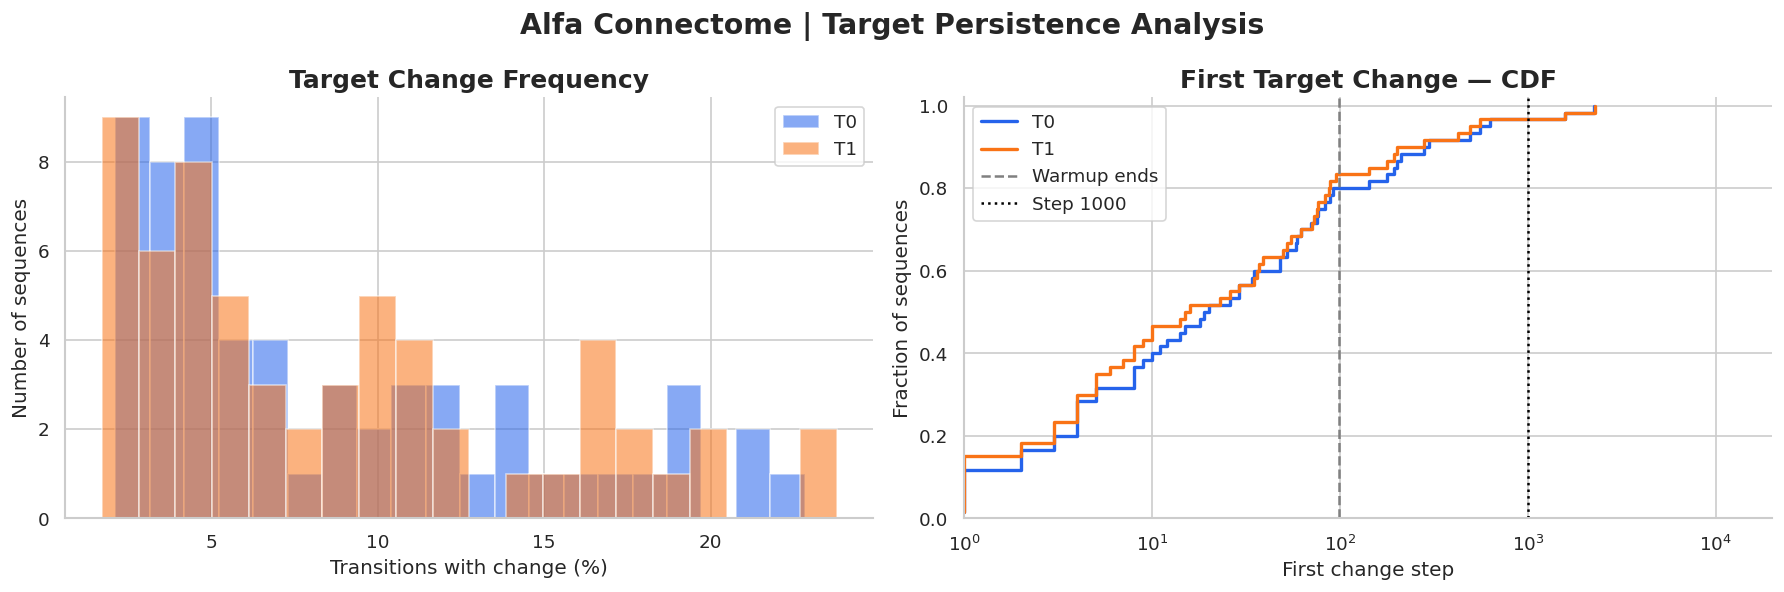

In [19]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq

pf = pq.ParquetFile(
    "/content/wnn_connectome_starterpack/datasets/train.parquet"
)

rng = np.random.default_rng(42)
n_sequences = 60

ids = rng.choice(
    pf.num_row_groups,
    size=n_sequences,
    replace=False
)

results = []

for idx in ids:
    table = pf.read_row_group(
        int(idx),
        columns=["t0", "t1"]
    )
    data = table.to_pandas()

    row = {"sequence": int(idx)}

    for target in ["t0", "t1"]:
        y = data[target].to_numpy()

        changes = np.flatnonzero(np.diff(y) != 0) + 1

        row[f"{target}_change_rate"] = np.mean(
            np.diff(y[99:]) != 0
        )

        row[f"{target}_first_change"] = (
            int(changes[0]) if len(changes) else len(y)
        )

        row[f"{target}_unique"] = len(np.unique(y))

    results.append(row)

stats = pd.DataFrame(results)

print("=== АНАЛИЗ 60 ПОСЛЕДОВАТЕЛЬНОСТЕЙ ===")
display(stats.describe().round(3))

for target in ["t0", "t1"]:
    first = stats[f"{target}_first_change"]

    print(f"\n{target.upper()}:")
    print(
        "Средняя доля изменений:",
        f"{stats[f'{target}_change_rate'].mean():.2%}"
    )
    print(
        "Медиана первого изменения:",
        first.median()
    )
    print(
        "Без изменений первые 1000 шагов:",
        f"{(first >= 1000).mean():.2%}"
    )

fig, axes = plt.subplots(
    1, 2, figsize=(15, 5)
)

colors = {"t0": "#2563EB", "t1": "#F97316"}

for target in ["t0", "t1"]:
    axes[0].hist(
        stats[f"{target}_change_rate"] * 100,
        bins=20,
        alpha=0.55,
        label=target.upper(),
        color=colors[target]
    )

    first = np.sort(
        stats[f"{target}_first_change"].to_numpy()
    )

    axes[1].step(
        first,
        np.arange(1, len(first) + 1) / len(first),
        where="post",
        label=target.upper(),
        color=colors[target],
        linewidth=2
    )

axes[0].set_title("Target Change Frequency")
axes[0].set_xlabel("Transitions with change (%)")
axes[0].set_ylabel("Number of sequences")
axes[0].legend()

axes[1].axvline(
    99, color="gray", linestyle="--",
    label="Warmup ends"
)
axes[1].axvline(
    1000, color="black", linestyle=":",
    label="Step 1000"
)

axes[1].set_title("First Target Change — CDF")
axes[1].set_xlabel("First change step")
axes[1].set_ylabel("Fraction of sequences")
axes[1].set_xscale("log")
axes[1].set_xlim(1, 20000)
axes[1].set_ylim(0, 1.02)
axes[1].legend()

fig.suptitle(
    "Alfa Connectome | Target Persistence Analysis",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



### 2.2. Устойчивость целевых переменных: анализ 60 последовательностей

Для проверки результатов первичного исследования случайным образом отобраны 60 последовательностей из `train.parquet` (seed = 42).

Для каждой последовательности рассчитаны:
- Доля переходов с изменением целевых переменных после warmup.
- Шаг первого изменения цели.
- Число уникальных целевых значений.

#### Основные результаты

| Метрика | t0 | t1 |
|---|---:|---:|
| Средняя доля изменений | 8.54% | 8.86% |
| Медианная доля изменений | 6.30% | 7.20% |
| Минимальная доля изменений | 2.10% | 1.70% |
| Максимальная доля изменений | 22.80% | 23.80% |
| Медиана первого изменения (шаг) | 19.5 | 15.5 |
| Без изменений первые 1000 шагов | 3.33% | 3.33% |

#### Наблюдения

**1. Ступенчатость целей подтверждается на выборке.**

В среднем примерно 91–91.5% переходов между соседними временными шагами происходят без изменения соответствующей цели.

**2. Последовательности заметно отличаются по частоте изменений.**

Наблюдаются как относительно стабильные последовательности с долей изменений около 2%, так и существенно более динамичные — свыше 20%.

Медианная доля изменений ниже средней, что указывает на влияние последовательностей с высокой частотой изменений.

**3. Длительные начальные постоянные участки не являются типичным поведением.**

Только 3.33% исследованных последовательностей сохраняли соответствующую цель неизменной на первых 1000 шагах.

Таким образом, первая рассмотренная последовательность №43601 не является репрезентативным примером начального поведения целей.

**4. Распределения для t0 и t1 похожи.**

Обе целевые переменные имеют близкие частоты изменений и распределения времени первого изменения. Однако синхронность конкретных изменений ещё не исследована.

#### Гипотезы

- В данных могут существовать различные режимы временной активности.
- Различия между режимами могут быть полезны при выборе архитектуры или обучающей стратегии.
- Изменения двух целей могут быть связаны с общими событиями в признаках стакана.

#### Практические рекомендации

**Стоит:**
- Исследовать синхронность изменений t0 и t1.
- Проверить распределения длительности постоянных участков.
- Сопоставить временные режимы с группами входных признаков.
- Проверить устойчивость результатов на более крупной выборке.

**Не стоит:**
- Считать, что все последовательности имеют одинаковую динамику.
- Делать вывод о необходимой длине памяти GRU только по частоте изменений целей.
- Использовать предыдущие истинные цели как признаки модели: при тестовом инференсе они недоступны.

#### Ограничения

Результаты получены на 60 из 10 607 последовательностей (около 0.57% обучающего набора).

Частота изменений целей сама по себе не определяет сложность прогнозирования и не гарантирует возможность улучшения официальной метрики.

**Статус:** предварительные выводы подтверждены на случайной выборке; требуется дальнейшее исследование.


=== СИНХРОННОСТЬ ИЗМЕНЕНИЙ ===
Средний Jaccard: 0.2561
Медианный Jaccard: 0.2822
Средний lift: 7.599
Медианный lift: 5.328

Корреляция частот изменений: 0.879


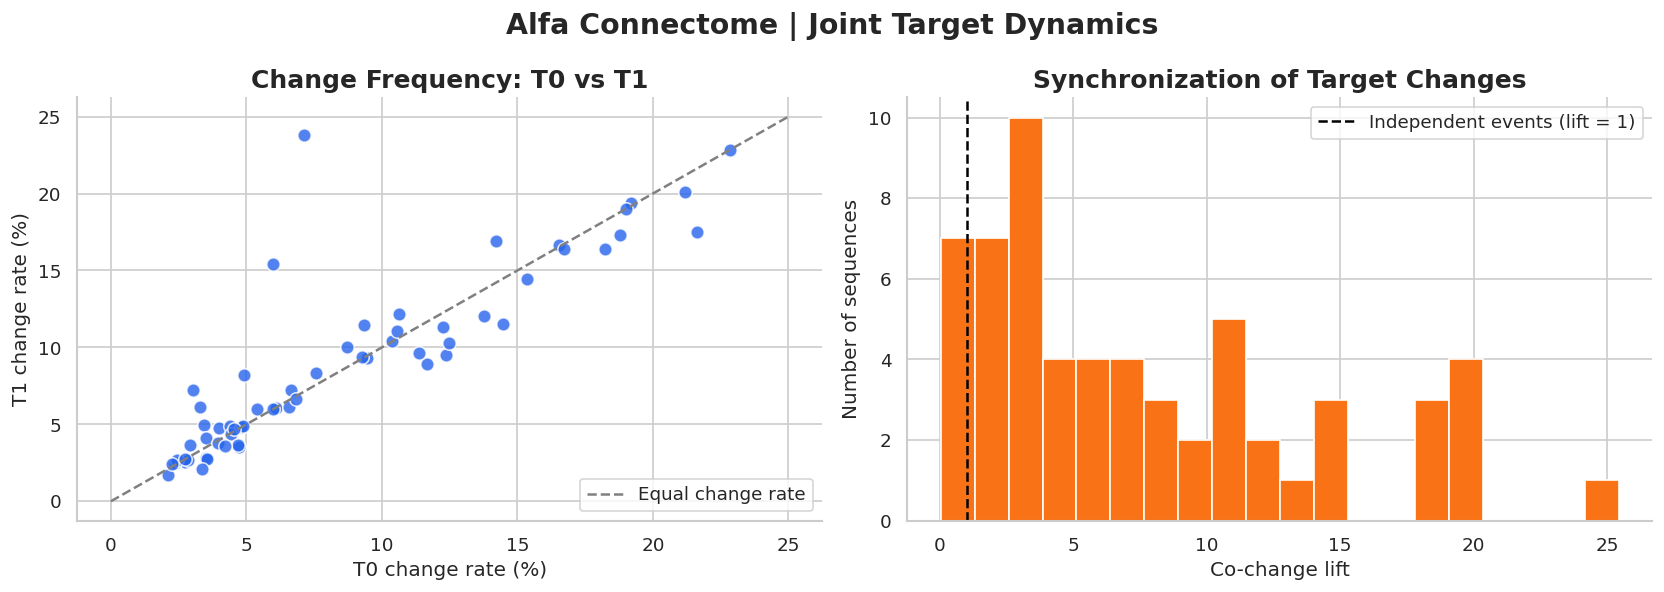

In [20]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

results_joint = []

for idx in ids:
    data = pf.read_row_group(
        int(idx), columns=["t0", "t1"]
    ).to_pandas()

    # Изменения только после warmup
    y0 = data["t0"].to_numpy()[99:]
    y1 = data["t1"].to_numpy()[99:]

    c0 = np.diff(y0) != 0
    c1 = np.diff(y1) != 0

    n0 = c0.sum()
    n1 = c1.sum()
    both = (c0 & c1).sum()
    either = (c0 | c1).sum()

    results_joint.append({
        "sequence": int(idx),
        "t0_rate": c0.mean(),
        "t1_rate": c1.mean(),
        "joint_rate": both / len(c0),
        "jaccard": both / either if either else np.nan,
        "lift": (
            both * len(c0) / (n0 * n1)
            if n0 > 0 and n1 > 0 else np.nan
        )
    })

joint_df = pd.DataFrame(results_joint)

print("=== СИНХРОННОСТЬ ИЗМЕНЕНИЙ ===")
print(f"Средний Jaccard: {joint_df.jaccard.mean():.4f}")
print(f"Медианный Jaccard: {joint_df.jaccard.median():.4f}")
print(f"Средний lift: {joint_df.lift.mean():.3f}")
print(f"Медианный lift: {joint_df.lift.median():.3f}")

print("\nКорреляция частот изменений:",
      round(joint_df.t0_rate.corr(joint_df.t1_rate), 4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    joint_df.t0_rate * 100,
    joint_df.t1_rate * 100,
    alpha=0.8,
    color="#2563EB",
    edgecolors="white",
    s=65
)

axes[0].plot(
    [0, 25], [0, 25],
    linestyle="--",
    color="gray",
    label="Equal change rate"
)

axes[0].set(
    title="Change Frequency: T0 vs T1",
    xlabel="T0 change rate (%)",
    ylabel="T1 change rate (%)"
)
axes[0].legend()

axes[1].hist(
    joint_df.lift.dropna(),
    bins=20,
    color="#F97316",
    edgecolor="white"
)

axes[1].axvline(
    1, color="black", linestyle="--",
    label="Independent events (lift = 1)"
)

axes[1].set(
    title="Synchronization of Target Changes",
    xlabel="Co-change lift",
    ylabel="Number of sequences"
)
axes[1].legend()

fig.suptitle(
    "Alfa Connectome | Joint Target Dynamics",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



### 2.3. Синхронность изменений целевых переменных

Для 60 случайных последовательностей исследована совместная динамика изменений `t0` и `t1` после warmup.

Использованные показатели:

- **Jaccard:** доля совместных изменений среди моментов, когда изменилась хотя бы одна цель.
- **Lift:** отношение наблюдаемой частоты совместных изменений к ожидаемой при независимости событий.
- **Корреляция частот:** корреляция долей изменений `t0` и `t1` между последовательностями.

#### Результаты

| Метрика | Значение |
|---|---:|
| Корреляция частот изменений | 0.879 |
| Средний Jaccard | 0.2561 |
| Медианный Jaccard | 0.2822 |
| Средний lift | 7.599 |
| Медианный lift | 5.328 |

#### Основные наблюдения

1. **Активность двух целей сильно связана.** Последовательности с высокой частотой изменений `t0` обычно характеризуются высокой частотой изменений `t1`.

2. **Изменения целей не являются независимыми.** Совместные изменения встречаются существенно чаще, чем можно ожидать при независимых событиях с соответствующими частотами.

3. **Полной синхронности нет.** Средний Jaccard составляет около 0.256, поэтому значительная часть изменений затрагивает только одну из целей.

4. **Степень синхронизации различается между последовательностями.** Распределение lift неоднородно, что может указывать на различия в динамике данных.

#### Интерпретация

Наблюдаемая синхронность согласуется с гипотезой о наличии общих факторов, влияющих на обе целевые переменные.

Это делает совместное моделирование двух целей обоснованным направлением для дальнейших экспериментов.

Однако высокая синхронность целевых изменений сама по себе не гарантирует, что соответствующие события можно предсказать по доступным входным признакам.

#### Рекомендации

**Стоит:**
- Исследовать направления совместных изменений.
- Проверить временные сдвиги между изменениями двух целей.
- Сравнить модель с общей GRU и двумя выходными головами с альтернативными многозадачными архитектурами.
- Проверить, сохраняется ли закономерность на других последовательностях.

**Не стоит:**
- Считать, что обе цели всегда меняются одновременно.
- Считать высокий lift доказательством причинной связи.
- Использовать изменения истинных целей как входные признаки при тестировании.

**Статус:** наблюдение подтверждено на выборке из 60 последовательностей. Прогностическая полезность требует отдельной проверки.


=== НАПРАВЛЕНИЯ СОВМЕСТНЫХ ИЗМЕНЕНИЙ ===
Совместных событий: 36636
Противоположные направления: 84.07%
Одинаковые направления: 15.93%
Ожидание при независимости знаков: 48.73%
Корреляция размеров изменений: -0.6383


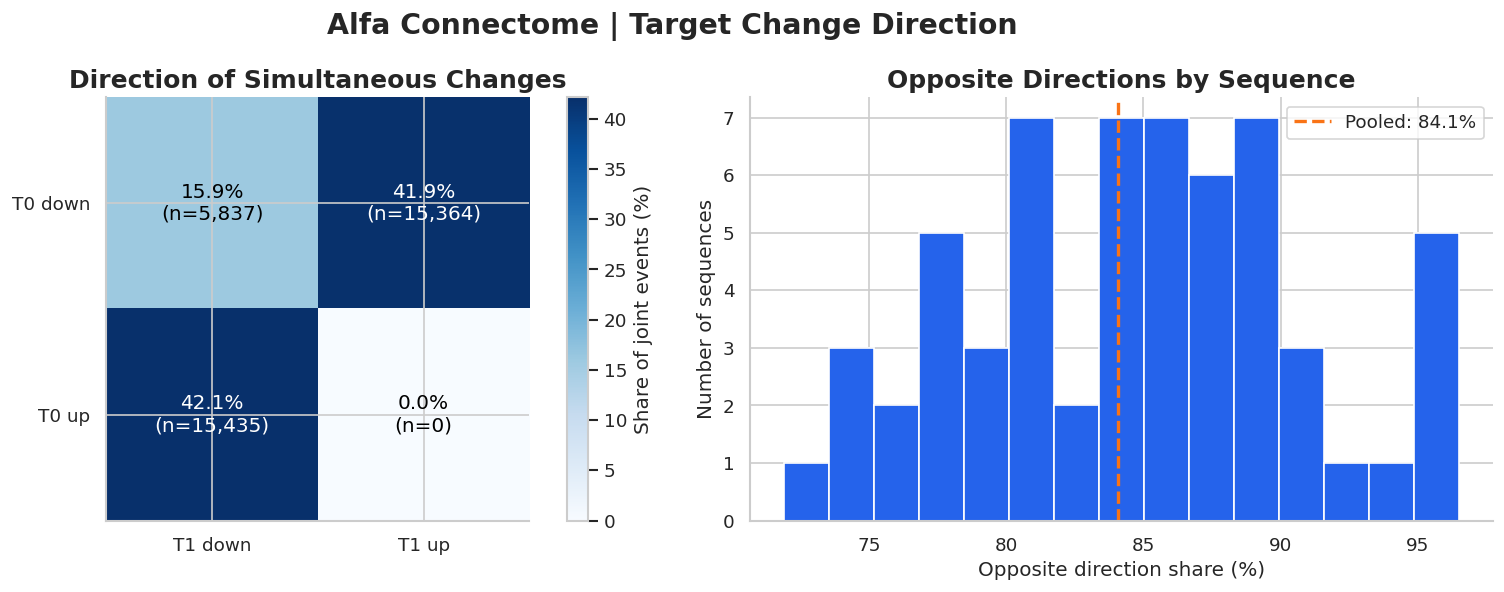

In [21]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

delta0_all = []
delta1_all = []
sequence_stats = []

for idx in ids:
    data = pf.read_row_group(
        int(idx), columns=["t0", "t1"]
    ).to_pandas()

    y0 = data["t0"].to_numpy(dtype=np.float64)[99:]
    y1 = data["t1"].to_numpy(dtype=np.float64)[99:]

    d0 = np.diff(y0)
    d1 = np.diff(y1)

    # Только шаги, когда обе цели изменились
    mask = (
        (d0 != 0) & (d1 != 0)
        & np.isfinite(d0) & np.isfinite(d1)
    )

    a = d0[mask]
    b = d1[mask]

    if len(a) == 0:
        continue

    delta0_all.append(a)
    delta1_all.append(b)

    sequence_stats.append({
        "sequence": int(idx),
        "joint_events": len(a),
        "opposite_rate": np.mean(a * b < 0)
    })

delta0 = np.concatenate(delta0_all)
delta1 = np.concatenate(delta1_all)

sign0 = np.sign(delta0)
sign1 = np.sign(delta1)

opposite = sign0 != sign1
opposite_rate = opposite.mean()

p0_up = (sign0 > 0).mean()
p1_up = (sign1 > 0).mean()

expected_opposite = (
    p0_up * (1 - p1_up)
    + (1 - p0_up) * p1_up
)

corr_delta = np.corrcoef(delta0, delta1)[0, 1]

print("=== НАПРАВЛЕНИЯ СОВМЕСТНЫХ ИЗМЕНЕНИЙ ===")
print("Совместных событий:", len(delta0))
print(f"Противоположные направления: {opposite_rate:.2%}")
print(f"Одинаковые направления: {1-opposite_rate:.2%}")
print(f"Ожидание при независимости знаков: {expected_opposite:.2%}")
print(f"Корреляция размеров изменений: {corr_delta:.4f}")

# Матрица направлений
counts = np.array([
    [
        np.sum((sign0 < 0) & (sign1 < 0)),
        np.sum((sign0 < 0) & (sign1 > 0))
    ],
    [
        np.sum((sign0 > 0) & (sign1 < 0)),
        np.sum((sign0 > 0) & (sign1 > 0))
    ]
])

percent = counts / counts.sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

im = axes[0].imshow(percent, cmap="Blues", vmin=0)

axes[0].set_xticks([0, 1], ["T1 down", "T1 up"])
axes[0].set_yticks([0, 1], ["T0 down", "T0 up"])
axes[0].set_title("Direction of Simultaneous Changes")

for i in range(2):
    for j in range(2):
        axes[0].text(
            j, i,
            f"{percent[i, j]:.1f}%\n(n={counts[i, j]:,})",
            ha="center", va="center",
            color="white" if percent[i, j] > 25 else "black",
            fontsize=12
        )

fig.colorbar(im, ax=axes[0], label="Share of joint events (%)")

seq_stats = pd.DataFrame(sequence_stats)

axes[1].hist(
    seq_stats["opposite_rate"] * 100,
    bins=15,
    color="#2563EB",
    edgecolor="white"
)

axes[1].axvline(
    opposite_rate * 100,
    color="#F97316",
    linestyle="--",
    linewidth=2,
    label=f"Pooled: {opposite_rate:.1%}"
)

axes[1].set_title("Opposite Directions by Sequence")
axes[1].set_xlabel("Opposite direction share (%)")
axes[1].set_ylabel("Number of sequences")
axes[1].legend()

fig.suptitle(
    "Alfa Connectome | Target Change Direction",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

fig_dir = Path("/content/eda_figures")
fig_dir.mkdir(exist_ok=True)
plt.savefig(
    fig_dir / "04_target_change_direction.png",
    dpi=200, bbox_inches="tight"
)

plt.show()



### 2.4. Направления совместных изменений целевых переменных

Исследованы 60 случайных последовательностей из обучающего набора. Для каждого временного шага после warmup вычислены приращения целевых переменных:

\[
\Delta t_0(k)=t_0(k)-t_0(k-1), \qquad
\Delta t_1(k)=t_1(k)-t_1(k-1).
\]

Рассматривались только события, при которых оба приращения отличны от нуля.

#### Результаты

| Метрика | Значение |
|---|---:|
| Совместных изменений | 36 636 |
| Противоположные направления | 84.07% |
| Одинаковые направления | 15.93% |
| Ожидаемая доля противоположных знаков при независимости | 48.73% |
| Корреляция величин приращений | -0.6383 |

#### Матрица направлений

| | t1 уменьшается | t1 увеличивается |
|---|---:|---:|
| t0 уменьшается | 5 837 | 15 364 |
| t0 увеличивается | 15 435 | 0 |

#### Основные наблюдения

1. Совместные изменения целей преимущественно разнонаправлены: в 84.07% случаев знаки приращений противоположны.

2. Корреляция величин одновременных изменений отрицательна и составляет -0.6383.

3. В исследованной выборке не обнаружено событий одновременного увеличения обеих целей.

4. Доля противоположных изменений заметно различается между последовательностями, но остаётся высокой.

#### Интерпретация

Результаты свидетельствуют о выраженной отрицательной зависимости между изменениями целевых переменных.

Отсутствие одновременных положительных приращений может отражать особенность конструкции целевых переменных или ограничение в механизме генерации данных.

Однако это предположение требует проверки на большем числе последовательностей. На данном этапе нельзя считать выявленную закономерность строгим универсальным правилом.

#### Рекомендации

**Стоит:**
- Проверить отсутствие одновременных положительных приращений на расширенной выборке.
- Исследовать связь уровней t0 и t1, а не только их приращений.
- Рассмотреть совместное моделирование целей и возможную параметризацию их общих компонентов.
- Проверять влияние новых архитектурных ограничений на независимой валидации.

**Не стоит:**
- Немедленно вводить жёсткие ограничения на выходы нейросети.
- Считать отрицательную корреляцию доказательством причинной зависимости.
- Использовать истинные приращения целей как входные признаки модели: в тестовом режиме они недоступны.

**Статус:** обнаружена сильная эмпирическая закономерность на 60 последовательностях. Требуется проверка её устойчивости.


=== ПРОВЕРКА НА 200 ПОСЛЕДОВАТЕЛЬНОСТЯХ ===


,down_down,down_up,up_down,up_up
group,,,,
New 140,15029,35366,35273,0
Original 60,5837,15364,15435,0



Всего совместных изменений: 122,304
Оба увеличиваются: 0
Последовательностей с совместным ростом: 0 из 200
Противоположные направления: 82.94%
Оба уменьшаются: 17.06%
Оба увеличиваются: 0.0000%


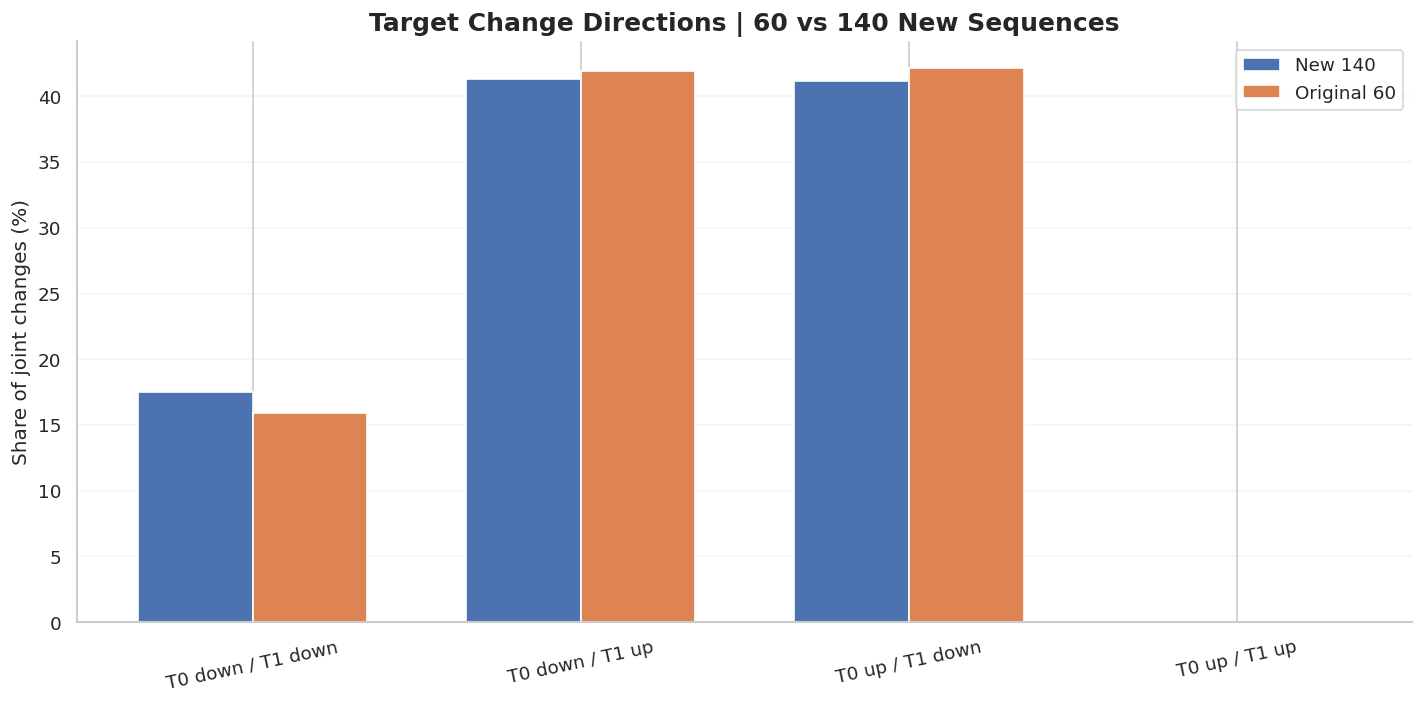

In [22]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Сохраняем предыдущие 60 последовательностей
original_ids = np.unique(np.asarray(ids, dtype=int))

rng_check = np.random.default_rng(2026)

available = np.setdiff1d(
    np.arange(pf.num_row_groups),
    original_ids
)

new_ids = rng_check.choice(
    available,
    size=200 - len(original_ids),
    replace=False
)

all_ids = np.concatenate([original_ids, new_ids])

EPS = 1e-6
records = []

for j, idx in enumerate(all_ids):
    table = pf.read_row_group(
        int(idx),
        columns=["t0", "t1"]
    )

    data = table.to_pandas()

    y0 = data["t0"].to_numpy(dtype=np.float64)[99:]
    y1 = data["t1"].to_numpy(dtype=np.float64)[99:]

    d0 = np.diff(y0)
    d1 = np.diff(y1)

    # Знаки изменений с допуском на численную погрешность
    s0 = np.where(d0 > EPS, 1, np.where(d0 < -EPS, -1, 0))
    s1 = np.where(d1 > EPS, 1, np.where(d1 < -EPS, -1, 0))

    records.append({
        "group": "Original 60" if j < len(original_ids) else "New 140",
        "sequence": int(idx),
        "down_down": np.sum((s0 == -1) & (s1 == -1)),
        "down_up": np.sum((s0 == -1) & (s1 == 1)),
        "up_down": np.sum((s0 == 1) & (s1 == -1)),
        "up_up": np.sum((s0 == 1) & (s1 == 1)),
    })

check_df = pd.DataFrame(records)

categories = ["down_down", "down_up", "up_down", "up_up"]

summary = check_df.groupby("group")[categories].sum()

print("=== ПРОВЕРКА НА 200 ПОСЛЕДОВАТЕЛЬНОСТЯХ ===")
display(summary)

total = check_df[categories].sum()
joint = int(total.sum())

print(f"\nВсего совместных изменений: {joint:,}")
print(f"Оба увеличиваются: {total['up_up']:,}")
print(
    "Последовательностей с совместным ростом:",
    int((check_df["up_up"] > 0).sum()),
    "из", len(check_df)
)

opposite = total["down_up"] + total["up_down"]

print(f"Противоположные направления: {opposite / joint:.2%}")
print(f"Оба уменьшаются: {total['down_down'] / joint:.2%}")
print(f"Оба увеличиваются: {total['up_up'] / joint:.4%}")

# Визуальное сравнение старой и новой выборок
percent = summary.div(summary.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(12, 6))

labels = [
    "T0 down / T1 down",
    "T0 down / T1 up",
    "T0 up / T1 down",
    "T0 up / T1 up"
]

x = np.arange(len(labels))
width = 0.35

for k, group in enumerate(percent.index):
    ax.bar(
        x + (k - 0.5) * width,
        percent.loc[group].values,
        width,
        label=group
    )

ax.set_xticks(x, labels, rotation=12)
ax.set_ylabel("Share of joint changes (%)")
ax.set_title("Target Change Directions | 60 vs 140 New Sequences")
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()



### 2.5. Проверка направлений изменений на расширенной выборке

Для проверки обнаруженной закономерности выборка расширена до 200 последовательностей из `train.parquet`: исходные 60 и дополнительные 140.

Проанализированы одновременные ненулевые изменения `t0` и `t1` после периода warmup. Для определения направления изменения использован численный допуск \(10^{-6}\).

#### Результаты

| Направление | Количество |
|---|---:|
| Обе цели уменьшаются | 20 866 |
| t0 уменьшается, t1 увеличивается | 50 730 |
| t0 увеличивается, t1 уменьшается | 50 708 |
| Обе цели увеличиваются | 0 |
| **Всего совместных изменений** | **122 304** |

Доля противоположных направлений составляет **82.94%**, а совместных уменьшений — **17.06%**.

Ни в одной из 200 последовательностей не обнаружено одновременного положительного приращения обеих целей.

#### Основные выводы

1. **Сильная отрицательная зависимость изменений подтверждена на расширенной выборке.** Результаты согласуются с предыдущим анализом 60 последовательностей.

2. **Отсутствие одновременного роста — устойчивая эмпирическая закономерность.** Она может быть следствием ограничений, заложенных в процесс формирования целевых переменных.

3. **Зависимость не является простой противоположностью двух целей.** В 17.06% совместных изменений обе цели уменьшаются, поэтому модель вида \(t_1=-t_0\) нельзя считать обоснованной.

#### Практические рекомендации

**Стоит:**
- Рассматривать совместное моделирование целей с общим представлением и отдельными выходными головами.
- Проверить структуру зависимости на независимой валидации.
- Исследовать, какие доступные входные признаки предшествуют совместным изменениям целей.

**Не стоит:**
- Накладывать жёсткие ограничения на значения прогнозов без проверки качества.
- Считать эмпирическую закономерность доказанным свойством всех данных.
- Использовать истинные прошлые изменения целей в тестовом инференсе.

#### Ограничения

Исследованы 200 из 10 607 последовательностей (около 1.89% обучающего набора). Несмотря на большое число наблюдаемых событий, они зависимы внутри последовательностей.

**Статус:** устойчивая эмпирическая закономерность, требующая дополнительной проверки.


=== ПРОФИЛЬ ВХОДНЫХ ПРИЗНАКОВ ===
Признаков: 112
Проанализировано строк: 597030

Средняя частота изменений по группам:


,count,change_rate,nonfinite_rate
group,,,
auxiliary,8,0.9293,0.0
i0_dp,4,0.3832,0.0
i0_dv,4,0.1870,0.0
i0_p,22,0.2674,0.0
i0_v,22,0.6577,0.0
i1_dp,4,0.2237,0.0
i1_dv,4,0.2628,0.0
i1_p,22,0.0921,0.0
i1_v,22,0.3228,0.0



15 наименее динамичных признаков:


,feature,group,change_rate,nonfinite_rate,sentinel_rate
63,i1_p11,i1_p,0.0910,0.0,0.0
64,i1_p12,i1_p,0.0910,0.0,0.0
65,i1_p13,i1_p,0.0910,0.0,0.0
66,i1_p14,i1_p,0.0910,0.0,0.0
67,i1_p15,i1_p,0.0910,0.0,0.0
68,i1_p16,i1_p,0.0910,0.0,0.0
69,i1_p17,i1_p,0.0910,0.0,0.0
70,i1_p18,i1_p,0.0910,0.0,0.0
71,i1_p19,i1_p,0.0910,0.0,0.0
72,i1_p20,i1_p,0.0910,0.0,0.0



Признаки со специальным значением -5.199337:


,feature,group,change_rate,nonfinite_rate,sentinel_rate
111,a7,auxiliary,0.6415,0.0,0.3458
110,a6,auxiliary,0.9020,0.0,0.1708
109,a5,auxiliary,0.8975,0.0,0.1379
104,a0,auxiliary,0.9937,0.0,0.0000


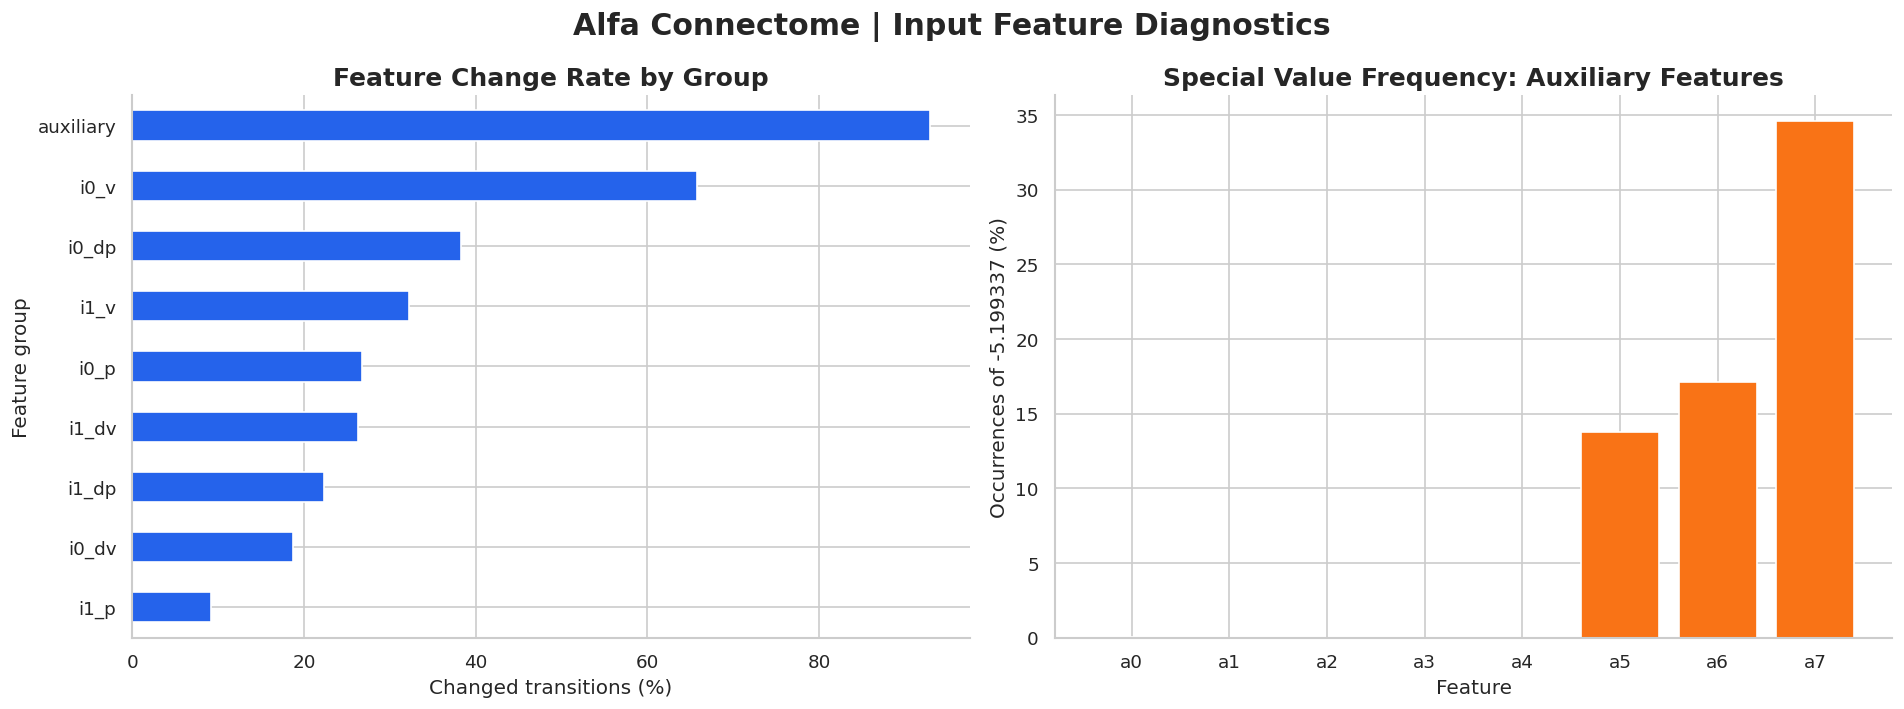

In [23]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)
selected_ids = rng.choice(
    pf.num_row_groups, size=30, replace=False
)

exclude = {
    "seq_ix", "step_in_seq", "need_prediction",
    "is_scored", "t0", "t1"
}
features = [
    c for c in pf.schema_arrow.names if c not in exclude
]

n_features = len(features)
change_counts = np.zeros(n_features, dtype=np.int64)
finite_counts = np.zeros(n_features, dtype=np.int64)
sentinel_counts = np.zeros(n_features, dtype=np.int64)

total_rows = 0
total_transitions = 0

for idx in selected_ids:
    table = pf.read_row_group(
        int(idx), columns=features
    )

    X = table.to_pandas().to_numpy(
        dtype=np.float32
    )[99:]

    finite = np.isfinite(X)

    finite_counts += finite.sum(axis=0)
    sentinel_counts += np.isclose(
        X, -5.199337, rtol=0, atol=1e-5
    ).sum(axis=0)

    change = (
        np.abs(np.diff(X, axis=0)) > 1e-6
    )
    change &= finite[1:] & finite[:-1]

    change_counts += change.sum(axis=0)

    total_rows += len(X)
    total_transitions += len(X) - 1

def feature_group(name):
    if name.startswith("a"):
        return "auxiliary"
    prefix, suffix = name.split("_")
    kind = suffix.rstrip("0123456789")
    return f"{prefix}_{kind}"

profile = pd.DataFrame({
    "feature": features,
    "group": [feature_group(c) for c in features],
    "change_rate": change_counts / total_transitions,
    "nonfinite_rate": 1 - finite_counts / total_rows,
    "sentinel_rate": sentinel_counts / total_rows,
})

print("=== ПРОФИЛЬ ВХОДНЫХ ПРИЗНАКОВ ===")
print("Признаков:", len(features))
print("Проанализировано строк:", total_rows)

print("\nСредняя частота изменений по группам:")
group_stats = profile.groupby("group").agg(
    count=("feature", "size"),
    change_rate=("change_rate", "mean"),
    nonfinite_rate=("nonfinite_rate", "mean")
)
display(group_stats.round(4))

print("\n15 наименее динамичных признаков:")
display(
    profile.nsmallest(15, "change_rate").round(4)
)

print("\nПризнаки со специальным значением -5.199337:")
display(
    profile[profile.sentinel_rate > 0]
    .sort_values("sentinel_rate", ascending=False)
    .round(4)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

group_stats["change_rate"].sort_values().mul(100).plot.barh(
    ax=axes[0], color="#2563EB"
)
axes[0].set_title("Feature Change Rate by Group")
axes[0].set_xlabel("Changed transitions (%)")
axes[0].set_ylabel("Feature group")

aux = profile[profile.group == "auxiliary"]

axes[1].bar(
    aux["feature"],
    aux["sentinel_rate"] * 100,
    color="#F97316"
)
axes[1].set_title("Special Value Frequency: Auxiliary Features")
axes[1].set_xlabel("Feature")
axes[1].set_ylabel("Occurrences of -5.199337 (%)")

fig.suptitle(
    "Alfa Connectome | Input Feature Diagnostics",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



## 3. Исследование входных признаков

### 3.1. Временная активность и специальные значения

Проанализированы 112 входных признаков на 30 случайных последовательностях из `train.parquet`.

Общий объём выборки после warmup — **597 030 наблюдений**.

#### Частота обновления признаков

| Группа | Число признаков | Средняя доля изменений |
|---|---:|---:|
| Дополнительные признаки a* | 8 | 92.93% |
| Объёмы i0_v | 22 | 65.77% |
| Приращения цен i0_dp | 4 | 38.32% |
| Объёмы i1_v | 22 | 32.28% |
| Цены i0_p | 22 | 26.74% |
| Приращения объёмов i1_dv | 4 | 26.28% |
| Приращения цен i1_dp | 4 | 22.37% |
| Приращения объёмов i0_dv | 4 | 18.70% |
| Цены i1_p | 22 | 9.21% |

#### Основные наблюдения

**1. Два инструмента имеют различную временную динамику.**

Ценовые признаки первого инструмента обновляются примерно в 2.9 раза чаще, а объёмные — в 2 раза чаще соответствующих признаков второго инструмента.

Это указывает на различия в наблюдаемой активности инструментов.

**2. Значительная часть ценовых признаков второго инструмента изменяется редко.**

Для многих признаков `i1_p*` доля изменений составляет около 9.1%.

Необходимо проверить синхронность обновлений и возможную избыточность этих признаков.

**3. Дополнительные признаки обладают высокой временной активностью.**

Средняя доля изменений группы `a0`–`a7` составляет 92.93%.

Однако частота обновлений сама по себе не определяет полезность признаков для прогнозирования.

**4. Обнаружено специальное числовое значение -5.199337.**

Частота его появления:

| Признак | Доля наблюдений |
|---|---:|
| a5 | 13.79% |
| a6 | 17.08% |
| a7 | 34.58% |

Вероятно, это специальное кодирование некоторого состояния или отсутствующей информации. Его точный смысл пока не установлен.

**5. Некорректные числовые значения не обнаружены.**

Среди входных признаков исследованной выборки не выявлено `NaN` и бесконечных значений.

Это не исключает наличия специально закодированных пропусков.

#### Практические рекомендации

**Стоит:**
- Проверить, содержат ли специальные значения в a5–a7 информацию о величине целевых переменных.
- Исследовать взаимосвязи признаков внутри ценовых и объёмных групп.
- Проверить полезность разностей между соседними наблюдениями.
- Рассмотреть отдельную обработку групп i0 и i1 с последующим объединением представлений.

**Не стоит:**
- Удалять редко изменяющиеся признаки без проверки их прогностической ценности.
- Автоматически заменять -5.199337 нулём.
- Считать часто обновляемые признаки наиболее информативными.
- Интерпретировать индексы ценовых признаков как упорядоченные уровни стакана без подтверждения.

#### Ограничения

Результаты получены на 30 последовательностях. Обнаруженные различия описывают статистическую структуру данных, но пока не показывают прямой связи с качеством прогнозирования.

**Статус:** подтверждённые описательные наблюдения; прогностическая значимость требует проверки.


=== СПЕЦИАЛЬНЫЕ ЗНАЧЕНИЯ И КРУПНЫЕ ЦЕЛИ ===
Крупная цель: abs(target) >= 1.0

Условные вероятности (по всем строкам):


P_large_special  P_large_normal
feature target                                 
a5      t0               0.2713          0.1916
        t1               0.2822          0.1964
a6      t0               0.0956          0.2246
        t1               0.1100          0.2285
a7      t0               0.2425          0.1815
        t1               0.2537          0.1843


Разница внутри последовательностей, п.п.:


mean_delta_pp  median_delta_pp  sequences
feature target                                           
a5      t0              5.817            4.701         30
        t1              6.478            4.475         30
a6      t0             -8.524           -9.276         30
        t1             -8.716           -8.980         30
a7      t0              5.191            3.471         30
        t1              6.341            3.834         30

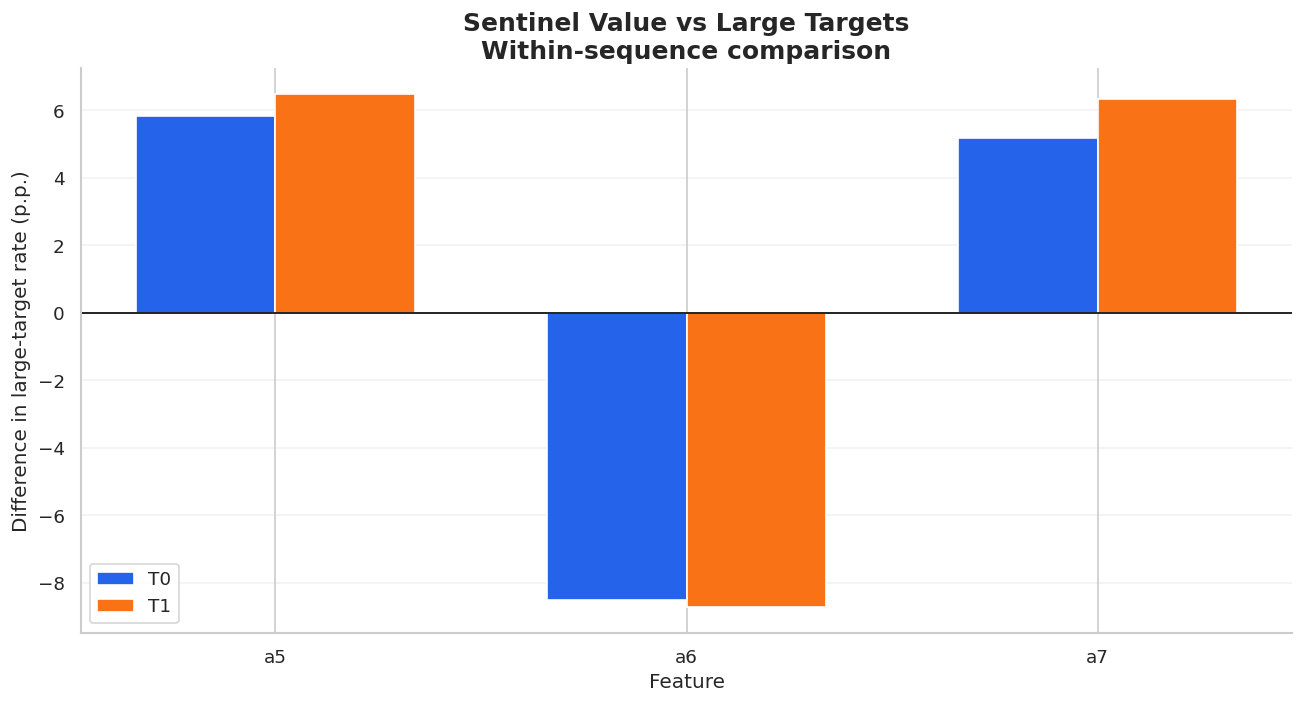

In [24]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SENTINEL = -5.199337
THRESHOLD = 1.0

records = []

# Используем те же 30 последовательностей,
# что и в предыдущем исследовании.
for idx in selected_ids:
    data = pf.read_row_group(
        int(idx),
        columns=[
            "need_prediction",
            "a5", "a6", "a7",
            "t0", "t1"
        ]
    ).to_pandas()

    data = data.loc[data["need_prediction"]]

    for feature in ["a5", "a6", "a7"]:
        x = data[feature].to_numpy()

        is_special = np.isclose(
            x, SENTINEL, rtol=0, atol=1e-5
        )

        for target in ["t0", "t1"]:
            y = data[target].to_numpy()
            y = np.clip(y, -2, 2)

            large = np.abs(y) >= THRESHOLD

            n_special = int(is_special.sum())
            n_normal = int((~is_special).sum())

            if n_special == 0 or n_normal == 0:
                continue

            records.append({
                "sequence": int(idx),
                "feature": feature,
                "target": target,
                "n_special": n_special,
                "n_normal": n_normal,
                "large_special": int(
                    large[is_special].sum()
                ),
                "large_normal": int(
                    large[~is_special].sum()
                )
            })

res = pd.DataFrame(records)

# Общие условные вероятности
pooled = res.groupby(
    ["feature", "target"]
)[
    ["n_special", "n_normal",
     "large_special", "large_normal"]
].sum()

pooled["P_large_special"] = (
    pooled["large_special"] / pooled["n_special"]
)

pooled["P_large_normal"] = (
    pooled["large_normal"] / pooled["n_normal"]
)

# Отдельно оцениваем эффект внутри последовательностей,
# чтобы снизить влияние различий между ними.
res["delta_pp"] = 100 * (
    res["large_special"] / res["n_special"]
    - res["large_normal"] / res["n_normal"]
)

reliable = res[
    (res["n_special"] >= 50)
    & (res["n_normal"] >= 50)
]

within = reliable.groupby(
    ["feature", "target"]
).agg(
    mean_delta_pp=("delta_pp", "mean"),
    median_delta_pp=("delta_pp", "median"),
    sequences=("sequence", "count")
)

print("=== СПЕЦИАЛЬНЫЕ ЗНАЧЕНИЯ И КРУПНЫЕ ЦЕЛИ ===")
print(f"Крупная цель: abs(target) >= {THRESHOLD}")

print("\nУсловные вероятности (по всем строкам):")
display(
    pooled[
        ["P_large_special", "P_large_normal"]
    ].round(4)
)

print("\nРазница внутри последовательностей, п.п.:")
display(within.round(3))

# График средних различий внутри последовательностей
plot_data = within.reset_index()

fig, ax = plt.subplots(figsize=(11, 6))

features_plot = ["a5", "a6", "a7"]
x = np.arange(len(features_plot))
width = 0.34

for j, target in enumerate(["t0", "t1"]):
    subset = plot_data[
        plot_data["target"] == target
    ].set_index("feature")

    values = subset.reindex(
        features_plot
    )["mean_delta_pp"].to_numpy()

    ax.bar(
        x + (j - 0.5) * width,
        values,
        width,
        label=target.upper(),
        color=["#2563EB", "#F97316"][j]
    )

ax.axhline(0, color="black", linewidth=1)

ax.set_xticks(x, features_plot)
ax.set_xlabel("Feature")
ax.set_ylabel("Difference in large-target rate (p.p.)")
ax.set_title(
    "Sentinel Value vs Large Targets\n"
    "Within-sequence comparison"
)
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()



### 3.2. Связь специальных значений с крупными целевыми переменными

Исследована связь специального значения `-5.199337` в признаках `a5`, `a6`, `a7` с событием:

\[
|t_j| \geq 1,\qquad j\in\{0,1\}.
\]

Анализ проводился на 30 последовательностях из `train.parquet`. Для каждой последовательности сравнивались вероятности крупной цели при наличии и отсутствии специального значения.

Результаты усреднены по последовательностям, чтобы снизить влияние различий между ними.

#### Результаты

| Признак | Разница вероятностей для t0 | Для t1 |
|---|---:|---:|
| a5 | +5.82 п.п. | +6.48 п.п. |
| a6 | -8.52 п.п. | -8.72 п.п. |
| a7 | +5.19 п.п. | +6.34 п.п. |

#### Основные наблюдения

1. **Признаки a5 и a7 положительно связаны с крупными целями.** При появлении специального значения вероятность большой абсолютной величины цели в среднем повышается.

2. **Признак a6 демонстрирует отрицательную связь.** При появлении специального значения вероятность крупной цели снижается.

3. **Характер зависимости сходен для t0 и t1.** Это может указывать на связь дополнительных признаков с общими режимами поведения двух инструментов.

4. **Специальное значение потенциально информативно.** Его не следует автоматически считать обычным пропуском, удалять или заменять нулём без проверки.

#### Интерпретация

Различное поведение a5, a6 и a7 допускает гипотезу о том, что специальное значение кодирует различные состояния наблюдаемого процесса.

Однако установленная связь является статистической ассоциацией, а не доказательством причинности или прогностической полезности.

Событие большой абсолютной величины цели также не следует отождествлять с моментом изменения цели.

#### Практические рекомендации

**Стоит:**
- Сохранить специальные значения при подготовке данных.
- Проверить добавление бинарных индикаторов наличия специального значения.
- Оценить устойчивость эффекта между последовательностями.
- Проверить гипотезу об улучшении модели на независимой валидации.

**Не стоит:**
- Заменять -5.199337 нулём без эксперимента.
- Считать, что обнаруженная связь автоматически повышает качество прогнозирования.
- Удалять строки со специальными значениями.
- Использовать данные о будущих целях при построении признаков.

#### Ограничения

Результаты основаны на 30 последовательностях. Из-за временной зависимости наблюдений число строк не следует трактовать как число независимых экспериментов.

**Статус:** предварительно обнаруженная статистическая связь; необходима проверка устойчивости.


=== УСТОЙЧИВОСТЬ СВЯЗИ ===


,feature,target,sequences,mean_pp,ci_lower,ci_upper,positive_share,negative_share
0,a5,t0,30,5.817,3.627,8.128,0.833,0.167
1,a5,t1,30,6.478,3.996,9.304,0.900,0.100
2,a6,t0,30,-8.524,-10.660,-6.531,0.000,1.000
3,a6,t1,30,-8.716,-11.046,-6.318,0.100,0.900
4,a7,t0,30,5.191,2.983,7.671,0.767,0.233
5,a7,t1,30,6.341,3.696,9.459,0.900,0.100


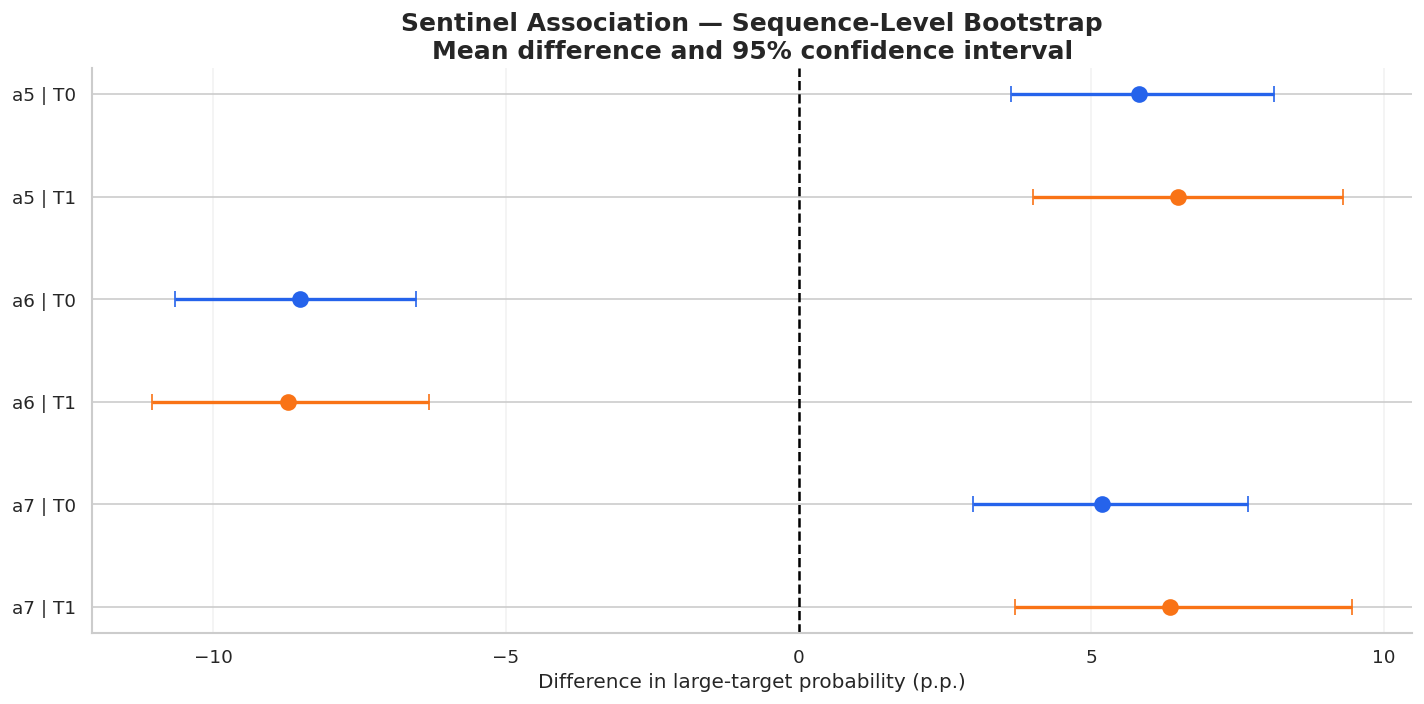

In [25]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

data = res[
    (res["n_special"] >= 50)
    & (res["n_normal"] >= 50)
].copy()

results = []

for (feature, target), group in data.groupby(
    ["feature", "target"]
):
    values = group["delta_pp"].to_numpy()

    # Bootstrap: единица повторной выборки — последовательность
    n = len(values)
    indices = rng.integers(0, n, size=(5000, n))
    boot_means = values[indices].mean(axis=1)

    lower, upper = np.quantile(
        boot_means, [0.025, 0.975]
    )

    results.append({
        "feature": feature,
        "target": target,
        "sequences": n,
        "mean_pp": values.mean(),
        "ci_lower": lower,
        "ci_upper": upper,
        "positive_share": np.mean(values > 0),
        "negative_share": np.mean(values < 0)
    })

stability = pd.DataFrame(results)

print("=== УСТОЙЧИВОСТЬ СВЯЗИ ===")
display(stability.round(3))

fig, ax = plt.subplots(figsize=(12, 6))

labels = []
positions = []

for i, row in stability.iterrows():
    y = len(stability) - i
    labels.append(
        f"{row['feature']} | {row['target'].upper()}"
    )
    positions.append(y)

    color = (
        "#2563EB" if row["target"] == "t0"
        else "#F97316"
    )

    ax.errorbar(
        row["mean_pp"],
        y,
        xerr=[
            [row["mean_pp"] - row["ci_lower"]],
            [row["ci_upper"] - row["mean_pp"]]
        ],
        fmt="o",
        color=color,
        markersize=9,
        capsize=5,
        linewidth=2
    )

ax.set_yticks(positions, labels)
ax.axvline(0, color="black", linestyle="--")
ax.set_xlabel("Difference in large-target probability (p.p.)")
ax.set_title(
    "Sentinel Association — Sequence-Level Bootstrap\n"
    "Mean difference and 95% confidence interval"
)
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()



### 3.3. Устойчивость связи специальных значений с крупными целями

Для проверки устойчивости результатов выполнен бутстрэп на уровне последовательностей (5000 повторных выборок).

Исследовалась разница вероятностей события `|target| >= 1` между строками со специальным значением `-5.199337` и остальными строками.

#### Результаты

| Признак | Цель | Средняя разница, п.п. | 95% бутстрэп-интервал |
|---|---|---:|---|
| a5 | t0 | +5.817 | [3.627; 8.128] |
| a5 | t1 | +6.478 | [3.996; 9.304] |
| a6 | t0 | -8.524 | [-10.660; -6.531] |
| a6 | t1 | -8.716 | [-11.046; -6.318] |
| a7 | t0 | +5.191 | [2.983; 7.671] |
| a7 | t1 | +6.341 | [3.696; 9.459] |

#### Основные выводы

1. Для всех шести проверенных сочетаний признака и цели бутстрэп-интервал не пересекает ноль.
2. Специальное значение в a5 и a7 преимущественно связано с повышенной вероятностью крупных целей.
3. Специальное значение в a6 преимущественно связано с пониженной вероятностью крупных целей.
4. Направление связи согласуется между t0 и t1.
5. Эффекты наблюдаются во многих последовательностях, а не только в нескольких отдельных случаях.

#### Практические рекомендации

**Стоит:**
- Сохранять исходное специальное значение при предобработке.
- Проверить добавление бинарных индикаторов специальных состояний для a5, a6, a7.
- Сравнить качество моделей с индикаторами и без них по официальной метрике.
- Проверить устойчивость результатов на независимых последовательностях.

**Не стоит:**
- Автоматически заменять специальные значения нулями.
- Считать обнаруженную связь доказательством прогностической полезности.
- Ожидать улучшения модели только из-за добавления бинарных индикаторов.

#### Ограничения

Исследованы 30 последовательностей. Бутстрэп выполнялся на уровне последовательностей, а не отдельных временных шагов.

Результаты описывают статистические ассоциации. Доверительные интервалы являются разведочными и не учитывают множественный выбор гипотез.

**Статус:** устойчивая на исследованной выборке статистическая связь; влияние на качество моделей не проверено.


=== СИНХРОННОСТЬ ЦЕНОВЫХ ПРИЗНАКОВ ===


,instrument,any_price_change,all_prices_change,mean_channels_when_active
0,i0,0.2718,0.2630,21.6465
1,i1,0.0974,0.0869,20.8132


Jaccard обновлений между инструментами: 0.0492


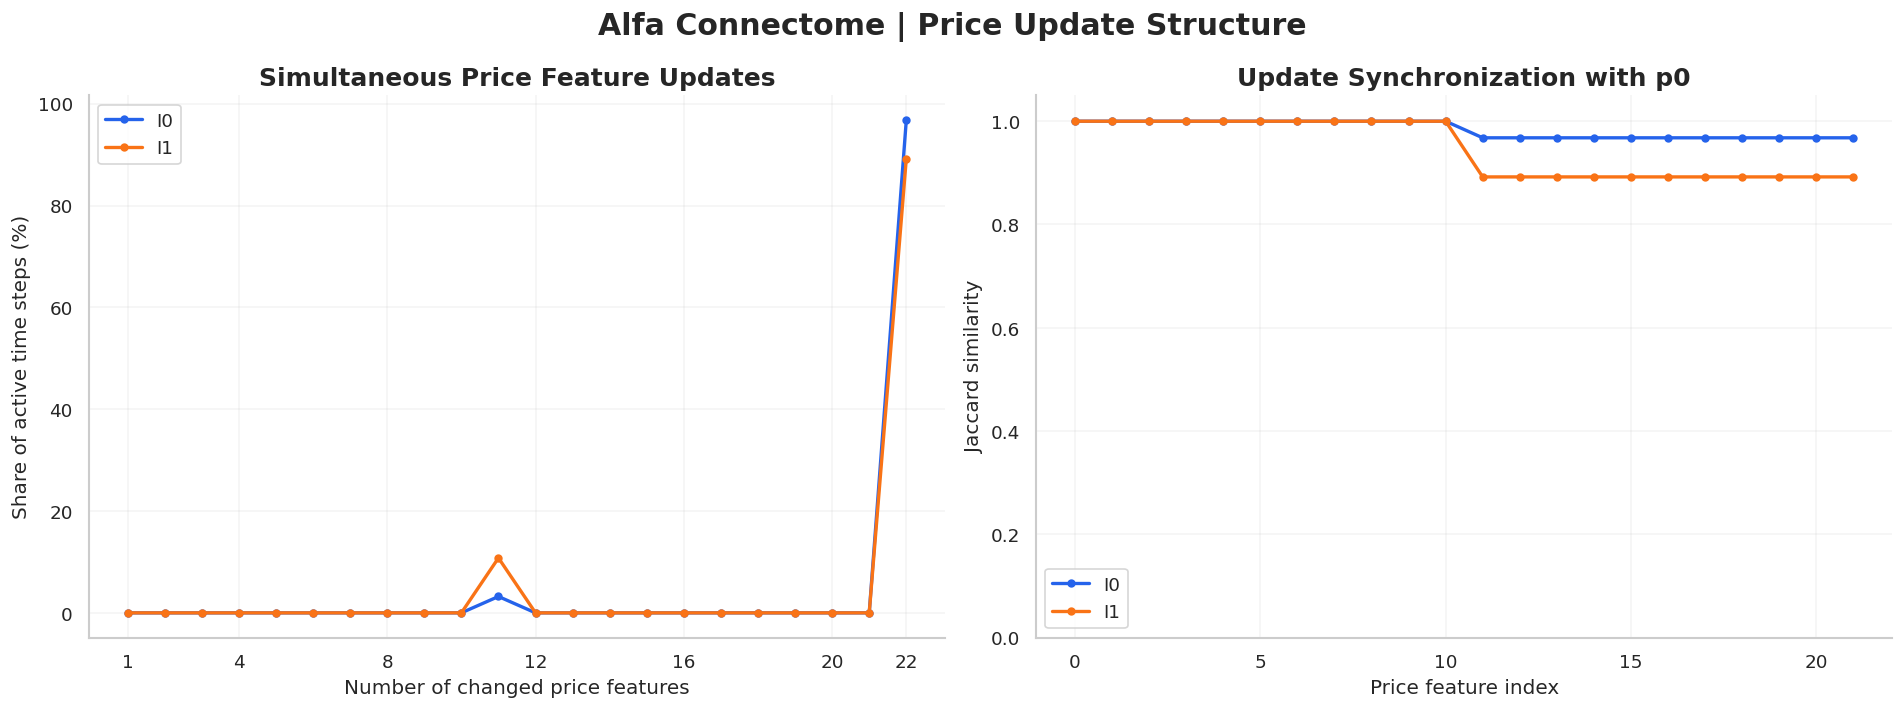

In [26]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

price_cols = {
    "i0": [f"i0_p{i}" for i in range(22)],
    "i1": [f"i1_p{i}" for i in range(22)]
}

update_hist = {
    name: np.zeros(23, dtype=np.int64)
    for name in price_cols
}

intersection = {
    name: np.zeros(22, dtype=np.int64)
    for name in price_cols
}

union = {
    name: np.zeros(22, dtype=np.int64)
    for name in price_cols
}

cross_intersection = 0
cross_union = 0

for idx in selected_ids:
    columns = price_cols["i0"] + price_cols["i1"]

    data = pf.read_row_group(
        int(idx), columns=columns
    ).to_pandas()

    X = data.to_numpy(dtype=np.float32)[99:]

    changed = np.abs(np.diff(X, axis=0)) > 1e-6

    active_groups = {}

    for name, sl in [
        ("i0", slice(0, 22)),
        ("i1", slice(22, 44))
    ]:
        C = changed[:, sl]
        n_changed = C.sum(axis=1)

        update_hist[name] += np.bincount(
            n_changed, minlength=23
        )

        ref = C[:, [0]]

        intersection[name] += (C & ref).sum(axis=0)
        union[name] += (C | ref).sum(axis=0)

        active_groups[name] = n_changed > 0

    cross_intersection += np.sum(
        active_groups["i0"] & active_groups["i1"]
    )
    cross_union += np.sum(
        active_groups["i0"] | active_groups["i1"]
    )

summary = []

for name in ["i0", "i1"]:
    counts = update_hist[name]

    total = counts.sum()
    active = counts[1:].sum()

    summary.append({
        "instrument": name,
        "any_price_change": active / total,
        "all_prices_change": counts[22] / total,
        "mean_channels_when_active": (
            np.dot(np.arange(23), counts) / active
        )
    })

summary_df = pd.DataFrame(summary)

print("=== СИНХРОННОСТЬ ЦЕНОВЫХ ПРИЗНАКОВ ===")
display(summary_df.round(4))

print(
    "Jaccard обновлений между инструментами:",
    round(cross_intersection / cross_union, 4)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

colors = {"i0": "#2563EB", "i1": "#F97316"}

# Сколько ценовых признаков меняется одновременно
for name in ["i0", "i1"]:
    counts = update_hist[name][1:]
    percentage = counts / counts.sum() * 100

    axes[0].plot(
        np.arange(1, 23),
        percentage,
        marker="o",
        markersize=4,
        linewidth=2,
        label=name.upper(),
        color=colors[name]
    )

axes[0].set_title("Simultaneous Price Feature Updates")
axes[0].set_xlabel("Number of changed price features")
axes[0].set_ylabel("Share of active time steps (%)")
axes[0].set_xticks([1, 4, 8, 12, 16, 20, 22])
axes[0].legend()
axes[0].grid(alpha=0.2)

# Насколько события изменения совпадают с p0
for name in ["i0", "i1"]:
    jaccard = np.divide(
        intersection[name],
        union[name],
        out=np.zeros(22, dtype=float),
        where=union[name] > 0
    )

    axes[1].plot(
        range(22),
        jaccard,
        marker="o",
        markersize=4,
        linewidth=2,
        label=name.upper(),
        color=colors[name]
    )

axes[1].set_title("Update Synchronization with p0")
axes[1].set_xlabel("Price feature index")
axes[1].set_ylabel("Jaccard similarity")
axes[1].set_ylim(0, 1.05)
axes[1].legend()
axes[1].grid(alpha=0.2)

fig.suptitle(
    "Alfa Connectome | Price Update Structure",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()

fig_dir = Path("/content/eda_figures")
fig_dir.mkdir(exist_ok=True)

plt.savefig(
    fig_dir / "price_update_structure.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()



### 3.4. Синхронность обновления ценовых признаков

Исследованы события изменения 22 ценовых признаков каждого инструмента на 30 случайных последовательностях из `train.parquet`.

Изменением считалась разница между соседними наблюдениями по модулю более \(10^{-6}\).

#### Результаты

| Показатель | i0 | i1 |
|---|---:|---:|
| Шаги с изменением хотя бы одного ценового признака | 27.18% | 9.74% |
| Шаги с изменением всех 22 признаков | 26.30% | 8.69% |
| Среднее число изменившихся признаков при обновлении | 21.65 | 20.81 |
| Доля полных обновлений среди активных шагов | 96.8% | 89.2% |

Коэффициент Жаккара между событиями обновления двух инструментов составляет **0.0492**.

#### Основные наблюдения

**1. Ценовые признаки внутри инструментов обновляются синхронно.**

В большинстве моментов изменения цен обновляются практически все 22 признака соответствующего инструмента.

**2. Обнаружена внутренняя блочная структура.**

Признаки `p0`–`p10` характеризуются полным совпадением моментов изменений с `p0`.

Для `p11`–`p21` сходство несколько ниже, особенно у второго инструмента.

Это позволяет предположить наличие двух связанных групп признаков, но их экономический смысл требует проверки.

**3. Два инструмента обновляются преимущественно асинхронно.**

Низкое значение межинструментального коэффициента Жаккара показывает, что обновления цен двух инструментов редко происходят одновременно.

**4. Совпадение моментов обновления не доказывает избыточность признаков.**

Несколько признаков могут изменяться одновременно, сохраняя различную информацию в своих значениях.

#### Гипотезы для моделирования

- События обновления цен могут служить дополнительными индикаторами рыночной активности.
- Раздельное представление ценовых групп `i0` и `i1` может быть полезно.
- Для каждой группы могут существовать общие компоненты изменения, которые стоит исследовать отдельно.

#### Практические рекомендации

**Стоит:**
- Проверить связь событий обновления цен с величиной целевых переменных.
- Исследовать корреляции самих ценовых изменений.
- Проверить добавление бинарных индикаторов обновления цен.
- Рассмотреть отдельную обработку двух инструментов.

**Не стоит:**
- Удалять признаки только из-за синхронного обновления.
- Считать совпадение моментов изменений доказательством совпадения значений.
- Предполагать порядок уровней стакана без подтверждения документацией.
- Утверждать, что дополнительные признаки улучшат качество модели без эксперимента.

#### Ограничения

Результаты получены на 30 последовательностях. Выявленные закономерности пока не проверены непосредственно на качество прогноза.

**Статус:** подтверждённая на исследованной выборке групповая структура обновлений. Прогностическая полезность не установлена.


=== ОБНОВЛЕНИЯ ЦЕН И КРУПНЫЕ ЦЕЛИ ===

Вероятность |target| >= 1 по типам событий:


,n,large_t0,large_t1,P_large_t0,P_large_t1
event_group,,,,,
No update,386974,92203,93665,0.2383,0.2420
Only i0,151917,15355,16977,0.1011,0.1118
Only i1,47796,11628,11826,0.2433,0.2474
Both,10343,1772,1874,0.1713,0.1812



Разница внутри последовательностей, п.п.:


mean  median  count
instrument target                      
i0         t0     -8.794  -8.591     30
           t1     -9.171  -9.078     30
i1         t0      5.819   3.200     29
           t1      5.417   2.545     29

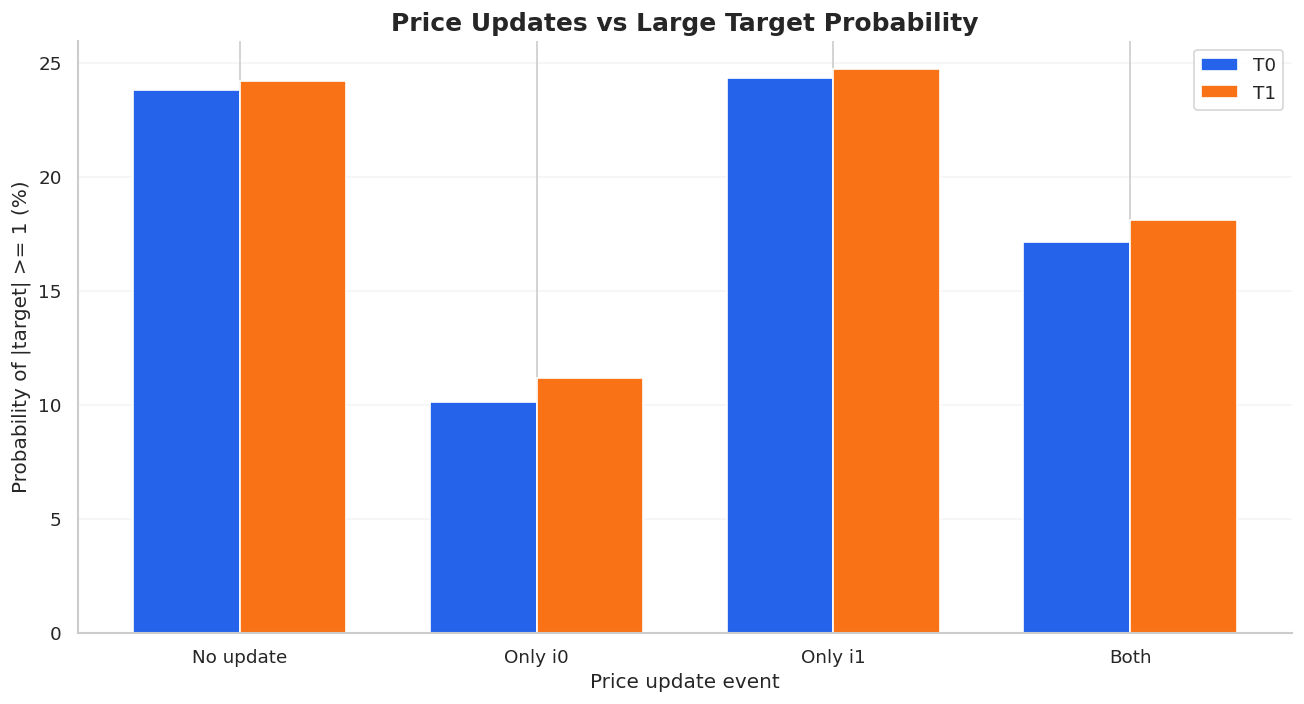

In [27]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

price0 = [f"i0_p{i}" for i in range(22)]
price1 = [f"i1_p{i}" for i in range(22)]

event_names = [
    "No update",
    "Only i0",
    "Only i1",
    "Both"
]

records = []
effects = []

for idx in selected_ids:
    cols = (
        price0 + price1
        + ["need_prediction", "t0", "t1"]
    )

    data = pf.read_row_group(
        int(idx), columns=cols
    ).to_pandas()

    X0 = data[price0].to_numpy(dtype=np.float32)
    X1 = data[price1].to_numpy(dtype=np.float32)

    # Текущий шаг сравнивается только с предыдущим
    e0 = (np.abs(np.diff(X0, axis=0)) > 1e-6).any(axis=1)
    e1 = (np.abs(np.diff(X1, axis=0)) > 1e-6).any(axis=1)

    valid = data["need_prediction"].to_numpy(dtype=bool)[1:]

    # 0: нет обновлений, 1: i0, 2: i1, 3: оба
    category = e0.astype(int) + 2 * e1.astype(int)

    y0 = data["t0"].to_numpy()[1:]
    y1 = data["t1"].to_numpy()[1:]

    large0 = np.abs(y0) >= 1
    large1 = np.abs(y1) >= 1

    for k, name in enumerate(event_names):
        mask = valid & (category == k)

        records.append({
            "sequence": int(idx),
            "event_group": name,
            "n": int(mask.sum()),
            "large_t0": int((mask & large0).sum()),
            "large_t1": int((mask & large1).sum())
        })

    # Сравнение внутри последовательностей
    for instrument, event in [("i0", e0), ("i1", e1)]:
        on = valid & event
        off = valid & ~event

        if on.sum() < 50 or off.sum() < 50:
            continue

        for target, large in [
            ("t0", large0), ("t1", large1)
        ]:
            effects.append({
                "sequence": int(idx),
                "instrument": instrument,
                "target": target,
                "delta_pp": 100 * (
                    large[on].mean() - large[off].mean()
                )
            })

summary = (
    pd.DataFrame(records)
    .groupby("event_group")[["n", "large_t0", "large_t1"]]
    .sum()
    .reindex(event_names)
)

for target in ["t0", "t1"]:
    summary[f"P_large_{target}"] = (
        summary[f"large_{target}"] / summary["n"]
    )

effect_df = pd.DataFrame(effects)

effect_summary = effect_df.groupby(
    ["instrument", "target"]
)["delta_pp"].agg(["mean", "median", "count"])

print("=== ОБНОВЛЕНИЯ ЦЕН И КРУПНЫЕ ЦЕЛИ ===")

print("\nВероятность |target| >= 1 по типам событий:")
display(summary.round(4))

print("\nРазница внутри последовательностей, п.п.:")
display(effect_summary.round(3))

fig, ax = plt.subplots(figsize=(11, 6))

x = np.arange(len(event_names))
width = 0.36

for j, target in enumerate(["t0", "t1"]):
    ax.bar(
        x + (j - 0.5) * width,
        summary[f"P_large_{target}"] * 100,
        width,
        label=target.upper(),
        color=["#2563EB", "#F97316"][j]
    )

ax.set_xticks(x, event_names)
ax.set_ylabel("Probability of |target| >= 1 (%)")
ax.set_xlabel("Price update event")
ax.set_title("Price Updates vs Large Target Probability")
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()



### 3.5. Связь обновлений цен с крупными целевыми значениями

Исследована связь событий обновления ценовых признаков с величиной целевых переменных на 30 последовательностях из `train.parquet`.

Событием крупной цели считалось:

\[
|t_j(k)| \geq 1,\qquad j\in\{0,1\}.
\]

Для каждого шага выделялись четыре категории: отсутствие обновлений, обновление только `i0`, только `i1` и одновременное обновление обоих инструментов.

#### Результаты

| Событие | Число строк | P(|t0| >= 1) | P(|t1| >= 1) |
|---|---:|---:|---:|
| Нет обновлений | 386 974 | 23.83% | 24.20% |
| Только i0 | 151 917 | 10.11% | 11.18% |
| Только i1 | 47 796 | 24.33% | 24.74% |
| Оба инструмента | 10 343 | 17.13% | 18.12% |

При сравнении внутри последовательностей получены следующие средние различия вероятностей между шагами с обновлением и без обновления соответствующего инструмента:

| Инструмент | t0 | t1 |
|---|---:|---:|
| i0 | -8.79 п.п. | -9.17 п.п. |
| i1 | +5.82 п.п. | +5.42 п.п. |

#### Основные наблюдения

1. **Обновление цен i0 связано с меньшей вероятностью крупных абсолютных значений целей.**

2. **Обновления i1 демонстрируют другую зависимость.** Во внутрипоследовательностном сравнении эффект положительный, хотя категория «только i1» близка к отсутствию обновлений по общей частоте крупных целей.

3. **События обновления двух инструментов статистически различаются.** Это согласуется с ранее обнаруженной асинхронностью ценовых обновлений.

4. **Эффекты сходны для t0 и t1.** Это дополнительно подтверждает наличие общих закономерностей в поведении целевых переменных.

#### Практические рекомендации

**Стоит:**
- Проверить бинарные признаки обновления цен каждого инструмента.
- Исследовать временные интервалы с момента последнего обновления.
- Проверить, сохраняется ли эффект на независимых последовательностях.
- Сравнить качество модели с дополнительными признаками и без них.

**Не стоит:**
- Считать обновление цен причиной изменения величины целей.
- Интерпретировать статистическую связь как гарантированное улучшение прогноза.
- Использовать будущие значения входных признаков при вычислении событий обновления.

#### Ограничения

Анализ выполнен на 30 последовательностях, без учёта официальной маски `is_scored`.

Результаты характеризуют статистические зависимости, но не измеряют непосредственно качество предсказаний.

**Статус:** обнаружена эмпирическая связь, требующая проверки в модельном эксперименте.


=== КОРРЕЛЯЦИИ ЦЕНОВЫХ ПРИЗНАКОВ ===
Исследовано наблюдений: 30000

Медианная абсолютная корреляция:

Уровни цен:
  Внутри i0: 0.5176
  Внутри i1: 0.4321
  Между i0 и i1: 0.0169

Изменения цен:
  Внутри i0: 0.5541
  Внутри i1: 0.4669
  Между i0 и i1: 0.0033


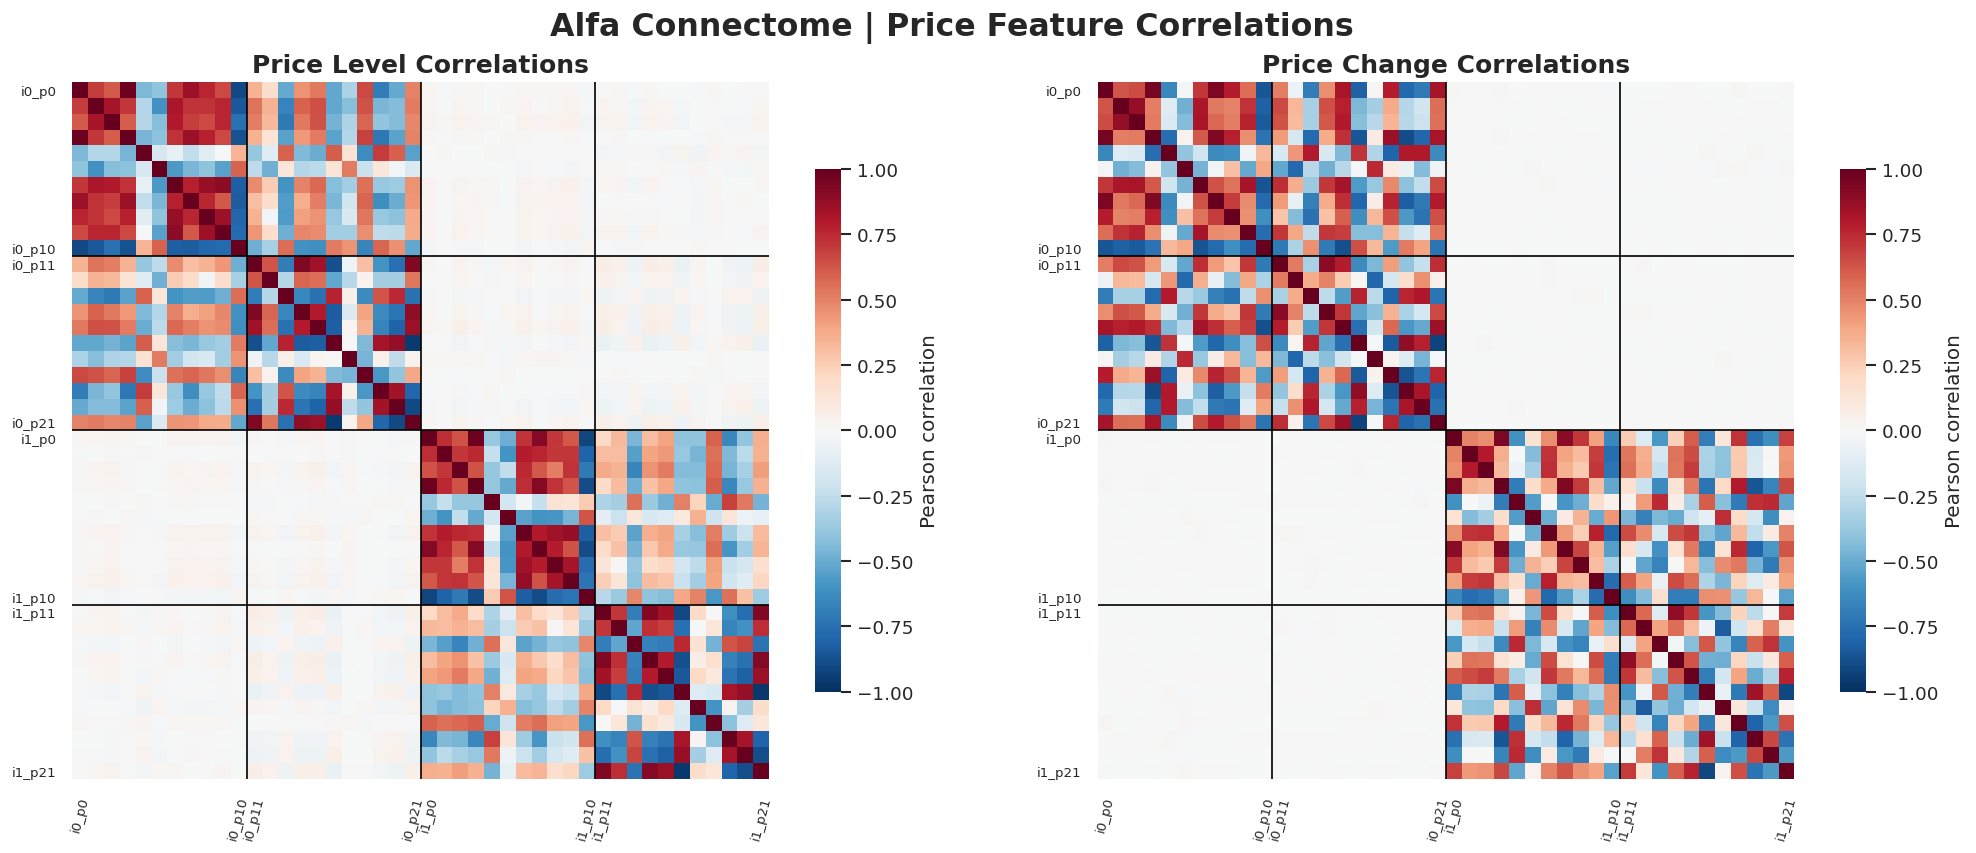

In [28]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

price_columns = (
    [f"i0_p{i}" for i in range(22)]
    + [f"i1_p{i}" for i in range(22)]
)

rng = np.random.default_rng(42)

level_parts = []
delta_parts = []

# Используем те же 30 последовательностей
for idx in selected_ids:
    table = pf.read_row_group(
        int(idx),
        columns=price_columns
    )

    X = table.to_pandas().to_numpy(
        dtype=np.float64
    )[99:]

    # Изменения между соседними шагами
    dX = np.diff(X, axis=0)

    # Для анализа уровней убираем среднее
    # каждой последовательности (только в EDA)
    centered_X = X[1:] - X[1:].mean(
        axis=0, keepdims=True
    )

    # Выбираем одинаковые моменты для двух анализов
    pick = rng.choice(
        len(dX),
        size=min(1000, len(dX)),
        replace=False
    )

    level_parts.append(centered_X[pick])
    delta_parts.append(dX[pick])

levels = np.concatenate(level_parts)
deltas = np.concatenate(delta_parts)

corr_levels = np.corrcoef(
    levels, rowvar=False
)

corr_deltas = np.corrcoef(
    deltas, rowvar=False
)

def median_abs_corr(matrix, start, end):
    sub = matrix[start:end, start:end]
    values = np.abs(
        sub[np.triu_indices(len(sub), k=1)]
    )
    values = values[np.isfinite(values)]
    return np.median(values) if len(values) else np.nan

def cross_abs_corr(matrix):
    values = np.abs(matrix[:22, 22:]).ravel()
    values = values[np.isfinite(values)]
    return np.median(values) if len(values) else np.nan

print("=== КОРРЕЛЯЦИИ ЦЕНОВЫХ ПРИЗНАКОВ ===")
print("Исследовано наблюдений:", len(levels))

print("\nМедианная абсолютная корреляция:")
for name, matrix in [
    ("Уровни цен", corr_levels),
    ("Изменения цен", corr_deltas)
]:
    print(f"\n{name}:")
    print(
        "  Внутри i0:",
        round(median_abs_corr(matrix, 0, 22), 4)
    )
    print(
        "  Внутри i1:",
        round(median_abs_corr(matrix, 22, 44), 4)
    )
    print(
        "  Между i0 и i1:",
        round(cross_abs_corr(matrix), 4)
    )

fig, axes = plt.subplots(
    1, 2, figsize=(17, 7),
    constrained_layout=True
)

matrices = [corr_levels, corr_deltas]

titles = [
    "Price Level Correlations",
    "Price Change Correlations"
]

ticks = [0, 10, 11, 21, 22, 32, 33, 43]
tick_labels = [price_columns[i] for i in ticks]

for ax, matrix, title in zip(
    axes, matrices, titles
):
    sns.heatmap(
        matrix,
        ax=ax,
        cmap="RdBu_r",
        vmin=-1,
        vmax=1,
        center=0,
        square=True,
        xticklabels=False,
        yticklabels=False,
        cbar_kws={
            "label": "Pearson correlation",
            "shrink": 0.75
        }
    )

    for boundary in [11, 22, 33]:
        ax.axhline(boundary, color="black", lw=1)
        ax.axvline(boundary, color="black", lw=1)

    ax.set_xticks(np.array(ticks) + 0.5)
    ax.set_yticks(np.array(ticks) + 0.5)

    ax.set_xticklabels(
        tick_labels, rotation=75, fontsize=8
    )
    ax.set_yticklabels(
        tick_labels, rotation=0, fontsize=8
    )

    ax.set_title(title, fontsize=15)

fig.suptitle(
    "Alfa Connectome | Price Feature Correlations",
    fontsize=19,
    fontweight="bold"
)

plt.savefig(
    "/content/eda_figures/price_correlations.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()



### 3.6. Корреляционная структура ценовых признаков

Исследованы 44 ценовых признака двух инструментов на выборке из 30 000 наблюдений, полученных из 30 последовательностей.

Рассмотрены:
- Уровни ценовых признаков с вычитанием среднего внутри каждой последовательности.
- Изменения признаков между соседними временными шагами.

#### Медианная абсолютная корреляция

| Группа | Уровни цен | Изменения цен |
|---|---:|---:|
| Внутри i0 | 0.5176 | 0.5541 |
| Внутри i1 | 0.4321 | 0.4669 |
| Между i0 и i1 | 0.0169 | 0.0033 |

#### Основные наблюдения

**1. Внутри каждого инструмента существует выраженная корреляционная структура.**

Значительная часть ценовых признаков связана положительно или отрицательно. Для первого инструмента связи в среднем сильнее, чем для второго.

**2. Обнаружено визуальное разделение на две группы по 11 признаков.**

На тепловых картах прослеживаются блоки `p0`–`p10` и `p11`–`p21`. Такая структура согласуется с ранее обнаруженной синхронностью обновлений.

Экономический смысл этих блоков пока не установлен.

**3. Между инструментами слабая одновременная линейная зависимость ценовых признаков.**

Медианная абсолютная корреляция между инструментами близка к нулю как для уровней, так и для изменений цен.

Это не исключает нелинейных, запаздывающих и условных зависимостей.

**4. Корреляция изменений несколько выше корреляции уровней внутри инструментов.**

Это согласуется с наличием общих компонентов ценовых обновлений.

#### Гипотезы

- Ценовые признаки могут иметь эффективную размерность меньше 22.
- Внутри каждого инструмента могут существовать общие факторы изменения цен.
- Дополнительную информацию могут содержать разности и относительные значения ценовых признаков.
- Межинструментальные зависимости могут проявляться с временными задержками.

#### Практические рекомендации

**Стоит:**
- Проверить эффективную размерность ценовых признаков с помощью PCA.
- Исследовать временные связи между инструментами.
- Сравнить исходные признаки с компактными производными представлениями.
- Проверять любые изменения состава признаков по официальной метрике.

**Не стоит:**
- Удалять признаки только из-за корреляции.
- Считать слабую одновременную корреляцию доказательством отсутствия прогностической связи.
- Интерпретировать блоки как bid/ask без подтверждения их смысла.

#### Ограничения

Результаты получены на выборке из 30 последовательностей. Центрирование выполнялось с использованием всей последовательности исключительно для EDA; при потоковом прогнозировании такую операцию выполнять нельзя.

**Статус:** обнаружена устойчивая на исследованной выборке корреляционная структура. Возможность сокращения размерности ещё не проверена.


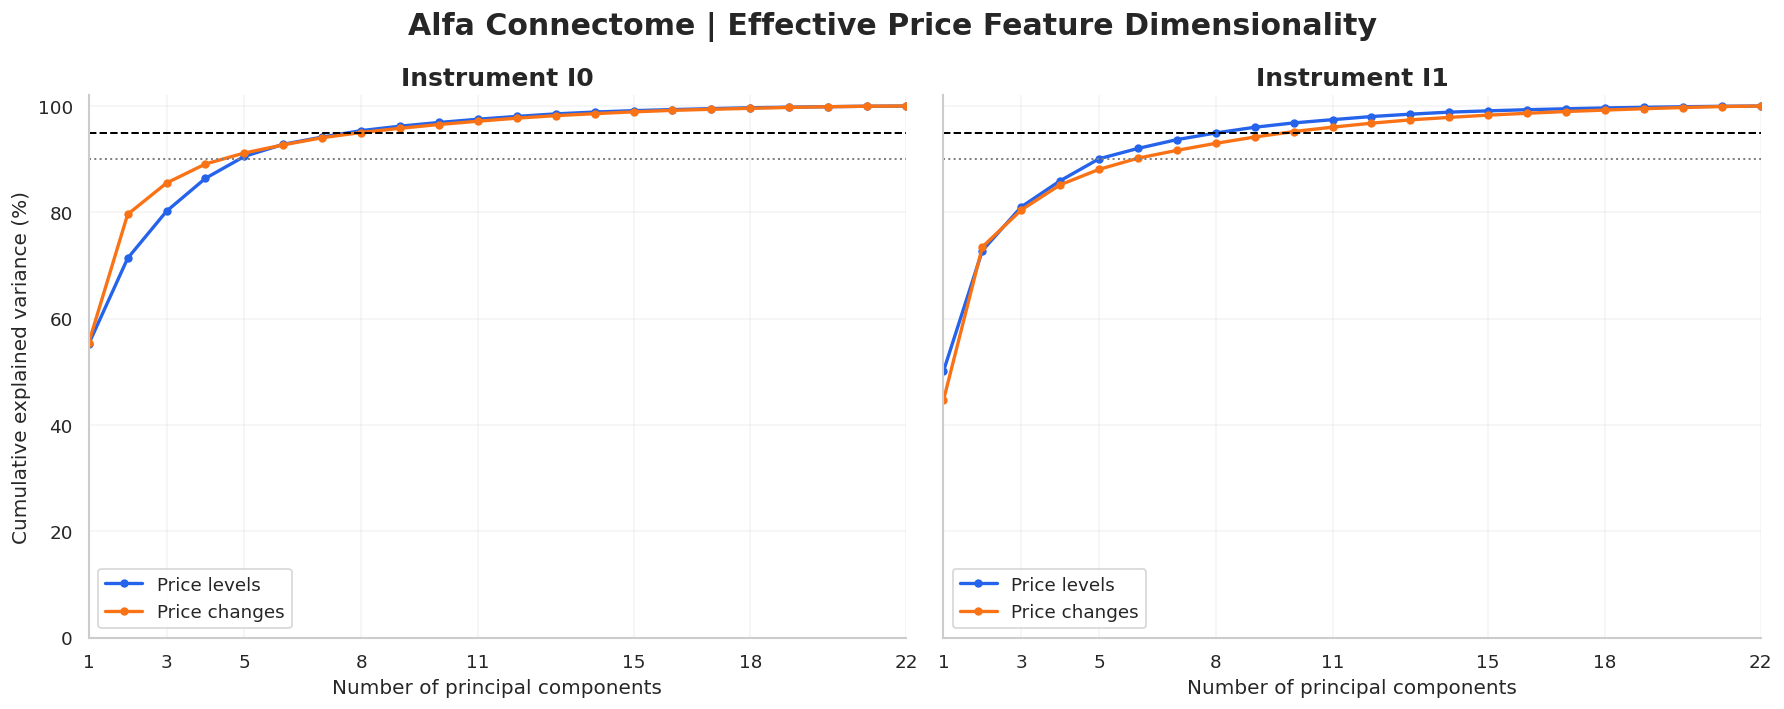

=== PCA: ЭФФЕКТИВНАЯ РАЗМЕРНОСТЬ ===


,instrument,data,components_90,components_95,components_99,first_component
0,i0,Price levels,5,8,15,55.241
1,i0,Price changes,5,8,16,55.473
2,i1,Price levels,5,9,15,50.069
3,i1,Price changes,6,10,18,44.594


In [29]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Используем levels и deltas из предыдущего эксперимента.
# Они содержат 30 000 наблюдений и 44 ценовых признака.

datasets = {
    "Price levels": levels,
    "Price changes": deltas
}

instruments = {
    "i0": slice(0, 22),
    "i1": slice(22, 44)
}

results_pca = []

fig, axes = plt.subplots(
    1, 2, figsize=(15, 6),
    sharex=True, sharey=True
)

colors = {
    "Price levels": "#2563EB",
    "Price changes": "#F97316"
}

for ax, (instrument, sl) in zip(
    axes, instruments.items()
):
    for data_name, X in datasets.items():

        X_part = X[:, sl]

        # Масштабируем признаки для корректного PCA.
        X_scaled = StandardScaler().fit_transform(X_part)

        pca = PCA()
        pca.fit(X_scaled)

        cumulative = np.cumsum(
            pca.explained_variance_ratio_
        )

        n90 = np.searchsorted(cumulative, 0.90) + 1
        n95 = np.searchsorted(cumulative, 0.95) + 1
        n99 = np.searchsorted(cumulative, 0.99) + 1

        results_pca.append({
            "instrument": instrument,
            "data": data_name,
            "components_90": n90,
            "components_95": n95,
            "components_99": n99,
            "first_component": (
                pca.explained_variance_ratio_[0] * 100
            )
        })

        ax.plot(
            np.arange(1, 23),
            cumulative * 100,
            marker="o",
            markersize=4,
            linewidth=2,
            color=colors[data_name],
            label=data_name
        )

    ax.axhline(
        90, color="gray", linestyle=":",
        linewidth=1.2
    )
    ax.axhline(
        95, color="black", linestyle="--",
        linewidth=1.2
    )

    ax.set_title(f"Instrument {instrument.upper()}")
    ax.set_xlabel("Number of principal components")
    ax.set_xticks([1, 3, 5, 8, 11, 15, 18, 22])
    ax.set_ylim(0, 102)
    ax.set_xlim(1, 22)
    ax.grid(alpha=0.2)
    ax.legend()

axes[0].set_ylabel("Cumulative explained variance (%)")

fig.suptitle(
    "Alfa Connectome | Effective Price Feature Dimensionality",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

pca_summary = pd.DataFrame(results_pca)

print("=== PCA: ЭФФЕКТИВНАЯ РАЗМЕРНОСТЬ ===")
display(pca_summary.round(3))



### 3.7. Эффективная размерность ценовых признаков: PCA

Проведён анализ главных компонент (PCA) для 22 ценовых признаков каждого инструмента.

Отдельно исследованы уровни цен и их изменения между соседними шагами. Использовано по 30 000 наблюдений, признаки предварительно стандартизированы.

#### Результаты

| Инструмент | Представление | 90% дисперсии | 95% дисперсии | 99% дисперсии | Первая компонента |
|---|---|---:|---:|---:|---:|
| i0 | Уровни | 5 | 8 | 15 | 55.24% |
| i0 | Изменения | 5 | 8 | 16 | 55.47% |
| i1 | Уровни | 5 | 9 | 15 | 50.07% |
| i1 | Изменения | 6 | 10 | 18 | 44.59% |

#### Основные выводы

1. **Ценовые признаки имеют выраженную низкоразмерную структуру.** Для сохранения 95% общей изменчивости достаточно 8–10 компонент вместо 22.

2. **Первый инструмент несколько легче поддаётся сжатию.** Это особенно заметно при анализе изменений цен.

3. **Первая главная компонента объясняет значительную часть дисперсии.** Это согласуется с ранее выявленной корреляционной структурой и синхронностью обновлений.

4. **PCA не доказывает, что остальные компоненты не нужны для прогнозирования.** Компоненты с малой объяснённой дисперсией могут содержать информацию о редких, но важных событиях.

#### Рекомендации для команды

**Стоит:**
- Сравнить исходные ценовые признаки с PCA-представлениями размерности 8, 10 и 15.
- Проверить гибридный вариант: исходные признаки плюс несколько главных компонент.
- Оценить влияние сжатия на точность и скорость инференса.
- Обучать PCA только на тренировочной части данных.

**Не стоит:**
- Удалять исходные признаки только на основании объяснённой дисперсии.
- Считать 95% сохранённой дисперсии эквивалентом 95% сохранённой прогностической информации.
- Центрировать тестовые признаки по всей последовательности: это использовало бы будущие наблюдения.

#### Ограничения

Анализ выполнен на выборке из 30 последовательностей. Полученные значения характеризуют структуру изменчивости входов, но не качество предсказания целевых переменных.

**Статус:** подтверждена низкоразмерная корреляционная структура; эффективность PCA для прогнозирования требует эксперимента.


=== СВЯЗЬ ПРИЗНАКОВ С ЦЕЛЯМИ ===
Последовательностей: 30
Признаков: 112

ТОП-15 комбинаций признака, представления и цели:


,,,median_abs_corr
feature,mode,target,
i0_p11,Level,t1,0.1579
i0_p18,Level,t0,0.1568
i0_v4,Level,t1,0.1533
i0_p14,Level,t1,0.1515
i0_p3,Level,t0,0.1515
i0_p1,Level,t1,0.1485
i0_p10,Level,t0,0.1437
i0_p0,Level,t0,0.1426
i0_p8,Level,t0,0.1426


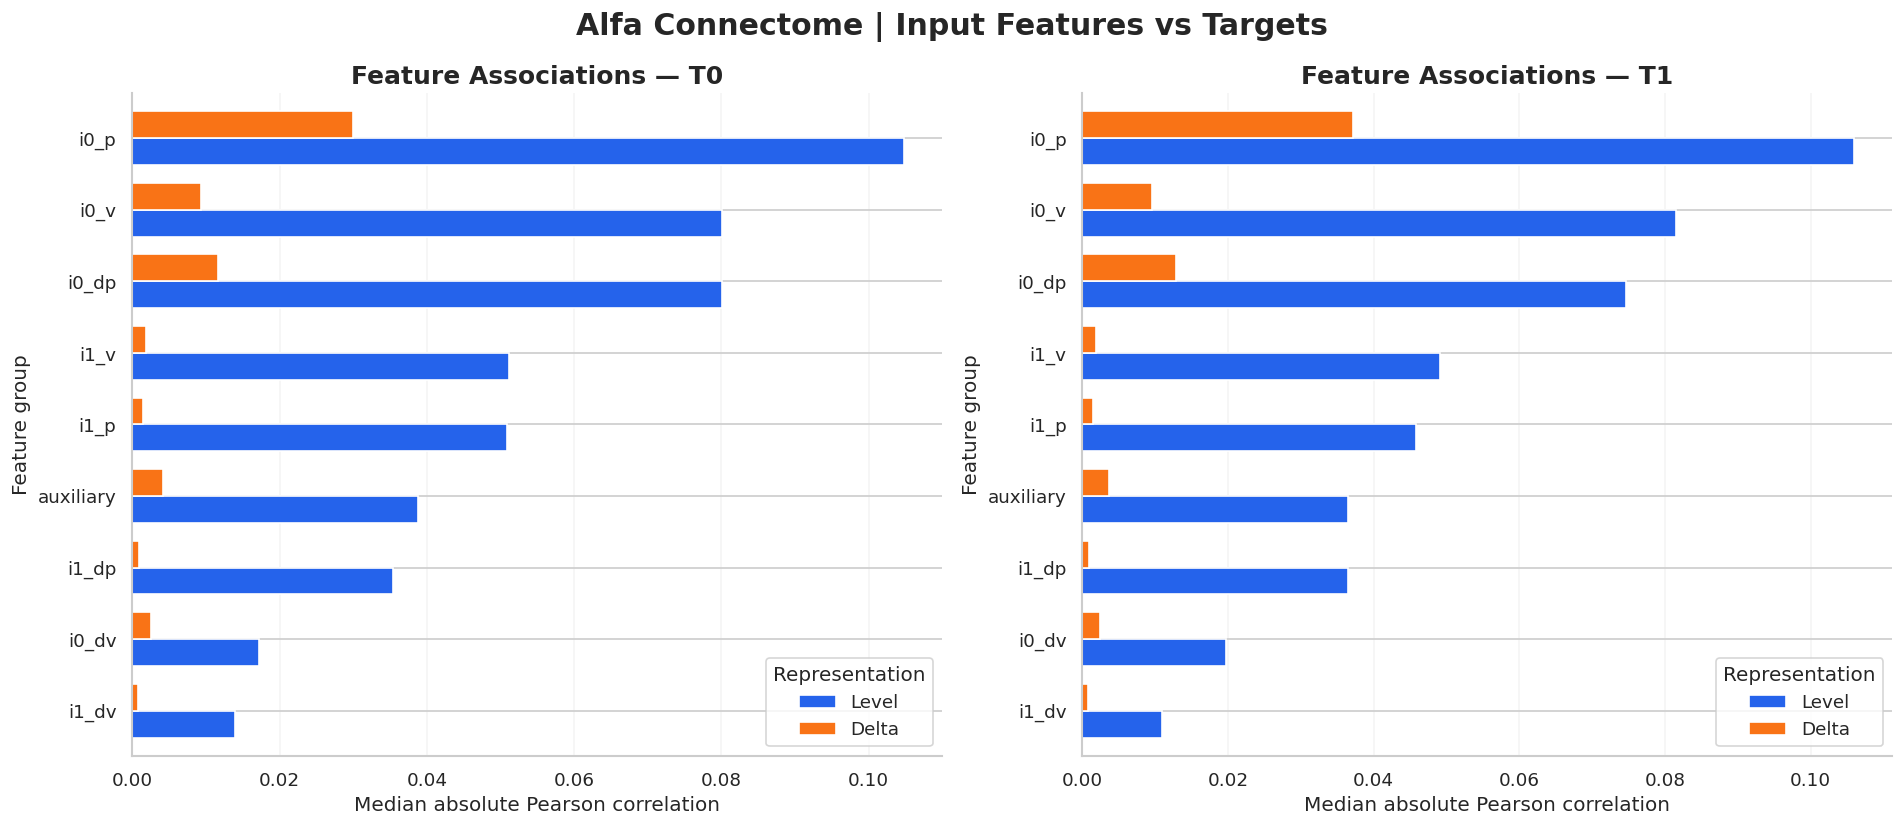

In [30]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

feature_cols = [
    c for c in pf.schema_arrow.names
    if c not in {
        "seq_ix", "step_in_seq",
        "need_prediction", "is_scored", "t0", "t1"
    }
]

records = []

for idx in selected_ids:
    data = pf.read_row_group(
        int(idx),
        columns=feature_cols + [
            "need_prediction", "t0", "t1"
        ]
    ).to_pandas()

    X = data[feature_cols].to_numpy(dtype=np.float32)
    Y = data[["t0", "t1"]].to_numpy(dtype=np.float64)
    Y = np.clip(Y, -2, 2)

    indices = np.flatnonzero(
        data["need_prediction"].to_numpy(dtype=bool)
    )
    indices = indices[indices > 0]

    y = Y[indices]
    yc = y - y.mean(axis=0)
    ynorm = np.sqrt((yc ** 2).sum(axis=0))

    representations = {
        "Level": X[indices],
        "Delta": X[indices] - X[indices - 1]
    }

    for mode, matrix in representations.items():
        A = matrix.astype(np.float64)
        A -= A.mean(axis=0)

        numerator = A.T @ yc
        denominator = (
            np.sqrt((A ** 2).sum(axis=0))[:, None]
            * ynorm[None, :]
        )

        corr = np.divide(
            numerator,
            denominator,
            out=np.full_like(numerator, np.nan),
            where=denominator > 1e-12
        )

        for j, feature in enumerate(feature_cols):
            for k, target in enumerate(["t0", "t1"]):
                records.append({
                    "sequence": int(idx),
                    "feature": feature,
                    "mode": mode,
                    "target": target,
                    "correlation": corr[j, k]
                })

corr_df = pd.DataFrame(records)
corr_df["abs_corr"] = corr_df["correlation"].abs()

def get_group(feature):
    if feature.startswith("a"):
        return "auxiliary"
    prefix, suffix = feature.split("_", 1)
    kind = suffix.rstrip("0123456789")
    return f"{prefix}_{kind}"

corr_df["group"] = corr_df["feature"].map(get_group)

group_corr = (
    corr_df.groupby(["group", "mode", "target"])
    ["abs_corr"].median()
    .reset_index()
)

top_features = (
    corr_df.groupby(["feature", "mode", "target"])
    ["abs_corr"].median()
    .sort_values(ascending=False)
    .head(15)
)

print("=== СВЯЗЬ ПРИЗНАКОВ С ЦЕЛЯМИ ===")
print("Последовательностей:", len(selected_ids))
print("Признаков:", len(feature_cols))

print("\nТОП-15 комбинаций признака, представления и цели:")
display(top_features.round(4).to_frame("median_abs_corr"))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, target in zip(axes, ["t0", "t1"]):
    part = group_corr[group_corr["target"] == target]

    pivot = part.pivot(
        index="group",
        columns="mode",
        values="abs_corr"
    ).sort_values("Level")

    pivot[["Level", "Delta"]].plot.barh(
        ax=ax,
        color=["#2563EB", "#F97316"],
        width=0.75
    )

    ax.set_title(f"Feature Associations — {target.upper()}")
    ax.set_xlabel("Median absolute Pearson correlation")
    ax.set_ylabel("Feature group")
    ax.grid(axis="x", alpha=0.2)
    ax.legend(title="Representation")

fig.suptitle(
    "Alfa Connectome | Input Features vs Targets",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



### 3.8. Линейная связь входных признаков с целевыми переменными

Исследована корреляция 112 входных признаков с целевыми переменными `t0` и `t1` на 30 последовательностях из `train.parquet`.

Для каждого признака рассмотрены два представления:
- **Level** — исходное значение признака на текущем шаге.
- **Delta** — разность между текущим и предыдущим значениями.

Корреляции Пирсона рассчитывались отдельно внутри каждой последовательности, после чего для сравнения использовалась медиана абсолютных корреляций.

Целевые переменные ограничивались интервалом [-2, 2], как предусмотрено официальной метрикой.

#### Основные результаты

Наибольшие значения медианной абсолютной корреляции:

| Признак | Представление | Цель | Корреляция |
|---|---|---|---:|
| i0_p11 | Level | t1 | 0.1579 |
| i0_p18 | Level | t0 | 0.1568 |
| i0_v4 | Level | t1 | 0.1533 |
| i0_p14 | Level | t1 | 0.1515 |
| i0_p3 | Level | t0 | 0.1515 |

#### Основные наблюдения

1. **Признаки первого инструмента демонстрируют наиболее выраженную линейную связь с целями.**

Все 15 лидирующих комбинаций относятся к первому инструменту.

2. **Исходные значения признаков сильнее коррелируют с целями, чем их одноступенчатые разности.**

Это наблюдается для большинства исследованных групп.

3. **Индивидуальные корреляции остаются относительно небольшими.**

Даже у лидирующих признаков медианная абсолютная корреляция составляет около 0.15–0.16.

4. **Дополнительные признаки могут содержать нелинейные зависимости.**

Низкие линейные корреляции не противоречат ранее обнаруженной связи специальных значений в a5–a7 с крупными целевыми переменными.

5. **Слабая индивидуальная корреляция не означает бесполезность признака.**

Признак может содержать информацию во взаимодействии с другими входами или на различных временных горизонтах.

#### Практические рекомендации

**Стоит:**
- Уделить особое внимание совместной обработке ценовых и объёмных признаков i0.
- Проверить устойчивость направления корреляций между последовательностями.
- Сравнить модели с исходными признаками и с дополнительными разностями.
- Исследовать нелинейные зависимости и взаимодействия признаков.

**Не стоит:**
- Удалять признаки i1 или a0–a7 только из-за слабой корреляции Пирсона.
- Считать высокий уровень корреляции гарантией полезности признака для GRU.
- Отказываться от разностей без модельного эксперимента.
- Интерпретировать медиану абсолютных корреляций как устойчивую направленную зависимость.

#### Ограничения

Анализ выполнен на 30 последовательностях без официальной маски `is_scored`.

Рейтинг основан на абсолютных корреляциях, поэтому не отражает устойчивость знака связи. Корреляция Пирсона также не учитывает нелинейные взаимодействия и сложные временные зависимости.

**Статус:** предварительное ранжирование линейных связей. Необходима проверка устойчивости направления.


=== УСТОЙЧИВОСТЬ КОРРЕЛЯЦИЙ ===


,feature,mode,target,median_abs_corr,median_signed_corr,sign_consistency,positive_share,sequences
0,i0_p11,Level,t1,0.1579,0.1579,1.0000,1.0000,30
1,i0_p18,Level,t0,0.1568,0.1568,1.0000,1.0000,30
2,i0_v4,Level,t1,0.1533,0.1438,0.7667,0.7667,30
3,i0_p14,Level,t1,0.1515,0.1515,1.0000,1.0000,30
4,i0_p3,Level,t0,0.1515,0.1515,1.0000,1.0000,30
5,i0_p1,Level,t1,0.1485,0.1473,0.9667,0.9667,30
6,i0_p10,Level,t0,0.1437,-0.1437,1.0000,0.0000,30
7,i0_p0,Level,t0,0.1426,0.1426,1.0000,1.0000,30
8,i0_p8,Level,t0,0.1426,0.1426,1.0000,1.0000,30
9,i0_p7,Level,t0,0.1392,0.1392,1.0000,1.0000,30


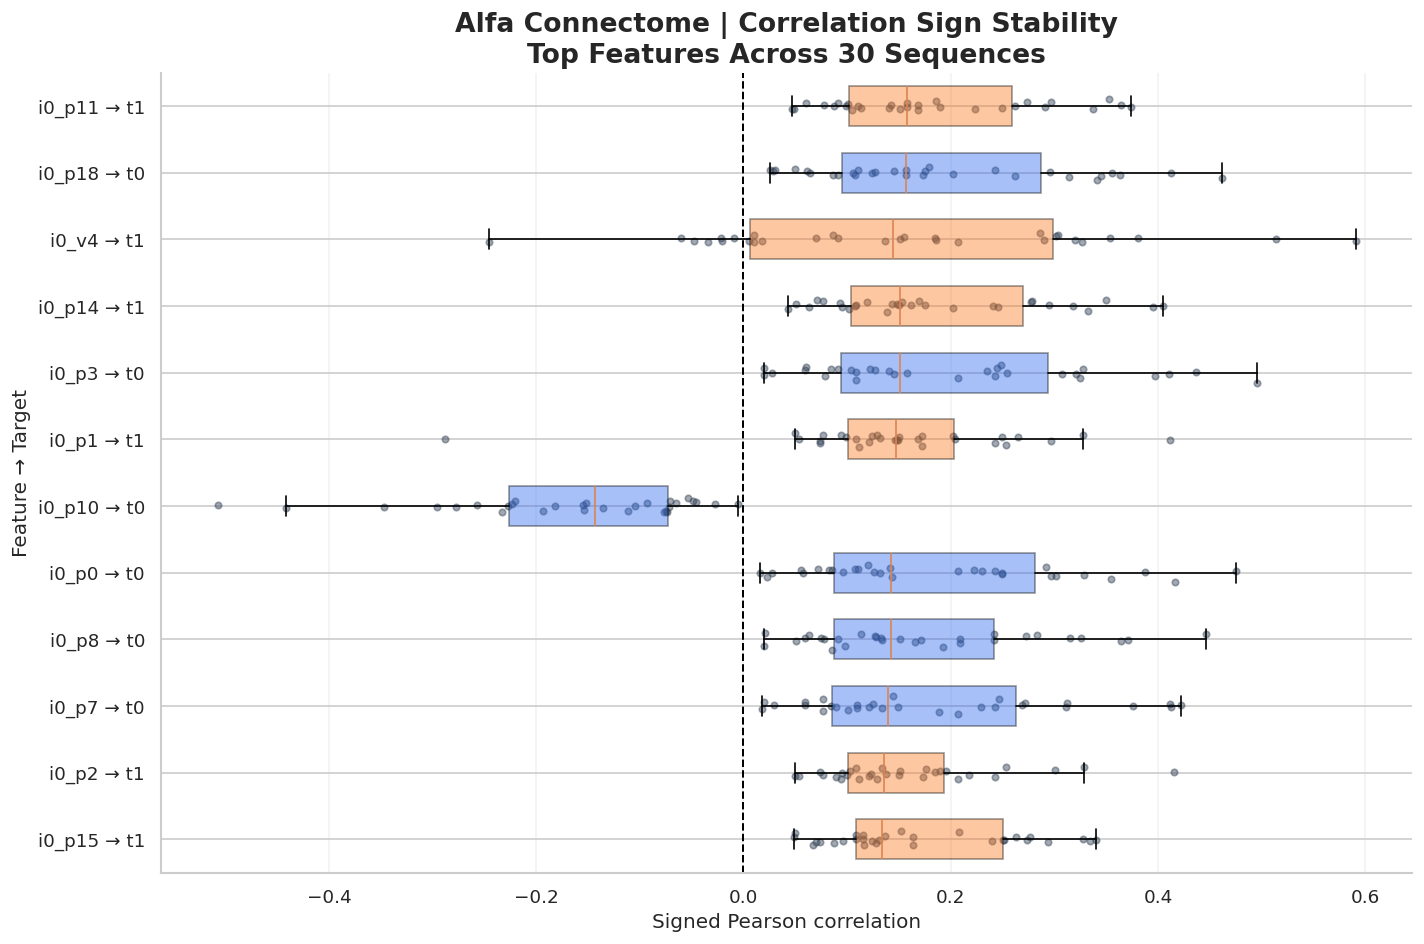

In [31]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Выбираем 12 комбинаций с наибольшей
# медианной абсолютной корреляцией.
ranking = (
    corr_df.groupby(["feature", "mode", "target"])
    ["abs_corr"].median()
    .sort_values(ascending=False)
)

top_keys = ranking.head(12).index.tolist()

rows = []
plot_values = []
labels = []

for feature, mode, target in top_keys:
    subset = corr_df[
        (corr_df["feature"] == feature)
        & (corr_df["mode"] == mode)
        & (corr_df["target"] == target)
    ]

    values = subset["correlation"].dropna().to_numpy()

    positive_rate = np.mean(values > 0)
    negative_rate = np.mean(values < 0)

    rows.append({
        "feature": feature,
        "mode": mode,
        "target": target,
        "median_abs_corr": np.median(np.abs(values)),
        "median_signed_corr": np.median(values),
        "sign_consistency": max(
            positive_rate, negative_rate
        ),
        "positive_share": positive_rate,
        "sequences": len(values)
    })

    plot_values.append(values)
    labels.append(f"{feature} → {target}")

stability_corr = pd.DataFrame(rows)

print("=== УСТОЙЧИВОСТЬ КОРРЕЛЯЦИЙ ===")
display(stability_corr.round(4))

fig, ax = plt.subplots(figsize=(12, 8))

bp = ax.boxplot(
    plot_values,
    vert=False,
    patch_artist=True,
    showfliers=False,
    widths=0.6
)

for box, (_, _, target) in zip(bp["boxes"], top_keys):
    color = "#2563EB" if target == "t0" else "#F97316"
    box.set_facecolor(color)
    box.set_alpha(0.4)

rng_plot = np.random.default_rng(42)

for i, values in enumerate(plot_values, start=1):
    jitter = rng_plot.normal(0, 0.055, size=len(values))
    ax.scatter(
        values,
        i + jitter,
        s=15,
        alpha=0.45,
        color="#334155"
    )

ax.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.2
)

ax.set_yticks(range(1, len(labels) + 1), labels)
ax.invert_yaxis()

ax.set_xlabel("Signed Pearson correlation")
ax.set_ylabel("Feature → Target")
ax.set_title(
    "Alfa Connectome | Correlation Sign Stability\n"
    "Top Features Across 30 Sequences",
    fontsize=16,
    fontweight="bold"
)

ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()



### 3.9. Устойчивость направления корреляций

Для 12 наиболее сильных комбинаций входного признака и целевой переменной проверена стабильность знака корреляции Пирсона между 30 последовательностями.

#### Основные результаты

| Признак | Цель | Медианная корреляция | Доля одинакового знака |
|---|---|---:|---:|
| i0_p11 | t1 | +0.1579 | 100% |
| i0_p18 | t0 | +0.1568 | 100% |
| i0_p14 | t1 | +0.1515 | 100% |
| i0_p3 | t0 | +0.1515 | 100% |
| i0_p10 | t0 | -0.1437 | 100% |
| i0_v4 | t1 | +0.1438 | 76.67% |

Среди 12 ведущих комбинаций 10 сохраняют знак корреляции во всех 30 последовательностях.

#### Выводы

1. **Ценовые признаки первого инструмента демонстрируют устойчивые направленные связи с целями.**

2. **Знаки корреляций различаются между ценовыми признаками.** В частности, i0_p10 отрицательно связан с t0, тогда как многие другие ценовые признаки показывают положительную связь.

3. **Объёмный признак i0_v4 менее стабилен.** Несмотря на относительно высокую медианную абсолютную корреляцию, её знак различается между последовательностями.

4. **Устойчивость знака усиливает интерес к данным признакам**, но не доказывает их независимую прогностическую ценность.

#### Рекомендации

**Стоит:**
- Проверить линейную модель на ценовых признаках i0 как простой baseline.
- Исследовать разности между ценовыми признаками с противоположными направлениями связи.
- Проверить сохранение корреляций на новых последовательностях.
- Сравнить качество исходных признаков и инженерных комбинаций по официальной метрике.

**Не стоит:**
- Использовать величины корреляций как непосредственные веса признаков нейросети.
- Считать признаки причинными факторами изменения целей.
- Считать результаты независимой проверкой: признаки отбирались на той же выборке.

#### Ограничения

Исследованы 30 последовательностей. Отбор лучших признаков и оценка устойчивости выполнены на одной выборке, поэтому возможен эффект селекции.

**Статус:** обнаружены устойчивые в исследованной выборке направленные линейные связи. Необходима независимая проверка.



=== T0 ===
Наблюдений: 1,990,100
Взвешенное среднее: -0.4761
Доля |target| >= 1: 24.75%
Вклад |target| >= 1 во взвешенную дисперсию: 90.98%

=== T1 ===
Наблюдений: 1,990,100
Взвешенное среднее: -0.4589
Доля |target| >= 1: 23.45%
Вклад |target| >= 1 во взвешенную дисперсию: 89.69%

=== ДЕТАЛЬНАЯ ДЕКОМПОЗИЦИЯ ===


,target,range,row_share,weight_share,variance_share
0,t0,0–0.25,25.804,1.208,0.120
1,t0,0.25–0.5,23.558,15.122,1.592
2,t0,0.5–1,25.889,26.110,7.312
3,t0,1–1.5,12.897,24.966,21.332
4,t0,1.5–2,11.852,32.595,69.645
5,t1,0–0.25,26.980,1.296,0.110
6,t1,0.25–0.5,23.807,15.760,1.862
7,t1,0.5–1,25.764,26.788,8.336
8,t1,1–1.5,12.104,24.060,21.801
9,t1,1.5–2,11.345,32.097,67.891


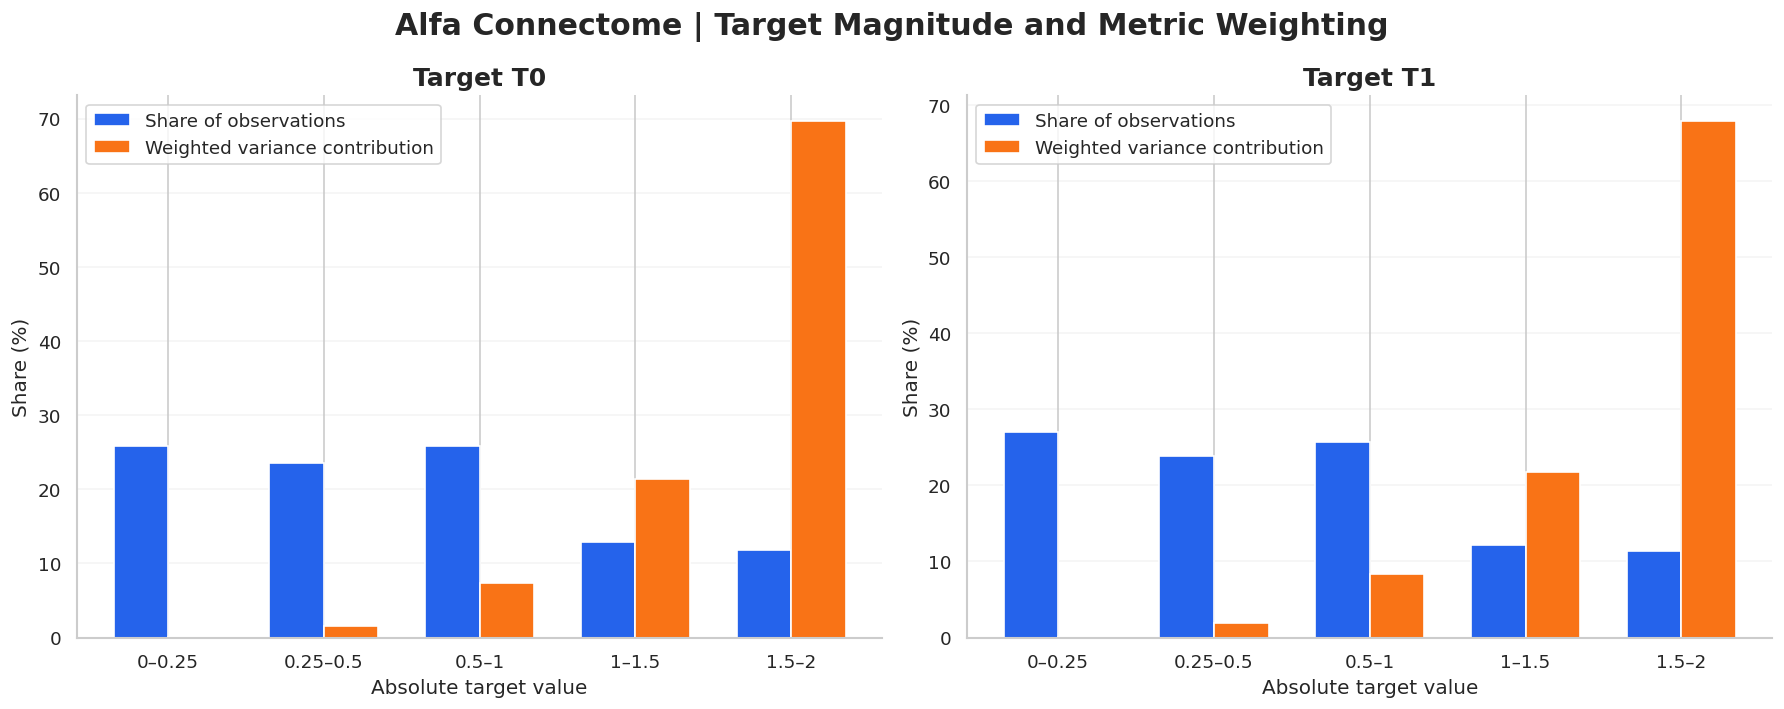

In [32]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng_metric = np.random.default_rng(2026)

metric_ids = rng_metric.choice(
    pf.num_row_groups,
    size=100,
    replace=False
)

targets = {"t0": [], "t1": []}

for idx in metric_ids:
    data = pf.read_row_group(
        int(idx),
        columns=["need_prediction", "t0", "t1"]
    ).to_pandas()

    mask = data["need_prediction"].to_numpy(dtype=bool)

    for target in targets:
        values = data[target].to_numpy(
            dtype=np.float64
        )[mask]

        values = np.clip(values, -2, 2)
        values = values[np.isfinite(values)]

        targets[target].append(values)

bins = [0, 0.25, 0.5, 1.0, 1.5, 2.000001]
labels = ["0–0.25", "0.25–0.5", "0.5–1", "1–1.5", "1.5–2"]

results = []

for target, parts in targets.items():
    y = np.concatenate(parts)

    w = np.abs(y)

    weighted_mean = np.average(y, weights=w)

    # Вклад в знаменатель взвешенной корреляции:
    # взвешенная сумма квадратов отклонений цели.
    variance_contrib = w * (y - weighted_mean) ** 2

    count, _ = np.histogram(np.abs(y), bins=bins)

    weight_sum, _ = np.histogram(
        np.abs(y), bins=bins, weights=w
    )

    variance_sum, _ = np.histogram(
        np.abs(y), bins=bins,
        weights=variance_contrib
    )

    for i, label in enumerate(labels):
        results.append({
            "target": target,
            "range": label,
            "row_share": 100 * count[i] / len(y),
            "weight_share": 100 * weight_sum[i] / w.sum(),
            "variance_share": (
                100 * variance_sum[i] / variance_contrib.sum()
            )
        })

    large = np.abs(y) >= 1.0

    print(f"\n=== {target.upper()} ===")
    print(f"Наблюдений: {len(y):,}")
    print(f"Взвешенное среднее: {weighted_mean:.4f}")
    print(f"Доля |target| >= 1: {large.mean():.2%}")

    print(
        "Вклад |target| >= 1 во взвешенную дисперсию:",
        f"{variance_contrib[large].sum() / variance_contrib.sum():.2%}"
    )

metric_df = pd.DataFrame(results)

print("\n=== ДЕТАЛЬНАЯ ДЕКОМПОЗИЦИЯ ===")
display(metric_df.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, target in zip(axes, ["t0", "t1"]):
    part = metric_df[metric_df["target"] == target]

    x = np.arange(len(labels))
    width = 0.35

    ax.bar(
        x - width / 2,
        part["row_share"],
        width,
        label="Share of observations",
        color="#2563EB"
    )

    ax.bar(
        x + width / 2,
        part["variance_share"],
        width,
        label="Weighted variance contribution",
        color="#F97316"
    )

    ax.set_xticks(x, labels)
    ax.set_xlabel("Absolute target value")
    ax.set_ylabel("Share (%)")
    ax.set_title(f"Target {target.upper()}")
    ax.legend()
    ax.grid(axis="y", alpha=0.2)

fig.suptitle(
    "Alfa Connectome | Target Magnitude and Metric Weighting",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



### 4.1. Влияние величины целевых переменных на взвешенную дисперсию

Исследованы 100 случайных последовательностей из `train.parquet`, содержащих 1 990 100 наблюдений после warmup.

Целевые значения ограничивались интервалом [-2, 2].

Для каждой цели вычислялся вклад наблюдений во взвешенную дисперсию:

\[
w_k(y_k-\bar y_w)^2,\qquad
w_k=|y_k|,
\]

где \(\bar y_w\) — взвешенное среднее целевой переменной.

#### Результаты

| Показатель | t0 | t1 |
|---|---:|---:|
| Взвешенное среднее | -0.4761 | -0.4589 |
| Доля строк с абсолютной целью >= 1 | 24.75% | 23.45% |
| Вклад этих строк во взвешенную дисперсию | 90.98% | 89.69% |
| Доля строк с абсолютной целью 1.5–2 | 11.85% | 11.35% |
| Вклад диапазона 1.5–2 | 69.65% | 67.89% |

#### Основные наблюдения

1. **Взвешенная дисперсия крайне неравномерно распределена между наблюдениями.** Около четверти строк формируют примерно 90% её величины.

2. **Особенно важны крупные абсолютные значения целей.** Диапазон 1.5–2 обеспечивает примерно 68–70% взвешенной дисперсии, несмотря на долю около 12% наблюдений.

3. **Малые значения цели вносят минимальный вклад во взвешенную дисперсию.** Около четверти наблюдений с абсолютной целью менее 0.25 формируют приблизительно 0.1% её величины.

4. **Взвешенные средние отрицательны для обеих целей.** Это указывает на асимметрию взвешенного распределения и требует дополнительной проверки.

#### Практические рекомендации

**Стоит:**
- Отдельно анализировать ошибки модели при крупных абсолютных значениях целей.
- Проверить подходы к обнаружению и прогнозированию крупных движений.
- Сравнивать разные функции потерь и стратегии обучения только по официальной метрике.
- Исследовать, насколько наблюдаемая концентрация сохраняется между последовательностями.
- Проверить качество моделей отдельно для положительных и отрицательных целей.

**Не стоит:**
- Оценивать качество модели исключительно по обычному MSE.
- Считать высокую точность на распространённых малых значениях гарантией высокого балла.
- Приравнивать вклад во взвешенную дисперсию к непосредственному вкладу в итоговую корреляцию.
- Повторять уже проведённые командой эксперименты с взвешенной функцией потерь без новой гипотезы.

#### Ограничения

Анализ выполнен на 100 случайных последовательностях `train.parquet`.

Официальная метрика дополнительно учитывает маску `is_scored` и зависит от совместного распределения истинных значений и предсказаний. Поэтому исследованная декомпозиция не является точной декомпозицией итогового балла.

**Статус:** сильная эмпирическая концентрация взвешенной дисперсии на крупных целевых значениях. Устойчивость между последовательностями требует проверки.


=== УСТОЙЧИВОСТЬ ПО ПОСЛЕДОВАТЕЛЬНОСТЯМ ===


large_variance_share                         large_row_share          \
                       mean  median     min     max            mean  median   
target                                                                        
t0                   0.8899  0.9115  0.6656  0.9742          0.2475  0.2410   
t1                   0.8784  0.8944  0.6398  0.9880          0.2345  0.2242   

                        
           min     max  
target                  
t0      0.0518  0.5352  
t1      0.0494  0.5105


Доля последовательностей с вкладом крупных целей > 80%:


,above_80
target,
t0,0.88
t1,0.84



Вклад положительных и отрицательных целей:


,target,negative_share,positive_share
0,t0,37.05,62.95
1,t1,38.18,61.82


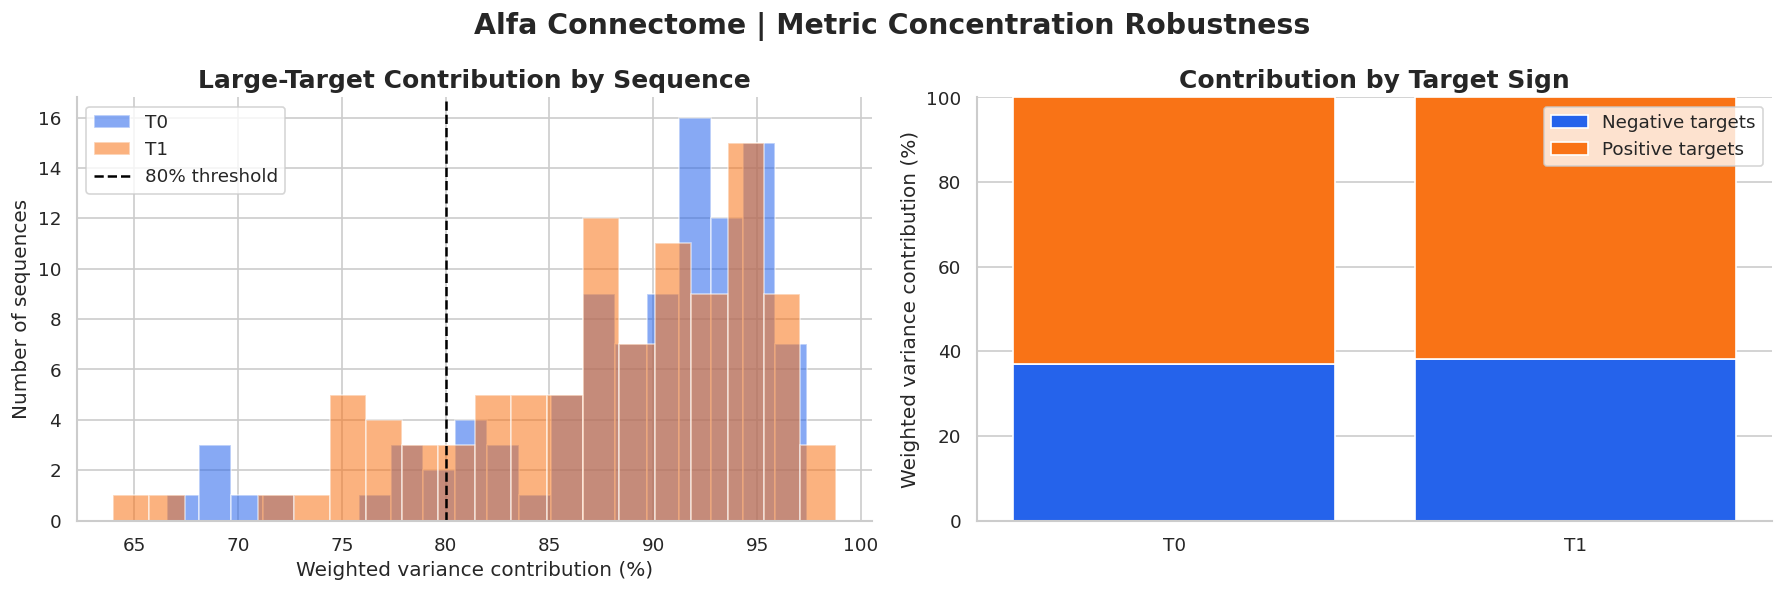

In [33]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sequence_results = []
sign_results = []

for target in ["t0", "t1"]:
    parts = targets[target]
    all_y = np.concatenate(parts)

    w = np.abs(all_y)
    weighted_mean = np.average(all_y, weights=w)

    total_contribution = 0
    negative_contribution = 0
    positive_contribution = 0

    for seq_idx, y in enumerate(parts):
        contribution = np.abs(y) * (y - weighted_mean) ** 2
        total = contribution.sum()

        if total > 0:
            sequence_results.append({
                "target": target,
                "sequence": int(metric_ids[seq_idx]),
                "large_variance_share": (
                    contribution[np.abs(y) >= 1].sum() / total
                ),
                "large_row_share": np.mean(np.abs(y) >= 1)
            })

        total_contribution += total
        negative_contribution += contribution[y < 0].sum()
        positive_contribution += contribution[y > 0].sum()

    sign_results.append({
        "target": target,
        "negative_share": (
            100 * negative_contribution / total_contribution
        ),
        "positive_share": (
            100 * positive_contribution / total_contribution
        )
    })

sequence_df = pd.DataFrame(sequence_results)
sign_df = pd.DataFrame(sign_results)

print("=== УСТОЙЧИВОСТЬ ПО ПОСЛЕДОВАТЕЛЬНОСТЯМ ===")
display(
    sequence_df.groupby("target")[
        ["large_variance_share", "large_row_share"]
    ].agg(["mean", "median", "min", "max"]).round(4)
)

print("\nДоля последовательностей с вкладом крупных целей > 80%:")
display(
    sequence_df.assign(
        above_80=sequence_df.large_variance_share > 0.8
    ).groupby("target")["above_80"].mean().round(4)
)

print("\nВклад положительных и отрицательных целей:")
display(sign_df.round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for target, color in [
    ("t0", "#2563EB"),
    ("t1", "#F97316")
]:
    values = (
        sequence_df.loc[
            sequence_df.target == target,
            "large_variance_share"
        ] * 100
    )

    axes[0].hist(
        values, bins=20, alpha=0.55,
        label=target.upper(), color=color
    )

axes[0].axvline(
    80, color="black", linestyle="--",
    label="80% threshold"
)
axes[0].set_title("Large-Target Contribution by Sequence")
axes[0].set_xlabel("Weighted variance contribution (%)")
axes[0].set_ylabel("Number of sequences")
axes[0].legend()

x = np.arange(len(sign_df))

axes[1].bar(
    x,
    sign_df["negative_share"],
    label="Negative targets",
    color="#2563EB"
)
axes[1].bar(
    x,
    sign_df["positive_share"],
    bottom=sign_df["negative_share"],
    label="Positive targets",
    color="#F97316"
)

axes[1].set_xticks(x, ["T0", "T1"])
axes[1].set_ylim(0, 100)
axes[1].set_ylabel("Weighted variance contribution (%)")
axes[1].set_title("Contribution by Target Sign")
axes[1].legend()

fig.suptitle(
    "Alfa Connectome | Metric Concentration Robustness",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



### 4.2. Устойчивость концентрации взвешенной дисперсии

Проверено, насколько вклад крупных абсолютных значений целей сохраняется между последовательностями.

Исследованы 100 случайных последовательностей из `train.parquet`. Для вычисления вкладов использовалось общее взвешенное среднее каждой цели по объединённой выборке.

#### Результаты

| Показатель | t0 | t1 |
|---|---:|---:|
| Средний вклад \|target\| >= 1 | 88.99% | 87.84% |
| Медианный вклад | 91.15% | 89.44% |
| Минимальный вклад | 66.56% | 63.98% |
| Максимальный вклад | 97.42% | 98.80% |
| Доля последовательностей с вкладом > 80% | 88% | 84% |

#### Асимметрия по знаку

| Направление цели | t0 | t1 |
|---|---:|---:|
| Отрицательные значения | 37.05% | 38.18% |
| Положительные значения | 62.95% | 61.82% |

#### Основные выводы

1. **Концентрация взвешенной дисперсии устойчива между последовательностями.** В подавляющем большинстве исследованных последовательностей значения с абсолютной величиной не менее 1 обеспечивают свыше 80% взвешенной дисперсии.

2. **Крупные значения целей имеют непропорционально высокое значение для статистики, лежащей в основе метрики.** Это подтверждает необходимость отдельной диагностики качества на таких событиях.

3. **Положительные значения дают больший вклад во взвешенную дисперсию.** Для обеих целей он составляет приблизительно 62–63%.

4. **Асимметрия вкладов не означает, что положительные цели автоматически важнее для итогового балла модели.** Взвешенная корреляция зависит также от предсказаний и их совместного распределения с истинными значениями.

#### Рекомендации

**Стоит:**
- Отдельно оценивать модель на малых и крупных абсолютных значениях целей.
- Анализировать качество по знаку целевой переменной.
- Проверять специализированные способы обработки крупных движений.
- Сравнивать эксперименты по официальной взвешенной корреляции.

**Не стоит:**
- Оптимизировать модель исключительно по обычному MSE.
- Автоматически усиливать положительные цели без проверки.
- Считать вклад во взвешенную дисперсию непосредственным вкладом в итоговый балл.

#### Ограничения

В анализе отсутствует официальная маска `is_scored`, поэтому результаты не являются точной декомпозицией конкурсной метрики.

Показатели рассчитаны на 100 последовательностях. При вычислении индивидуальных вкладов использовалось общее, а не отдельное для каждой последовательности взвешенное среднее.

**Статус:** эмпирическая закономерность подтверждена на расширенной выборке.


=== ЧЕТЫРЕ СЕМЕЙСТВА ПОСЛЕДОВАТЕЛЬНОСТЕЙ ===

Количество последовательностей:


,count
family,
F1,28
F2,25
F3,85
F4,102



Оценённые шаги дискретизации:


step_t0                    step_t1                  
         median      min      max   median      min      max
family                                                      
F1      0.12543  0.12543  0.12543  0.12543  0.12543  0.12543
F2      0.24133  0.24133  0.24133  0.24133  0.24133  0.24133
F3      0.46854  0.46854  0.46854  0.46854  0.46854  0.46854
F4      0.65687  0.65687  0.65687  0.65687  0.65687  0.65687


Доля крупных целей и частота изменений:


,large_t0_rate,large_t1_rate,t0_change_rate,t1_change_rate
family,,,,
F1,0.1872,0.2288,0.1510,0.1352
F2,0.1723,0.1694,0.1231,0.1233
F3,0.2816,0.2789,0.0415,0.0442
F4,0.2436,0.2392,0.0641,0.0694


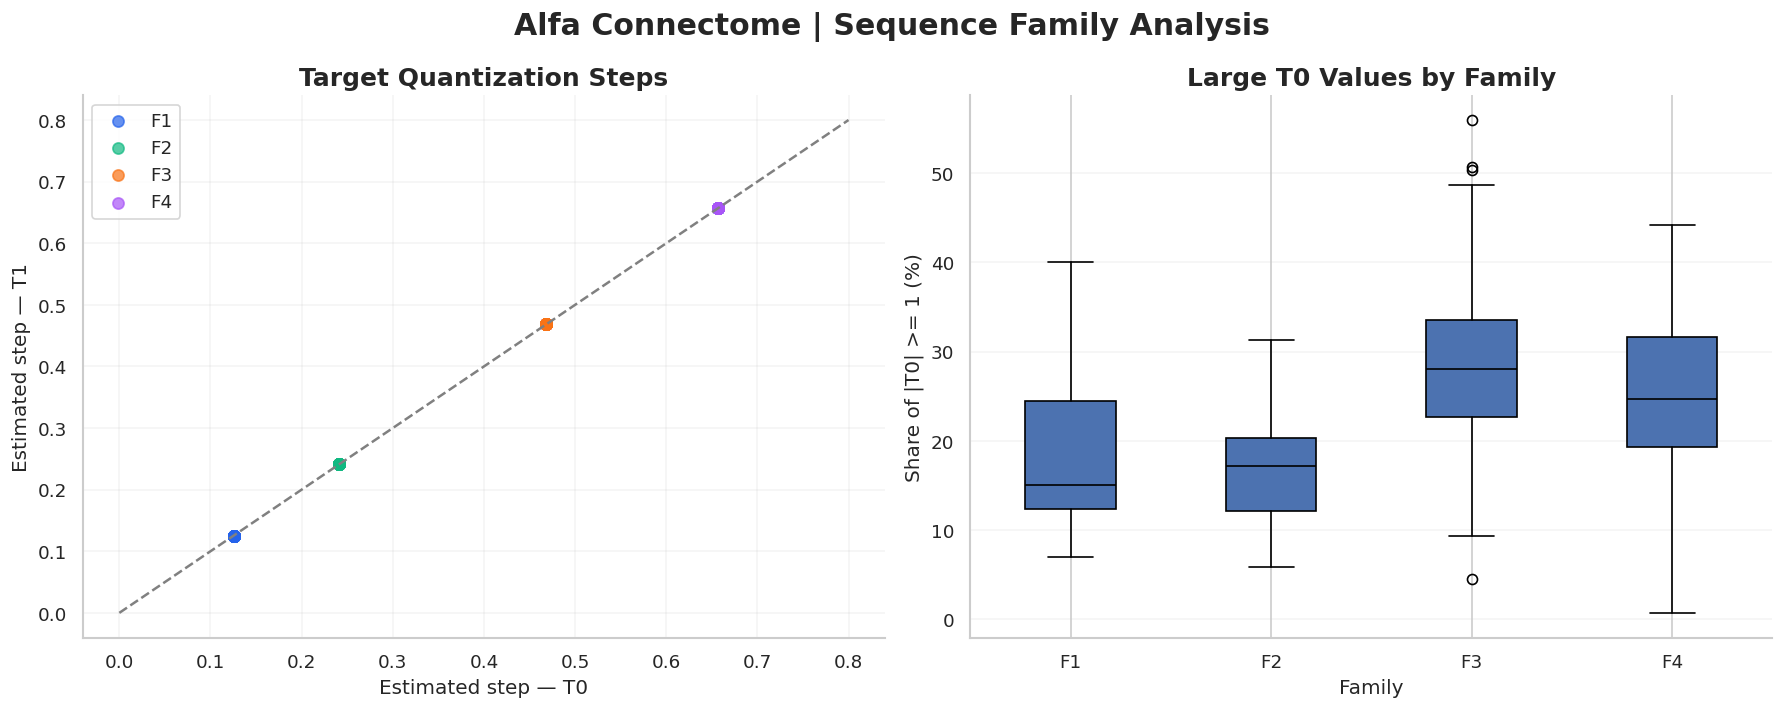

In [34]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)

N_SEQUENCES = 240

family_ids = rng.choice(
    pf.num_row_groups,
    size=N_SEQUENCES,
    replace=False
)

# Шаги дискретизации из предыдущего анализа команды
reference_steps = np.array([
    0.1254, 0.2413, 0.4685, 0.6569
])

def estimate_step(y):
    values = np.unique(np.round(y, 6))
    differences = np.diff(values)
    differences = differences[differences > 1e-4]

    if len(differences) == 0:
        return np.nan

    return float(differences.min())


records = []

for idx in family_ids:
    data = pf.read_row_group(
        int(idx),
        columns=["t0", "t1"]
    ).to_pandas()

    y0 = data["t0"].to_numpy(dtype=np.float64)[99:]
    y1 = data["t1"].to_numpy(dtype=np.float64)[99:]

    step0 = estimate_step(y0)
    step1 = estimate_step(y1)

    if np.isfinite(step0) and np.isfinite(step1):
        errors = (
            np.abs(reference_steps - step0) / reference_steps
            + np.abs(reference_steps - step1) / reference_steps
        ) / 2

        family_idx = int(np.argmin(errors))

        # Проверяем согласованность обеих целей
        good_match = (
            abs(step0 - reference_steps[family_idx])
            / reference_steps[family_idx] < 0.03
            and
            abs(step1 - reference_steps[family_idx])
            / reference_steps[family_idx] < 0.03
        )

        family = (
            f"F{family_idx + 1}"
            if good_match else "Unknown"
        )
    else:
        family = "Unknown"

    records.append({
        "sequence": int(idx),
        "family": family,
        "step_t0": step0,
        "step_t1": step1,
        "large_t0_rate": np.mean(np.abs(y0) >= 1),
        "large_t1_rate": np.mean(np.abs(y1) >= 1),
        "t0_change_rate": np.mean(np.diff(y0) != 0),
        "t1_change_rate": np.mean(np.diff(y1) != 0)
    })

family_df = pd.DataFrame(records)

print("=== ЧЕТЫРЕ СЕМЕЙСТВА ПОСЛЕДОВАТЕЛЬНОСТЕЙ ===")

print("\nКоличество последовательностей:")
display(family_df["family"].value_counts().sort_index())

print("\nОценённые шаги дискретизации:")
display(
    family_df.groupby("family")[
        ["step_t0", "step_t1"]
    ].agg(["median", "min", "max"]).round(5)
)

print("\nДоля крупных целей и частота изменений:")
display(
    family_df.groupby("family")[
        [
            "large_t0_rate",
            "large_t1_rate",
            "t0_change_rate",
            "t1_change_rate"
        ]
    ].mean().round(4)
)

# Визуализация
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

colors = {
    "F1": "#2563EB",
    "F2": "#10B981",
    "F3": "#F97316",
    "F4": "#A855F7",
    "Unknown": "#64748B"
}

for family, group in family_df.groupby("family"):
    axes[0].scatter(
        group["step_t0"],
        group["step_t1"],
        label=family,
        color=colors.get(family, "#64748B"),
        alpha=0.7,
        s=45
    )

axes[0].plot(
    [0, 0.8], [0, 0.8],
    linestyle="--", color="gray"
)

axes[0].set_title("Target Quantization Steps")
axes[0].set_xlabel("Estimated step — T0")
axes[0].set_ylabel("Estimated step — T1")
axes[0].legend()
axes[0].grid(alpha=0.2)

valid = family_df[
    family_df["family"] != "Unknown"
]

order = ["F1", "F2", "F3", "F4"]

data = [
    valid.loc[
        valid.family == f, "large_t0_rate"
    ].to_numpy() * 100
    for f in order
]

axes[1].boxplot(
    data,
    tick_labels=order,
    patch_artist=True,
    medianprops={"color": "black"}
)

axes[1].set_title("Large T0 Values by Family")
axes[1].set_xlabel("Family")
axes[1].set_ylabel("Share of |T0| >= 1 (%)")
axes[1].grid(axis="y", alpha=0.2)

fig.suptitle(
    "Alfa Connectome | Sequence Family Analysis",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



## 5. Анализ семейств последовательностей

### 5.1. Выявление четырёх семейств

Для исследования случайным образом отобраны 240 последовательностей из `train.parquet`.

Семейства определялись по минимальному положительному расстоянию между уникальными значениями целевых переменных. Классификация выполнялась отдельно для каждой последовательности и проверялась по обеим целям.

#### Результаты

| Семейство | Последовательностей | Шаг дискретизации | Доля крупных t0 | Частота изменений t0 | Частота изменений t1 |
|---|---:|---:|---:|---:|---:|
| F1 | 28 | 0.12543 | 18.72% | 15.10% | 13.52% |
| F2 | 25 | 0.24133 | 17.23% | 12.31% | 12.33% |
| F3 | 85 | 0.46854 | 28.16% | 4.15% | 4.42% |
| F4 | 102 | 0.65687 | 24.36% | 6.41% | 6.94% |

Все 240 последовательностей отнесены к одному из четырёх семейств. Для обеих целей внутри каждого семейства получены совпадающие шаги дискретизации.

#### Основные наблюдения

1. **Подтверждено существование четырёх чётко различимых семейств целевых переменных.** Каждое семейство характеризуется собственным шагом дискретизации.

2. **F1 и F2 имеют более высокую частоту изменений целей**, чем F3 и F4.

3. **F3 имеет наибольшую долю крупных значений t0** — 28.16%, несмотря на самую низкую частоту изменений.

4. **F3 и F4 преобладают в исследованной выборке.** Вместе они составляют около 77.9% последовательностей.

5. **Наблюдаемая неоднородность может влиять на качество прогнозирования.** Однако её связь с ошибками GRU ещё не исследована непосредственно.

#### Гипотезы

- Семейства могут отличаться статистикой доступных входных признаков.
- При возможности определить семейство по ранним входным наблюдениям модель могла бы учитывать информацию о режиме.
- Различия в дискретизации могут объяснять часть различий в частоте изменения целей.
- Раздельный анализ качества GRU по семействам может выявить систематические ошибки.

#### Практические рекомендации

**Стоит:**
- Проверить различимость семейств по наблюдаемым входным признакам.
- Исследовать статистики первых 99 шагов, доступных во время warmup.
- Сравнить качество прогнозов отдельно для F1–F4.
- Рассмотреть условное моделирование по семействам, только если семейство можно определять без истинных целей.

**Не стоит:**
- Использовать истинный номер семейства как вход модели при тестировании.
- Делать вывод о необходимости четырёх отдельных нейросетей без эксперимента.
- Считать различия в частоте изменений доказательством различий в рыночной активности.

#### Ограничения

Семейства определялись с использованием истинных целевых переменных исключительно для офлайн-анализа.

Исследованы 240 из 10 607 последовательностей. Частоты семейств и их свойства необходимо дополнительно проверить на независимых данных.

**Статус:** четыре семейства надёжно обнаружены в исследованной выборке. Их различимость по входным признакам пока неизвестна.


=== ПРИЗНАКИ WARMUP ПО СЕМЕЙСТВАМ ===
Последовательностей: 240


,i0_update,i1_update,i0_abs_delta,i1_abs_delta,a5_sentinel,a6_sentinel,a7_sentinel
family,,,,,,,
F1,0.42566,0.20007,0.03832,0.02046,0.14755,0.24639,0.51443
F2,0.28449,0.17837,0.03120,0.02141,0.31758,0.15354,0.59556
F3,0.11573,0.08127,0.01466,0.01102,0.08925,0.06322,0.31551
F4,0.19658,0.10874,0.02861,0.01498,0.09794,0.12299,0.29263


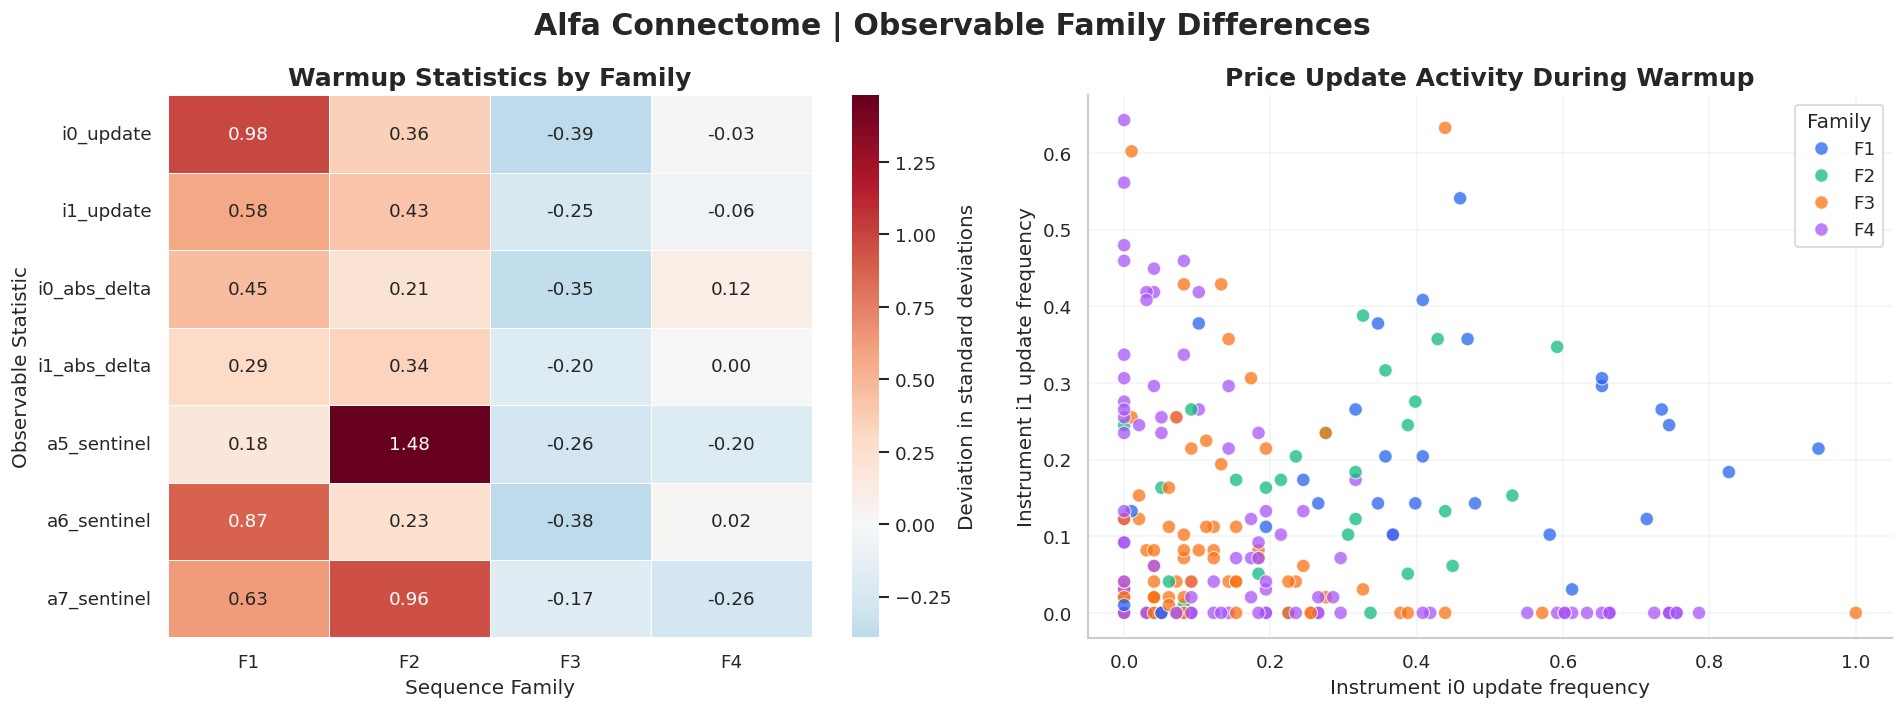

In [35]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

price0 = [f"i0_p{i}" for i in range(22)]
price1 = [f"i1_p{i}" for i in range(22)]
aux_cols = ["a5", "a6", "a7"]

warmup_records = []

for row in family_df.itertuples(index=False):
    table = pf.read_row_group(
        int(row.sequence),
        columns=price0 + price1 + aux_cols
    )

    # Только первые 99 шагов: 0 ... 98
    warmup = table.slice(0, 99).to_pandas()

    p0 = warmup[price0].to_numpy(dtype=np.float32)
    p1 = warmup[price1].to_numpy(dtype=np.float32)

    d0 = np.diff(p0, axis=0)
    d1 = np.diff(p1, axis=0)

    result = {
        "sequence": int(row.sequence),
        "family": row.family,
        "i0_update": (np.abs(d0) > 1e-6).any(axis=1).mean(),
        "i1_update": (np.abs(d1) > 1e-6).any(axis=1).mean(),
        "i0_abs_delta": np.abs(d0).mean(),
        "i1_abs_delta": np.abs(d1).mean(),
    }

    for col in aux_cols:
        values = warmup[col].to_numpy(dtype=np.float32)
        result[f"{col}_sentinel"] = np.isclose(
            values, -5.199337, rtol=0, atol=1e-5
        ).mean()

    warmup_records.append(result)

warmup_df = pd.DataFrame(warmup_records)

metrics = [
    "i0_update",
    "i1_update",
    "i0_abs_delta",
    "i1_abs_delta",
    "a5_sentinel",
    "a6_sentinel",
    "a7_sentinel",
]

family_means = (
    warmup_df.groupby("family")[metrics]
    .mean()
    .reindex(["F1", "F2", "F3", "F4"])
)

print("=== ПРИЗНАКИ WARMUP ПО СЕМЕЙСТВАМ ===")
print("Последовательностей:", len(warmup_df))
display(family_means.round(5))

# Стандартизуем только для визуализации различий
overall_mean = warmup_df[metrics].mean()
overall_std = warmup_df[metrics].std(ddof=0).replace(0, 1)

heatmap_data = (
    family_means - overall_mean
) / overall_std

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(
    heatmap_data.T,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    linewidths=0.5,
    ax=axes[0],
    cbar_kws={"label": "Deviation in standard deviations"}
)

axes[0].set_title("Warmup Statistics by Family")
axes[0].set_xlabel("Sequence Family")
axes[0].set_ylabel("Observable Statistic")

palette = {
    "F1": "#2563EB",
    "F2": "#10B981",
    "F3": "#F97316",
    "F4": "#A855F7",
}

sns.scatterplot(
    data=warmup_df,
    x="i0_update",
    y="i1_update",
    hue="family",
    hue_order=["F1", "F2", "F3", "F4"],
    palette=palette,
    alpha=0.75,
    s=65,
    ax=axes[1]
)

axes[1].set_title("Price Update Activity During Warmup")
axes[1].set_xlabel("Instrument i0 update frequency")
axes[1].set_ylabel("Instrument i1 update frequency")
axes[1].legend(title="Family")
axes[1].grid(alpha=0.2)

fig.suptitle(
    "Alfa Connectome | Observable Family Differences",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



### 5.2. Различия между семействами по наблюдаемым признакам

Исследованы первые 99 временных шагов 240 последовательностей из `train.parquet`.

Для каждой последовательности вычислены:
- Частоты обновления ценовых признаков инструментов i0 и i1.
- Средние абсолютные изменения ценовых признаков.
- Частоты специального значения -5.199337 в a5, a6, a7.

Метки семейств определены по истинным целевым переменным исключительно для офлайн-анализа. Все анализируемые входные статистики рассчитаны только по первым 99 шагам.

#### Основные результаты

| Показатель | F1 | F2 | F3 | F4 |
|---|---:|---:|---:|---:|
| Частота обновлений i0 | 42.57% | 28.45% | 11.57% | 19.66% |
| Частота обновлений i1 | 20.01% | 17.84% | 8.13% | 10.87% |
| Среднее абсолютное изменение i0 | 0.0383 | 0.0312 | 0.0147 | 0.0286 |
| Частота маркера a5 | 14.76% | 31.76% | 8.93% | 9.79% |
| Частота маркера a7 | 51.44% | 59.56% | 31.55% | 29.26% |

#### Наблюдения

1. **Семейства различаются статистикой доступных входных признаков.** Наиболее выраженные различия обнаружены в активности обновлений цен.

2. **F1 характеризуется высокой активностью ценовых признаков**, тогда как F3 демонстрирует наиболее низкие средние значения соответствующих показателей.

3. **F2 выделяется частотой специального значения в a5.**

4. **F3 и F4 имеют частично сходные характеристики.** На диаграмме рассеяния присутствует существенное перекрытие наблюдений разных семейств.

#### Интерпретация

Полученные результаты подтверждают, что различия между семействами не ограничиваются распределениями целевых переменных: они проявляются и в наблюдаемых входных данных.

Следовательно, информация о семействе потенциально может быть восстановлена без использования истинных целей.

Однако различия групповых средних не гарантируют точной классификации отдельных последовательностей.

#### Практические рекомендации

**Стоит:**
- Проверить классификацию семейств по первым 99 шагам.
- Сравнить линейный и нелинейный классификаторы.
- Оценивать качество по каждому семейству отдельно.
- Использовать только признаки, доступные к моменту прогнозирования.

**Не стоит:**
- Передавать истинные метки семейств в тестовую модель.
- Считать различия средних доказательством высокой точности классификатора.
- Сразу обучать отдельные GRU для четырёх семейств без проверки качества классификации.

#### Ограничения

Исследованы 240 последовательностей, причём метки семейств получены из истинных целевых значений.

Различимость семейств на независимых последовательностях пока не оценивалась.

**Статус:** выявлены различия наблюдаемых входных признаков; требуется проверка классифицируемости.


=== КЛАССИФИКАЦИЯ СЕМЕЙСТВ ПО WARMUP ===


,model,accuracy,balanced_accuracy,macro_f1
0,Majority baseline,0.4250,0.2500,0.1491
1,Logistic Regression,0.6375,0.6824,0.6582
2,Random Forest,0.6083,0.5886,0.5918



=== RANDOM FOREST: КАЧЕСТВО ПО СЕМЕЙСТВАМ ===
              precision    recall  f1-score   support

          F1       0.60      0.54      0.57        28
          F2       0.56      0.56      0.56        25
          F3       0.56      0.67      0.61        85
          F4       0.67      0.59      0.63       102

    accuracy                           0.61       240
   macro avg       0.60      0.59      0.59       240
weighted avg       0.61      0.61      0.61       240



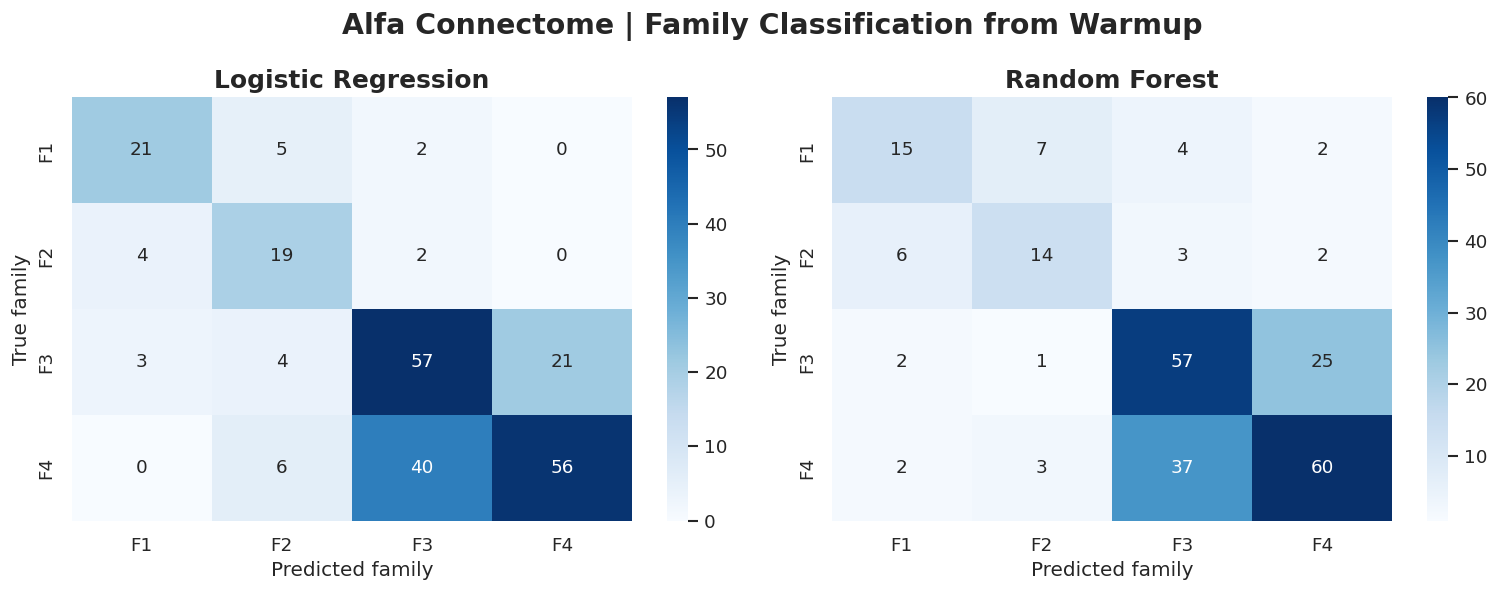

In [36]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

feature_names = [
    "i0_update",
    "i1_update",
    "i0_abs_delta",
    "i1_abs_delta",
    "a5_sentinel",
    "a6_sentinel",
    "a7_sentinel"
]

X = warmup_df[feature_names].copy()
y = warmup_df["family"].copy()

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Majority baseline": DummyClassifier(
        strategy="most_frequent"
    ),
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced"
        )
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=250,
        max_depth=6,
        min_samples_leaf=3,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    )
}

predictions = {}
results = []

for name, model in models.items():
    pred = cross_val_predict(
        model, X, y, cv=cv
    )

    predictions[name] = pred

    results.append({
        "model": name,
        "accuracy": accuracy_score(y, pred),
        "balanced_accuracy": balanced_accuracy_score(y, pred),
        "macro_f1": f1_score(y, pred, average="macro")
    })

results_df = pd.DataFrame(results)

print("=== КЛАССИФИКАЦИЯ СЕМЕЙСТВ ПО WARMUP ===")
display(results_df.round(4))

labels = ["F1", "F2", "F3", "F4"]

print("\n=== RANDOM FOREST: КАЧЕСТВО ПО СЕМЕЙСТВАМ ===")
print(
    classification_report(
        y,
        predictions["Random Forest"],
        labels=labels,
        zero_division=0
    )
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, name in zip(
    axes,
    ["Logistic Regression", "Random Forest"]
):
    cm = confusion_matrix(
        y, predictions[name], labels=labels
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted family")
    ax.set_ylabel("True family")

fig.suptitle(
    "Alfa Connectome | Family Classification from Warmup",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



### 5.3. Классификация семейств по первым 99 шагам

Проведён эксперимент по определению семейства последовательности на основе семи статистик доступных входных признаков.

Использованы:
- Частоты обновления цен инструментов i0 и i1.
- Средние абсолютные изменения цен обоих инструментов.
- Частоты специального значения -5.199337 в a5, a6, a7.

Истинные метки семейств получены по целевым переменным исключительно для обучения и оценки классификаторов. В качестве входов использованы только первые 99 наблюдений.

Для оценки применена пятикратная стратифицированная кросс-валидация по последовательностям.

#### Результаты

| Модель | Accuracy | Balanced Accuracy | Macro F1 |
|---|---:|---:|---:|
| Majority baseline | 42.50% | 25.00% | 0.1491 |
| Logistic Regression | 63.75% | 68.24% | 0.6582 |
| Random Forest | 60.83% | 58.86% | 0.5918 |

#### Основные выводы

1. **Семейства частично определяются по доступным входным признакам.** Логистическая регрессия значительно превосходит классификатор большинства.

2. **Логистическая регрессия показала лучший результат среди трёх проверенных моделей.** Более сложный Random Forest не обеспечил улучшения.

3. **F1 и F2 распознаются относительно хорошо.** Recall логистической регрессии составляет 75% и 76% соответственно.

4. **Основная сложность — разделение F3 и F4.** Из 102 последовательностей F4 классификатор ошибочно относит 40 к F3.

5. **Информация о семействе потенциально доступна уже после warmup.** Это создаёт возможность использовать предсказанные вероятности семейств при прогнозировании целевых переменных.

#### Практические рекомендации

**Стоит:**
- Проверить устойчивость классификации на новых последовательностях.
- Рассмотреть вероятности четырёх семейств как дополнительные признаки общей модели.
- Проверить улучшение официальной метрики при добавлении информации о семействе.
- Исследовать дополнительные статистики для различения F3 и F4.

**Не стоит:**
- Использовать истинное семейство при тестовом прогнозировании.
- Сразу обучать четыре отдельные GRU.
- Считать точность классификации семейств доказательством улучшения прогнозов t0 и t1.
- Усложнять классификатор без независимой проверки.

#### Ограничения

Эксперимент проведён на 240 последовательностях. Оценка получена с помощью кросс-валидации; отдельная независимая тестовая выборка пока не использовалась.

**Статус:** перспективная гипотеза, требующая независимой проверки.


=== НЕЗАВИСИМАЯ ПРОВЕРКА ===
Обучающих последовательностей: 240
Тестовых последовательностей: 399


,model,accuracy,balanced_accuracy,macro_f1
0,Majority baseline,0.4211,0.2500,0.1481
1,Logistic Regression,0.6341,0.6924,0.6520



Количество последовательностей по семействам:


,count
family,
F1,57
F2,42
F3,132
F4,168



Качество логистической регрессии:
              precision    recall  f1-score   support

          F1       0.78      0.81      0.79        57
          F2       0.50      0.76      0.60        42
          F3       0.56      0.74      0.64       132
          F4       0.76      0.46      0.57       168

    accuracy                           0.63       399
   macro avg       0.65      0.69      0.65       399
weighted avg       0.67      0.63      0.63       399



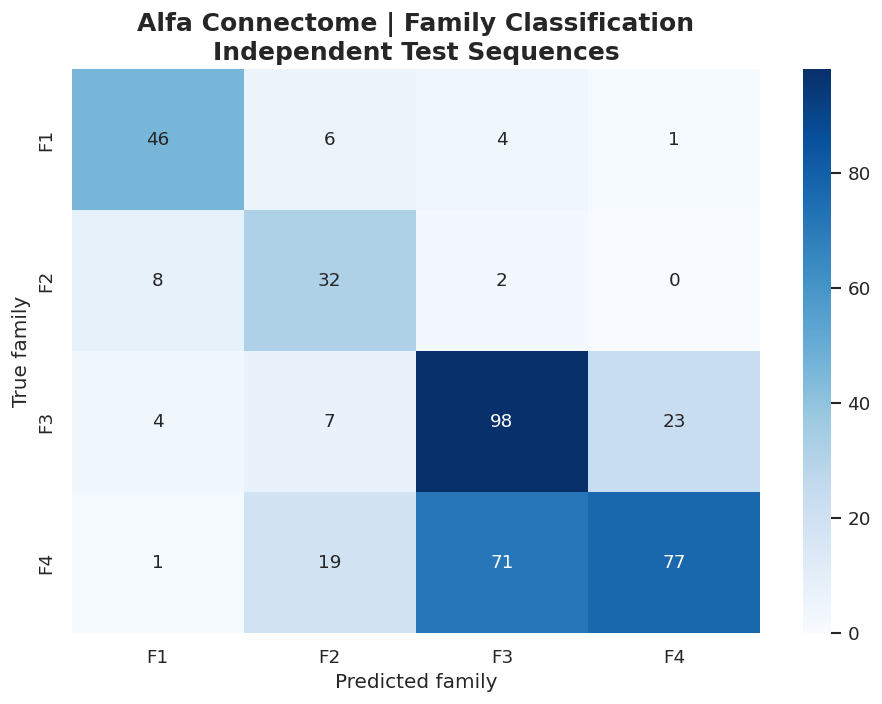

In [37]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

FEATURES = [
    "i0_update",
    "i1_update",
    "i0_abs_delta",
    "i1_abs_delta",
    "a5_sentinel",
    "a6_sentinel",
    "a7_sentinel"
]

price0 = [f"i0_p{i}" for i in range(22)]
price1 = [f"i1_p{i}" for i in range(22)]

# Исключаем все 240 исследованных последовательностей
used_ids = family_df["sequence"].to_numpy(dtype=int)

available = np.setdiff1d(
    np.arange(pf.num_row_groups),
    used_ids
)

rng_test = np.random.default_rng(2027)

test_ids = rng_test.choice(
    available,
    size=400,
    replace=False
)

records = []

for idx in test_ids:
    cols = (
        price0 + price1
        + ["a5", "a6", "a7", "t0", "t1"]
    )

    data = pf.read_row_group(
        int(idx),
        columns=cols
    ).to_pandas()

    # Истинное семейство: только для оценки качества
    step0 = estimate_step(data["t0"].to_numpy()[99:])
    step1 = estimate_step(data["t1"].to_numpy()[99:])

    if not (np.isfinite(step0) and np.isfinite(step1)):
        continue

    errors = (
        np.abs(reference_steps - step0) / reference_steps
        + np.abs(reference_steps - step1) / reference_steps
    ) / 2

    family_idx = int(np.argmin(errors))

    if (
        abs(step0 - reference_steps[family_idx])
        / reference_steps[family_idx] >= 0.03
        or abs(step1 - reference_steps[family_idx])
        / reference_steps[family_idx] >= 0.03
    ):
        continue

    # Только первые 99 входных наблюдений
    warmup = data.iloc[:99]

    p0 = warmup[price0].to_numpy(dtype=np.float32)
    p1 = warmup[price1].to_numpy(dtype=np.float32)

    d0 = np.diff(p0, axis=0)
    d1 = np.diff(p1, axis=0)

    row = {
        "family": f"F{family_idx + 1}",
        "i0_update": (np.abs(d0) > 1e-6).any(axis=1).mean(),
        "i1_update": (np.abs(d1) > 1e-6).any(axis=1).mean(),
        "i0_abs_delta": np.abs(d0).mean(),
        "i1_abs_delta": np.abs(d1).mean()
    }

    for col in ["a5", "a6", "a7"]:
        row[f"{col}_sentinel"] = np.isclose(
            warmup[col].to_numpy(),
            -5.199337,
            rtol=0,
            atol=1e-5
        ).mean()

    records.append(row)

test_df = pd.DataFrame(records)

X_train = warmup_df[FEATURES]
y_train = warmup_df["family"]

X_test = test_df[FEATURES]
y_test = test_df["family"]

models = {
    "Majority baseline": DummyClassifier(
        strategy="most_frequent"
    ),
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced"
        )
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "balanced_accuracy": balanced_accuracy_score(
            y_test, pred
        ),
        "macro_f1": f1_score(
            y_test, pred, average="macro"
        )
    })

    if name == "Logistic Regression":
        final_pred = pred

print("=== НЕЗАВИСИМАЯ ПРОВЕРКА ===")
print("Обучающих последовательностей:", len(X_train))
print("Тестовых последовательностей:", len(X_test))

display(pd.DataFrame(results).round(4))

print("\nКоличество последовательностей по семействам:")
display(y_test.value_counts().sort_index())

print("\nКачество логистической регрессии:")
print(
    classification_report(
        y_test, final_pred,
        labels=["F1", "F2", "F3", "F4"],
        zero_division=0
    )
)

cm = confusion_matrix(
    y_test,
    final_pred,
    labels=["F1", "F2", "F3", "F4"]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["F1", "F2", "F3", "F4"],
    yticklabels=["F1", "F2", "F3", "F4"]
)

plt.title(
    "Alfa Connectome | Family Classification\n"
    "Independent Test Sequences"
)
plt.xlabel("Predicted family")
plt.ylabel("True family")
plt.tight_layout()
plt.show()



### 5.4. Независимая проверка классификации семейств

Для проверки устойчивости результатов логистическая регрессия обучена на 240 ранее исследованных последовательностях и протестирована на новых последовательностях из `train.parquet`.

Из 400 выбранных тестовых последовательностей 399 удалось классифицировать по шагу дискретизации целевых переменных.

Пересечений с обучающей выборкой нет.

Классификатор использовал исключительно семь статистик, рассчитанных по первым 99 входным наблюдениям. Истинные цели применялись только для определения правильных меток семейств при оценке.

#### Результаты

| Метрика | Кросс-валидация | Независимая проверка |
|---|---:|---:|
| Accuracy | 63.75% | 63.41% |
| Balanced Accuracy | 68.24% | 69.24% |
| Macro F1 | 0.6582 | 0.6520 |

На независимой выборке baseline, всегда предсказывающий наиболее частое семейство, получил Accuracy 42.11% и Balanced Accuracy 25%.

#### Качество по семействам

| Семейство | Precision | Recall | F1 |
|---|---:|---:|---:|
| F1 | 0.78 | 0.81 | 0.79 |
| F2 | 0.50 | 0.76 | 0.60 |
| F3 | 0.56 | 0.74 | 0.64 |
| F4 | 0.76 | 0.46 | 0.57 |

#### Основные выводы

1. **Различимость семейств по наблюдаемым признакам подтверждена на новых последовательностях.** Качество классификации практически совпало с результатами кросс-валидации.

2. **Уже первые 99 шагов содержат информацию о семействе.** Семь простых статистик позволяют получить Balanced Accuracy 69.24%, заметно превосходя baseline.

3. **Наиболее уверенно распознаётся F1.** Его Recall составляет около 81%.

4. **Основная проблема — различение F3 и F4.** Из 168 последовательностей F4 71 ошибочно отнесена к F3.

5. **Результат создаёт возможность условного моделирования.** Вероятности семейств потенциально могут использоваться как дополнительные признаки нейросети.

#### Рекомендации

**Стоит:**
- Проверить передачу вероятностей семейств в общую GRU.
- Сравнить качество с обычной GRU без таких признаков.
- Исследовать дополнительные признаки, позволяющие различать F3 и F4.
- Оценить затраты времени на вычисление статистик и работу классификатора.

**Не стоит:**
- Использовать истинные метки семейств в тестовом инференсе.
- Предполагать, что классификация семейств автоматически повысит конкурсную метрику.
- Использовать жёсткие предсказанные метки без сравнения с вероятностным представлением.
- Обучать отдельную модель для каждого семейства без проверки качества и вычислительных ограничений.

#### Ограничения

Независимая проверка проведена на 399 новых последовательностях из `train.parquet`, а не на официальной валидационной выборке.

Качество классификации семейств не равно качеству прогнозирования `t0` и `t1`.

Одна из 400 последовательностей не получила метку по принятому правилу дискретизации; причину необходимо проверить отдельно.

**Статус: гипотеза о возможности определения семейств по warmup подтверждена на независимой выборке. Влияние на качество GRU не проверено.**


## 6. Итоговые выводы EDA и рекомендации по моделированию

### 6.1. Общие результаты

В ходе исследования рассмотрены временная структура целевых переменных, их совместная динамика, распределение значений, статистические свойства 112 входных признаков, корреляционные зависимости, специальные значения, структура обновлений цен, эффективная размерность и различия между четырьмя семействами последовательностей.

Анализ выполнен на выборках последовательностей из `train.parquet`. В отдельных экспериментах использовалось от 30 до 640 последовательностей, причём классификатор семейств проверялся на независимой от обучающей выборке из 399 последовательностей.

**Основные выводы:**

1. **Целевые переменные имеют выраженную дискретную и временную структуру.** Их значения принадлежат четырём характерным сеткам, а изменения преимущественно ступенчатые. Совместные изменения целей чаще происходят в противоположных направлениях.

2. **Крупные значения целей доминируют во взвешенной дисперсии.** Примерно 24% наблюдений с абсолютными значениями не менее 1 обеспечивают около 90% взвешенной дисперсии. Эта концентрация сохраняется в большинстве исследованных последовательностей.

3. **Первый инструмент является основным источником линейных связей с целями.** Особенно выделяются ценовые и объёмные признаки `i0`. Для ряда ценовых признаков обнаружена устойчивая направленная корреляция с целями между последовательностями.

4. **Ценовые признаки обладают групповой структурой обновлений.** Внутри каждого инструмента ценовые каналы часто изменяются одновременно, тогда как между инструментами события обновления преимущественно асинхронны.

5. **Входные признаки содержат низкоразмерную корреляционную структуру.** PCA показывает, что для сохранения 95% изменчивости ценовых признаков необходимо 8–10 компонент вместо исходных 22 на инструмент. Однако это не гарантирует сохранение прогностической информации.

6. **Специальное значение -5.199337 статистически информативно.** Его появление в `a5`, `a6`, `a7` связано с вероятностью крупных целевых значений, причём эффекты имеют различные направления.

7. **Четыре семейства различаются не только целями, но и наблюдаемыми входными признаками.** По первым 99 шагам возможно частичное определение семейства даже на основе семи агрегированных статистик. Независимая проверка простого классификатора дала Accuracy 63.41% и Balanced Accuracy 69.24%. Командные эксперименты с более широким набором статистик показывают существенно более высокую точность классификации.

### 6.2. Связь результатов EDA с существующими моделями

Сопоставление результатов с командными экспериментами показывает, что часть обнаруженных закономерностей уже учитывается существующими решениями.

В частности, команда использует взвешенную функцию потерь, исследовала дискретную структуру целей, пробовала добавление разностей признаков, передачу информации о семействе, бинарные индикаторы специальных значений, изменение архитектуры и увеличение объёма обучающих данных.

Наиболее заметное улучшение качества наблюдалось при масштабировании обучения. Усложнение архитектуры и добавление отдельных простых признаков не обеспечивали столь же устойчивого прироста.

Особенно сложным остаётся четвёртое семейство, на котором ранее наблюдалось существенное снижение качества прогнозирования. С учётом высокой представленности этого семейства среди оцениваемых наблюдений оно заслуживает отдельного анализа ошибок.

### 6.3. Приоритетные направления дальнейшей работы

**Приоритет 1. Анализ ошибок текущей лучшей модели.**

Необходимо получить предсказания GRU/LSTM на независимой размеченной выборке и исследовать ошибки по семействам, абсолютной величине и знаку целей, а также в зависимости от событий обновления цен.

**Приоритет 2. Конструирование компактных причинных признаков.**

Представляется перспективным проверить агрегированные характеристики bid/ask-сторон стакана, статистики объёмов, индикаторы обновления каждого инструмента, время с последнего обновления и краткосрочные скользящие статистики.

Такие признаки должны вычисляться только из текущего и предыдущих состояний.

**Приоритет 3. Исследование сложных событий четвёртого семейства.**

Следует определить, какие доступные признаки предшествуют наиболее сложным состояниям, и проверить целесообразность специальных обучающих механизмов без отказа от общей регрессионной модели.

**Приоритет 4. Независимая проверка улучшений.**

Каждую гипотезу необходимо тестировать на одинаковых данных и сравнивать с базовой моделью по официальной глобальной взвешенной корреляции на `is_scored`-строках. Дополнительно следует учитывать вычислительные ограничения платформы.

### 6.4. Что не рекомендуется делать

Не следует автоматически удалять признаки с низкой индивидуальной корреляцией, считать синхронность обновлений доказательством избыточности, заменять специальные значения нулями, использовать истинные цели или метки семейств при тестовом прогнозировании.

Также нецелесообразно без новых оснований повторять уже проверенные командой эксперименты, не обеспечившие улучшения: простое добавление всех разностей, бинарных индикаторов специальных значений, жёстких меток семейств и увеличение размера GRU.

### 6.5. Заключение

Проведённый EDA выявил существенную неоднородность последовательностей, структурированные зависимости между входными признаками и концентрацию взвешенной дисперсии целей на относительно небольшой части наблюдений.

**Основная практическая ценность анализа заключается в формировании проверяемых гипотез о новых причинных признаках и выделении наиболее проблемных режимов прогнозирования.**

Сам по себе статистический анализ не повышает конкурсную метрику. Его результаты должны использоваться для постановки контролируемых модельных экспериментов, анализа ошибок и обоснованного выбора направлений дальнейшей работы.

Наиболее перспективным продолжением является исследование информации, содержащейся в агрегированных характеристиках стакана и событиях его обновления, с последующей проверкой их влияния на качество и скорость существующих GRU/LSTM-моделей.